# Previsione dell'esito di una partita di scacchi (Lichess)

## Obiettivo
Costruire un modello che stimi la probabilità di vittoria del Bianco, del Nero o di patta in una partita di scacchi online, usando solo informazioni disponibili prima dell'inizio (rating, formato di gioco, tipo di partita). Il modello è pensato per:
- mostrare una probabilità pre-partita credibile e ben calibrata ai giocatori nella lobby e agli spettatori;
- fornire al team matchmaking uno strumento per capire quali fattori spiegano gli upset (vittoria del giocatore con rating inferiore).

## Dataset
Chess Game Dataset (Lichess), ~20.000 partite con esito finale (`winner`: white / black / draw) e informazioni pre-partita (rating, apertura, tempo, rated/casual).
## Metodo
1. **Esplorazione (EDA)**: distribuzione degli esiti, relazione rating-esito, associazione apertura-esito, differenze rated/non rated, tempo di gioco, qualità del dataset (giocatori ripetuti, drift temporale).
2. **Preparazione dati e feature**: split temporale (train = partite vecchie, test = partite recenti), pulizia, feature derivate (`rating_diff`, `rating_mean`, `rating_min`, `rating_max`, `time_total_estimate`), scaling fittato solo sul train interno.
3. **Modellazione**: confronto tra regressione logistica, alberi (Decision Tree, Random Forest con `max_depth=10`), boosting (Gradient Boosting conservativo) e rete neurale (MLP), selezionati e calibrati sulla validation temporale, con il test come holdout finale. Valutazione con Log Loss, Brier Score, ECE e matrici di confusione. Versione binaria per la rilevazione degli upset con soglia scelta consapevolmente.
4. **Interpretazione e conclusioni**: feature importance (coefficienti della Regressione Logistica), indicazioni operative per prodotto e matchmaking, piano di monitoraggio e ri-allenamento.
5. **Pipeline serializzabile**: funzione di inferenza pronta all'uso, basata sul modello scelto.

## Risultati principali
- Il **divario di rating** (`rating_diff`) è il segnale più forte: nella Regressione Logistica ha il coefficiente medio più alto in valore assoluto (|coeff| medio 0,2407).
- Il modello scelto è la **Regressione Logistica**: sulla validation temporale ha il miglior ECE per la classe `draw` a parità sostanziale di Log Loss e Brier Score con gli altri modelli candidati; sul test, valutato una sola volta come stima indipendente, ottiene Log Loss 0,7876, Brier Score 0,1622, Accuracy 0,6064, ECE medio 0,0184 ed ECE `draw` 0,0018.
- La **classe draw** rimane difficile da predire (circa il 4,7% degli esiti); non viene applicato un bilanciamento aggressivo (class_weight, sample_weight o resampling), perché peggiora le metriche probabilistiche senza migliorare il riconoscimento delle patte.
- La **calibrazione esplicita** (isotonic e Platt scaling) è stata testata sulla Regressione Logistica ma non applicata: entrambe peggiorano l'ECE medio sul test (da 0,0184 a 0,0248 con isotonic e a 0,0364 con Platt); il modello resta quindi non calibrato esplicitamente.
- Le decisioni di modeling (scelta del modello, gestione dello sbilanciamento, calibrazione) sono prese sulla validation temporale; il test resta un holdout finale, consultato una sola volta per ciascuna valutazione indipendente (modello multiclass, modello binario, calibrazione).

## Limiti dichiarati
La classe `draw` non viene mai predetta in modo hard dal modello scelto; il drift temporale (es. tasso di upset dal 34,28% nel train al 36,49% nel test) è un segnale da monitorare; le differenze tra i modelli candidati non sono accompagnate da una stima dell'incertezza (intervalli di confidenza, bootstrap); le decisioni si basano su un singolo split temporale train/validazione/test. Tutti i limiti sono elencati nelle sezioni "Limiti metodologici" e "Limiti residui e lavoro futuro".

## Struttura del notebook
- Step 1 — Esplorazione dei dati (EDA)
- Step 2 — Preparazione dati e costruzione feature
- Step 3 — Modellazione: costruzione, confronto, valutazione
- Step 4 — Interpretazione e conclusioni
- Step 5 — Pipeline serializzabile e funzione di inferenza

## Step 1 — Esplorazione dei dati (EDA)

In [33]:
import pandas as pd

# Elenca le colonne necessarie per le analisi successive.
colonne_attese = {
    'id', 'rated', 'created_at', 'last_move_at', 'turns', 'victory_status',
    'winner', 'increment_code', 'white_id', 'white_rating', 'black_id',
    'black_rating', 'moves', 'opening_eco', 'opening_name', 'opening_ply'
}

try:
    # Carica il dataset dal file CSV.
    df = pd.read_csv('games.csv')
except FileNotFoundError:
    print("Errore: il file 'games.csv' non è stato trovato.")
except (pd.errors.ParserError, OSError, UnicodeDecodeError) as errore:
    print(f"Errore nella lettura o nel parsing di 'games.csv': {errore}")
else:
    # Verifica che il dataset contenga tutte le colonne richieste.
    colonne_mancanti = colonne_attese - set(df.columns)
    if colonne_mancanti:
        print(f"Errore nello schema: mancano le colonne {sorted(colonne_mancanti)}.")
    else:
        print("Dataset caricato e schema validato con successo.")

Dataset caricato e schema validato con successo.


In [34]:
# Visualizza le informazioni di base sul dataset
print("\nDimensioni del dataset:")
display(df.shape)

print("\nTipi di dato:")
display(df.dtypes)

print("\nPrime 5 righe:")
display(df.head())

print("\nStatistiche descrittive:")
display(df.describe(include='all'))


Dimensioni del dataset:


(20058, 16)


Tipi di dato:


id                 object
rated                bool
created_at        float64
last_move_at      float64
turns               int64
victory_status     object
winner             object
increment_code     object
white_id           object
white_rating        int64
black_id           object
black_rating        int64
moves              object
opening_eco        object
opening_name       object
opening_ply         int64
dtype: object


Prime 5 righe:


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5



Statistiche descrittive:


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
count,20058,20058,2.005800e+04,2.005800e+04,20058.000000,20058,20058,20058,20058,20058.000000,20058,20058.000000,20058,20058,20058,20058.000000
unique,19113,2,NaN,NaN,NaN,4,3,400,9438,NaN,9331,NaN,18920,365,1477,NaN
top,XRuQPSzH,True,NaN,NaN,NaN,resign,white,10+0,taranga,NaN,taranga,NaN,e4 e5,A00,Van't Kruijs Opening,NaN
freq,5,16155,NaN,NaN,NaN,11147,10001,7721,72,NaN,82,NaN,27,1007,368,NaN
mean,NaN,NaN,1.483617e+12,1.483618e+12,60.465999,NaN,NaN,NaN,NaN,1596.631868,NaN,1588.831987,NaN,NaN,NaN,4.816981
std,NaN,NaN,2.850151e+10,2.850140e+10,33.570585,NaN,NaN,NaN,NaN,291.253376,NaN,291.036126,NaN,NaN,NaN,2.797152
min,NaN,NaN,1.376772e+12,1.376772e+12,1.000000,NaN,NaN,NaN,NaN,784.000000,NaN,789.000000,NaN,NaN,NaN,1.000000
25%,NaN,NaN,1.477548e+12,1.477548e+12,37.000000,NaN,NaN,NaN,NaN,1398.000000,NaN,1391.000000,NaN,NaN,NaN,3.000000
50%,NaN,NaN,1.496010e+12,1.496010e+12,55.000000,NaN,NaN,NaN,NaN,1567.000000,NaN,1562.000000,NaN,NaN,NaN,4.000000
75%,NaN,NaN,1.503170e+12,1.503170e+12,79.000000,NaN,NaN,NaN,NaN,1793.000000,NaN,1784.000000,NaN,NaN,NaN,6.000000


### Mappa delle feature

Questa tabella classifica ogni colonna del dataset in base alla sua disponibilità pre-partita, al rischio di leakage, o al suo ruolo di identificatore/target, come specificato dalle regole metodologiche non negoziabili.

| Nome Colonna     | Tipo     | Categoria                           | Motivazione Breve                                                                   |
|:-----------------|:---------|:------------------------------------|:------------------------------------------------------------------------------------|
| `id`             | object   | identificatore                      | Identificatore univoco della partita.                                               |
| `rated`          | bool     | pre-partita                         | Indica se la partita è 'rated' o 'casual', disponibile prima dell'inizio.           |
| `created_at`     | int      | pre-partita                         | Timestamp di creazione della partita, disponibile prima dell'inizio.                |
| `last_move_at`   | int      | leakage-esito                       | Timestamp dell'ultima mossa, conseguenza della durata e dell'esito della partita.   |
| `turns`          | int      | leakage-esito                       | Numero di mosse della partita, conseguenza della durata e dell'esito.               |
| `moves`          | object   | leakage-esito                       | Sequenza completa delle mosse, disponibile solo dopo lo svolgimento della partita.  |
| `victory_status` | object   | leakage-esito                       | Stato che descrive la conclusione della partita, diretta conseguenza dell'esito.    |
| `winner`         | object   | target                              | La variabile target da prevedere (white, black, draw).                             |
| `increment_code` | object   | pre-partita                         | Codice che definisce il tempo di gioco e l'incremento, impostato prima della partita. |
| `white_id`       | object   | identificatore                      | Identificatore del giocatore bianco.                                                |
| `white_rating`   | int      | pre-partita                         | Rating Elo del giocatore bianco all'inizio della partita.                            |
| `black_id`       | object   | identificatore                      | Identificatore del giocatore nero.                                                  |
| `black_rating`   | int      | pre-partita                         | Rating Elo del giocatore nero all'inizio della partita.                             |
| `opening_eco`    | object   | early                               | Codice ECO dell'apertura, disponibile nelle primissime mosse.                       |
| `opening_name`   | object   | early                               | Nome dell'apertura, disponibile nelle primissime mosse.                             |
| `opening_ply`    | int      | early                               | Numero di mosse per raggiungere l'apertura, disponibile nelle primissime mosse (borderline, ma usabile). |

**Nota metodologica su `opening_ply`:** per una probabilità pre-partita, `opening_ply` non è disponibile al momento della previsione e non dovrebbe quindi essere usato come feature. Per una probabilità aggiornata dopo le prime mosse, invece, può essere disponibile e potenzialmente utilizzabile, ma descrive uno scenario di previsione diverso. La scelta tra i due casi verrà definita in una fase successiva.

### 1. Distribuzione del target

In [35]:
# Calcola i conteggi e le percentuali della variabile target 'winner'
target_counts = df['winner'].value_counts()
target_percentages = df['winner'].value_counts(normalize=True) * 100

print("Conteggi della variabile target 'winner':")
display(target_counts)

print("\nPercentuali della variabile target 'winner':")
display(target_percentages)

# Genera l'interpretazione con percentuali aggiornate direttamente dai risultati calcolati.
print(
    f"Il dataset mostra una preponderanza di vittorie per il Bianco "
    f"({target_percentages.get('white', 0):.2f}%) e per il Nero "
    f"({target_percentages.get('black', 0):.2f}%), mentre le patte "
    f"('draw') sono meno frequenti ({target_percentages.get('draw', 0):.2f}%). "
    "Questa distribuzione sbilanciata indica che il dataset non è perfettamente "
    "bilanciato, con le patte come classe minoritaria."
)

Conteggi della variabile target 'winner':


winner
white    10001
black     9107
draw       950
Name: count, dtype: int64


Percentuali della variabile target 'winner':


winner
white    49.860405
black    45.403330
draw      4.736265
Name: proportion, dtype: float64

Il dataset mostra una preponderanza di vittorie per il Bianco (49.86%) e per il Nero (45.40%), mentre le patte ('draw') sono meno frequenti (4.74%). Questa distribuzione sbilanciata indica che il dataset non è perfettamente bilanciato, con le patte come classe minoritaria.


### Interpretazione: Distribuzione del Target

La distribuzione degli esiti riportata sopra indica se il dataset è bilanciato e se le patte costituiscono una classe minoritaria.

**Implicazioni per il prodotto e il matchmaking:**

*   **Bilanciamento del dataset:** La scarsa rappresentazione delle patte potrebbe rendere più difficile per un modello prevedere accuratamente questo esito. Ciò potrebbe portare a un sistema che predilige le vittorie, potenzialmente sottostimando la probabilità di patta anche quando è significativa.
*   **Scelta della metrica:** Data la natura sbilanciata del target e il requisito di 'credibilità e calibrazione', l'accuratezza (accuracy) non dovrebbe essere la metrica principale. La `log loss`, equivalente alla `cross-entropy` nella classificazione multiclasse, e il `Brier score` valutano la qualità delle probabilità predette, ma non garantiscono automaticamente una calibrazione corretta per ogni classe, soprattutto per la classe minoritaria `draw`. Nello step dedicato alla calibrazione servirà quindi una verifica multiclass, con un'attenzione specifica alla calibrazione della classe `draw`.
*   **Rischi/limiti:** Senza questa verifica, un modello potrebbe produrre quote apparentemente buone nel complesso ma probabilità poco affidabili per le patte, con conseguenze per gli spettatori e per le valutazioni del matchmaking.

### 2. Rating e upset

Distribuzione dei rating e della differenza di rating:


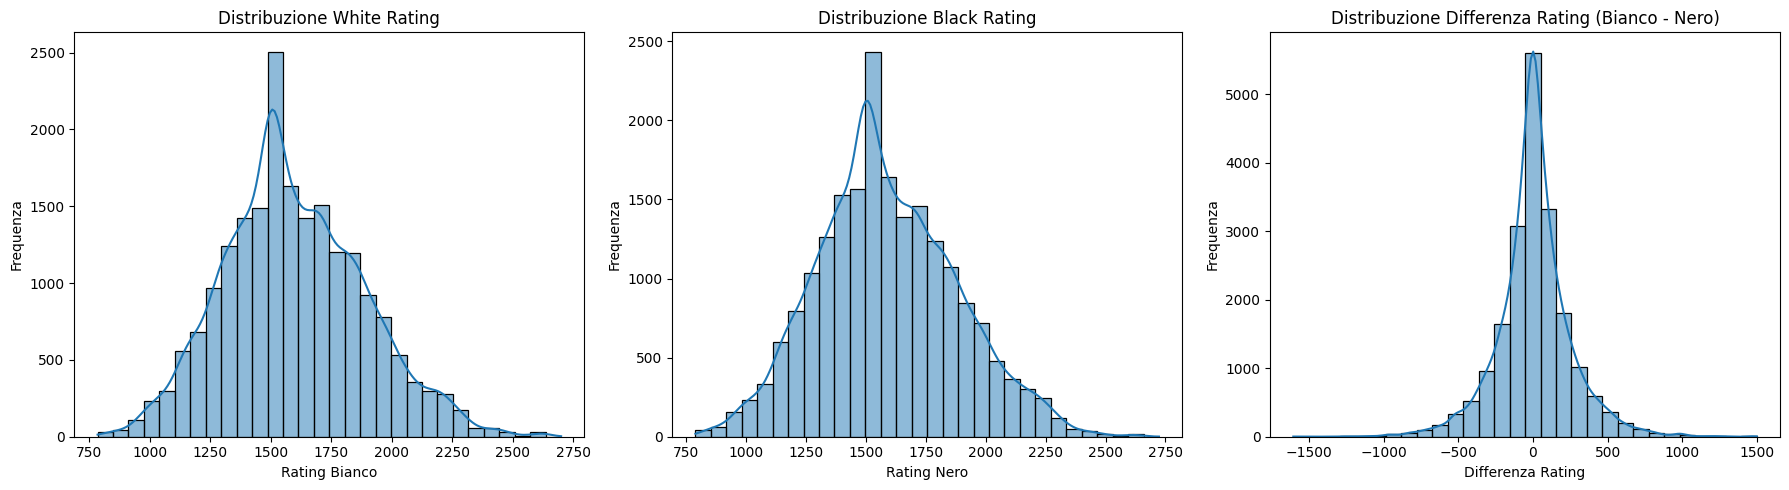

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcola la differenza di rating
df['rating_difference'] = df['white_rating'] - df['black_rating']

print("Distribuzione dei rating e della differenza di rating:")

plt.figure(figsize=(18, 5))

# Distribuzione white_rating
plt.subplot(1, 3, 1)
sns.histplot(df['white_rating'], kde=True, bins=30)
plt.title('Distribuzione White Rating')
plt.xlabel('Rating Bianco')
plt.ylabel('Frequenza')

# Distribuzione black_rating
plt.subplot(1, 3, 2)
sns.histplot(df['black_rating'], kde=True, bins=30)
plt.title('Distribuzione Black Rating')
plt.xlabel('Rating Nero')
plt.ylabel('Frequenza')

# Distribuzione rating_difference
plt.subplot(1, 3, 3)
sns.histplot(df['rating_difference'], kde=True, bins=30)
plt.title('Distribuzione Differenza Rating (Bianco - Nero)')
plt.xlabel('Differenza Rating')
plt.ylabel('Frequenza')

plt.tight_layout()
plt.show()


Probabilità di vittoria/patta per bin di differenza rating:


C:\Users\enzol\AppData\Local\Temp\ipykernel_14340\44570608.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  prob_by_diff = df_binned.groupby('rating_diff_bin')['winner'].value_counts(normalize=True).unstack(fill_value=0)


winner,black,draw,white
"(-3000, -400]",0.821212,0.023232,0.155556
"(-400, -200]",0.724054,0.040737,0.235209
"(-200, -100]",0.604082,0.052608,0.343311
"(-100, -50]",0.526403,0.058856,0.414741
"(-50, 0]",0.472669,0.055020,0.472312
"(0, 50]",0.443980,0.052032,0.503988
"(50, 100]",0.373475,0.047215,0.579310
"(100, 200]",0.314838,0.044136,0.641026
"(200, 400]",0.204853,0.038264,0.756883
"(400, 3000]",0.111888,0.046329,0.841783


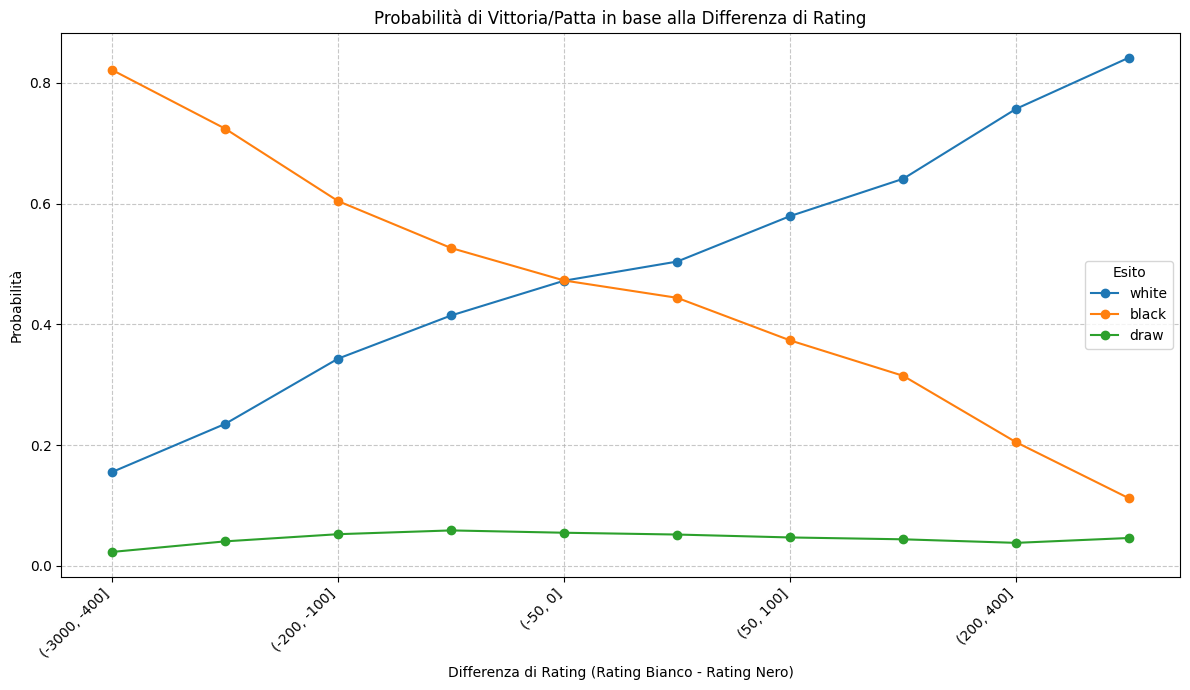


Partite rilevanti per gli upset (escluse patte e rating uguali): 18918 su 20058 partite totali
Numero totale di upset: 6566
Percentuale di upset sulle partite rilevanti: 34.71%
Percentuale di upset sul totale delle partite: 32.74%


In [37]:
# Calcola le probabilità di vittoria/patta per bin di rating_difference

# Definisci i bin per la differenza di rating
bins = pd.IntervalIndex.from_tuples([(-3000, -400), (-400, -200), (-200, -100), (-100, -50), (-50, 0),
                                      (0, 50), (50, 100), (100, 200), (200, 400), (400, 3000)])

df['rating_diff_bin'] = pd.cut(df['rating_difference'], bins=bins, include_lowest=True)

# Rimuovi i NaN se ci sono (partite con rating fuori dai bin definiti, seppur improbabile)
df_binned = df.dropna(subset=['rating_diff_bin']).copy()

# Calcola le probabilità condizionate
prob_by_diff = df_binned.groupby('rating_diff_bin')['winner'].value_counts(normalize=True).unstack(fill_value=0)

# Ordina i bin per una visualizzazione corretta
prob_by_diff = prob_by_diff.reindex(bins)

print("Probabilità di vittoria/patta per bin di differenza rating:")
display(prob_by_diff)

# Plot delle curve di probabilità
plt.figure(figsize=(12, 7))
prob_by_diff[['white', 'black', 'draw']].plot(kind='line', marker='o', ax=plt.gca())
plt.title('Probabilità di Vittoria/Patta in base alla Differenza di Rating')
plt.xlabel('Differenza di Rating (Rating Bianco - Rating Nero)')
plt.ylabel('Probabilità')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Esito')
plt.tight_layout()
plt.show()

# Calcolo degli upset
# Un upset si verifica quando il giocatore con rating inferiore vince, escludendo le patte.

# Condizioni per upset
upset_white_wins = (df['white_rating'] < df['black_rating']) & (df['winner'] == 'white')
upset_black_wins = (df['black_rating'] < df['white_rating']) & (df['winner'] == 'black')

total_games = len(df)
total_games_without_draws_or_equal_rating = df[(df['winner'] != 'draw') & (df['white_rating'] != df['black_rating'])].shape[0]
total_upsets = df[upset_white_wins | upset_black_wins].shape[0]

# Calcola le quote di upset sulle partite rilevanti e sull'intero dataset.
percentage_upset_relevant = (total_upsets / total_games_without_draws_or_equal_rating) * 100 if total_games_without_draws_or_equal_rating > 0 else 0
percentage_upset_total = (total_upsets / total_games) * 100 if total_games > 0 else 0

print(f"\nPartite rilevanti per gli upset (escluse patte e rating uguali): {total_games_without_draws_or_equal_rating} su {total_games} partite totali")
print(f"Numero totale di upset: {total_upsets}")
print(f"Percentuale di upset sulle partite rilevanti: {percentage_upset_relevant:.2f}%")
print(f"Percentuale di upset sul totale delle partite: {percentage_upset_total:.2f}%")

### Interpretazione: Rating e Upset

Le distribuzioni dei rating mostrano che la maggior parte dei giocatori si concentra in un intervallo centrale, indicando una base di utenti amatoriale-intermedia, con code a sinistra e a destra per giocatori di rating più basso e più alto. La distribuzione della differenza di rating è centrata intorno allo zero, suggerendo che le partite sono spesso tra giocatori con rating simili, sebbene esistano sfide con disparità significative.

Le curve di probabilità per bin di differenza di rating illustrano chiaramente come all'aumentare della differenza di rating a favore di un giocatore, aumenti drasticamente la sua probabilità di vittoria e diminuisca quella dell'avversario. Questo conferma che il rating è un predittore forte dell'esito della partita. Per le patte, le probabilità variano tra i bin ma non mostrano un andamento monotono o abbastanza netto da concludere che siano sistematicamente più frequenti quando i rating sono simili.

La percentuale di "upset" indica che, anche quando c'è una differenza di rating, il giocatore con rating inferiore vince una percentuale non trascurabile di partite. Questa informazione è cruciale:

*   **Per il prodotto (calibrazione aspettative e scommesse):** I dati di upset dimostrano che, sebbene il rating sia predittivo, le sorprese accadono. Questo deve essere riflesso nelle probabilità offerte agli spettatori, garantendo quote credibili che non sottostimino eccessivamente la possibilità di vittoria del giocatore sfavorito. Un sistema che dia probabilità troppo sbilanciate potrebbe risultare poco ingaggiante o percepito come impreciso in caso di upset.
*   **Per il matchmaking:** La frequenza degli upset suggerisce che anche partite con una certa disparità di rating possono essere competitive e interessanti. Il team di matchmaking può usare queste informazioni per calibrare gli abbinamenti, non solo cercando la parità assoluta, ma anche consentendo differenze di rating che mantengano un tasso di upset accettabile, rendendo il gioco più dinamico. Potrebbe essere interessante analizzare i fattori che contribuiscono a questi upset per migliorarne la comprensione.

**Rischi/limiti:** Il calcolo degli upset si basa sulla definizione di 'rating inferiore vince', escludendo le patte e i casi di rating uguali. Se le patte o le partite con rating uguali nascondono dinamiche particolari di 'sorpresa', l'attuale definizione potrebbe non catturarle. Inoltre, la grandezza dei bin di rating può influenzare la fluidità delle curve e la percezione delle probabilità. Le fasce estreme dei bin possono avere una numerosità più bassa, quindi le probabilità osservate in quei bin possono essere più incerte; questa incertezza dovrà essere valutata nello step di modellazione prima di usarle per decisioni di prodotto.

### 3. Aperture

Cardinalità di 'opening_eco': 365
Cardinalità di 'opening_name': 1477

Numero di 'opening_eco' con 1-2 occorrenze:
75
Numero di 'opening_name' con 1-2 occorrenze:
579

Distribuzione degli esiti per le prime 10 aperture più frequenti ('opening_name'):


winner,black,draw,white
opening_name,,,
Van't Kruijs Opening,0.614130,0.043478,0.342391
Sicilian Defense,0.541899,0.041899,0.416201
Sicilian Defense: Bowdler Attack,0.554054,0.043919,0.402027
French Defense: Knight Variation,0.446494,0.055351,0.498155
Scotch Game,0.424354,0.040590,0.535055
Scandinavian Defense: Mieses-Kotroc Variation,0.343629,0.023166,0.633205
Queen's Pawn Game: Mason Attack,0.443966,0.056034,0.500000
Queen's Pawn Game: Chigorin Variation,0.475983,0.034934,0.489083
Scandinavian Defense,0.551570,0.044843,0.403587


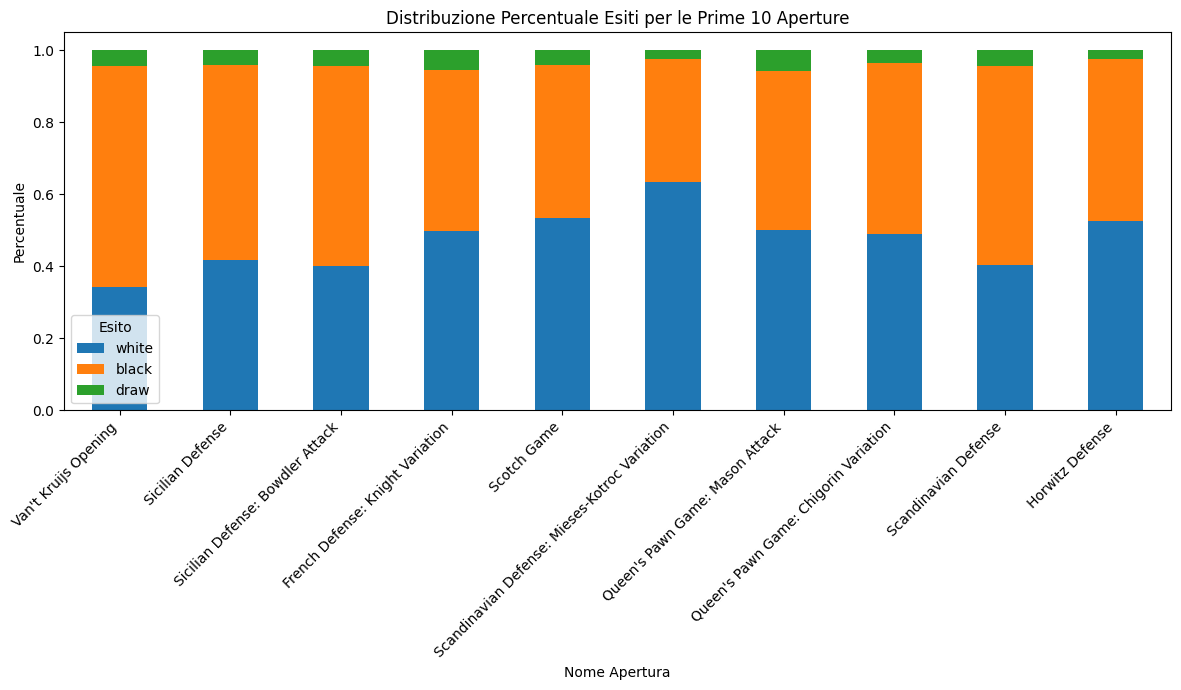


Risultati del test Chi-quadro per Apertura vs. Esito:
Statistica Chi-quadro: 80.37
P-value: 7.373e-10
V di Cramér: 0.122
L'associazione tra 'opening_name' e 'winner' è statisticamente significativa (p < 0.05).


In [38]:
# Cardinalità di opening_eco e opening_name
print("Cardinalità di 'opening_eco':", df['opening_eco'].nunique())
print("Cardinalità di 'opening_name':", df['opening_name'].nunique())

# Conteggio delle occorrenze per opening_eco e opening_name
opening_eco_counts = df['opening_eco'].value_counts()
opening_name_counts = df['opening_name'].value_counts()

print("\nNumero di 'opening_eco' con 1-2 occorrenze:")
print((opening_eco_counts <= 2).sum())

print("Numero di 'opening_name' con 1-2 occorrenze:")
print((opening_name_counts <= 2).sum())

# Per le aperture più frequenti: distribuzione degli esiti in percentuali condizionate
num_top_openings = 10 # Seleziona le prime N aperture più frequenti
top_openings = opening_name_counts.head(num_top_openings).index

print(f"\nDistribuzione degli esiti per le prime {num_top_openings} aperture più frequenti ('opening_name'):")

# Filtra il DataFrame per includere solo le aperture più frequenti
df_top_openings = df[df['opening_name'].isin(top_openings)].copy()

# Calcola le percentuali condizionate
outcome_by_opening = df_top_openings.groupby('opening_name')['winner'].value_counts(normalize=True).unstack(fill_value=0)

# Ordina per la frequenza dell'apertura originale per una migliore leggibilità
outcome_by_opening = outcome_by_opening.loc[top_openings]
display(outcome_by_opening)

# Visualizzazione
outcome_by_opening[['white', 'black', 'draw']].plot(kind='bar', stacked=True, figsize=(12, 7))
plt.title(f'Distribuzione Percentuale Esiti per le Prime {num_top_openings} Aperture')
plt.xlabel('Nome Apertura')
plt.ylabel('Percentuale')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Esito')
plt.tight_layout()
plt.show()

# Verifica se l'associazione apertura-esito è statisticamente rilevante (test chi-quadro)
from scipy.stats import chi2_contingency

# Creazione della tabella di contingenza per le aperture più frequenti e gli esiti
contingency_table = pd.crosstab(df_top_openings['opening_name'], df_top_openings['winner'])

# Esegui il test chi-quadro solo se la tabella non è vuota e ha dimensioni sufficienti
if not contingency_table.empty and min(contingency_table.shape) > 1:
    chi2, p_value, _, _ = chi2_contingency(contingency_table)
    print(f"\nRisultati del test Chi-quadro per Apertura vs. Esito:")
    print(f"Statistica Chi-quadro: {chi2:.2f}")
    print(f"P-value: {p_value:.3e}")

    # Calcola la V di Cramér come misura dell'ampiezza dell'associazione.
    n_osservazioni = contingency_table.to_numpy().sum()
    dimensione_minima = min(contingency_table.shape) - 1
    cramers_v = (chi2 / (n_osservazioni * dimensione_minima)) ** 0.5
    print(f"V di Cramér: {cramers_v:.3f}")

    alpha = 0.05
    if p_value < alpha:
        print(f"L'associazione tra 'opening_name' e 'winner' è statisticamente significativa (p < {alpha}).")
    else:
        print(f"L'associazione tra 'opening_name' e 'winner' NON è statisticamente significativa (p >= {alpha}).")
else:
    print("\nTabella di contingenza vuota o insufficiente per il test Chi-quadro e la V di Cramér.")

### Interpretazione: Aperture

**Nota metodologica sul momento della previsione:** in un modello di probabilità pre-partita, l'apertura non è ancora stata scelta o giocata e `opening_name`, `opening_eco` e `opening_ply` non sono quindi disponibili come feature. In un modello post-prime-mosse, invece, queste informazioni possono essere usate per aggiornare la probabilità durante la partita. I risultati di questa sezione sono pertanto applicabili al secondo scenario e non dimostrano, da soli, utilità per una previsione pre-partita.

L'elevata cardinalità di `opening_eco` e `opening_name`, con un numero significativo di aperture che si verificano solo 1 o 2 volte, suggerisce una grande varietà di strategie di apertura. Questa 'coda lunga' di aperture rare è un dato importante per il modeling, poiché un'eccessiva categorizzazione potrebbe portare a un overfit o a problemi di rappresentatività per le classi meno frequenti. Per le aperture più comuni, osserviamo variazioni nelle percentuali di vittoria e patta, ma queste differenze descrittive non dimostrano da sole un effetto causale o una migliore previsione calibrata.

Il test Chi-quadro è stato applicato esclusivamente al sottoinsieme delle 10 aperture più frequenti e, per questo sottoinsieme, mostra un p-value molto basso: l'associazione osservata tra queste aperture ed esito è difficilmente compatibile con il caso. Questo risultato non può essere esteso automaticamente a tutte le aperture del dataset. Inoltre, la V di Cramér è pari a `0,122` e indica che l'effetto nel sottoinsieme analizzato è debole in termini pratici. Con circa 20.000 partite, anche associazioni di ampiezza molto piccola possono risultare statisticamente significative. Le 10 aperture più frequenti non sono quindi, da sole, predittori forti dell'esito: il loro contributo dovrà essere valutato in un modello multivariato, controllando almeno rating, colore, tipo di partita e tempo di gioco, oltre alla calibrazione delle probabilità.

**Rischi/limiti:** Data l'elevata cardinalità, l'encoding delle aperture per il modeling richiederà attenzione. Tecniche come il target encoding o il raggruppamento delle aperture meno frequenti potrebbero essere necessarie per evitare problemi di dimensionalità o data sparsity. L'associazione osservata nel sottoinsieme delle 10 aperture più frequenti potrebbe inoltre dipendere dal livello dei giocatori che tendono a usare determinate aperture, anziché dall'apertura in sé. Questa analisi non consente quindi di formulare raccomandazioni operative per spettatori o matchmaking.

**Nota temporale:** il dataset contiene `created_at` e `last_move_at` come timestamp, convertibili in date. Sono quindi possibili uno split temporale e un'analisi della stabilità nel tempo delle curve rating-esito, del tasso di upset e dell'associazione apertura-esito; queste verifiche saranno affrontate nello step di modellazione. L'analisi temporale non è ancora stata eseguita, ma non è un limite strutturale del dataset.

### 4. Rated vs non rated

Distribuzione degli esiti separata per 'rated' True/False:

Numerosità dei gruppi:
Partite rated: 16155
Partite non rated: 3903


winner,black,draw,white
rated,,,
False,44.145529,5.918524,49.935947
True,45.707211,4.450634,49.842154


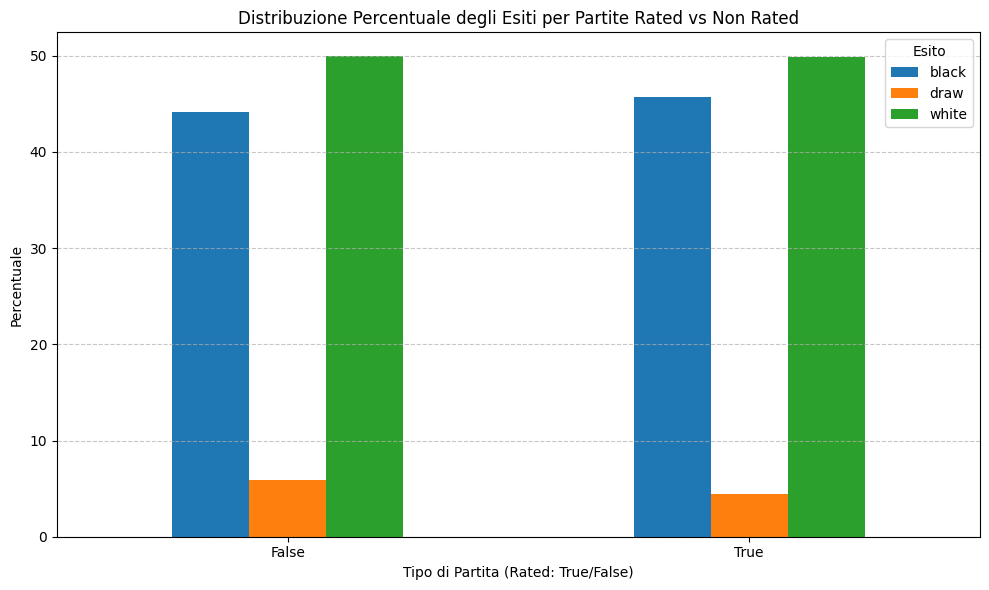


Partite rilevanti per upset rated: 15351
Partite rilevanti per upset non rated: 3567
Tasso di upset per partite 'rated': 35.07%
Tasso di upset per partite 'non rated': 33.14%
Tasso di patte per partite 'rated': 4.45%
Tasso di patte per partite 'non rated': 5.92%

IC 95% tasso di patte rated: [4.14%, 4.78%]
IC 95% tasso di patte non rated: [5.22%, 6.70%]
Test z differenza tasso di patte: z = -3.87, p-value = 0.0001
IC 95% tasso di upset rated: [34.32%, 35.83%]
IC 95% tasso di upset non rated: [31.61%, 34.70%]
Test z differenza tasso di upset: z = 2.19, p-value = 0.0287

Interpretazione: i gruppi comprendono 16155 partite rated e 3903 non rated. Il tasso di patte è 4.45% contro 5.92% (p-value = 0.0001); il tasso di upset è 35.07% contro 33.14% (p-value = 0.0287).


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

print("Distribuzione degli esiti separata per 'rated' True/False:")

# Calcola il numero di partite per ciascun gruppo.
group_counts = df['rated'].value_counts().reindex([True, False], fill_value=0)
print("\nNumerosità dei gruppi:")
print(f"Partite rated: {group_counts[True]}")
print(f"Partite non rated: {group_counts[False]}")

# Calcola i conteggi e le percentuali per rated vs non rated.
rated_outcomes = df.groupby('rated')['winner'].value_counts(normalize=True).unstack(fill_value=0) * 100

display(rated_outcomes)

# Plot della distribuzione degli esiti.
rated_outcomes.plot(kind='bar', figsize=(10, 6), stacked=False)
plt.title('Distribuzione Percentuale degli Esiti per Partite Rated vs Non Rated')
plt.xlabel('Tipo di Partita (Rated: True/False)')
plt.ylabel('Percentuale')
plt.xticks(rotation=0)
plt.legend(title='Esito')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Calcolo del tasso di upset per rated vs non rated.
def get_upset_counts(data_frame):
    # Definisce le condizioni per un upset.
    upset_white_wins = (data_frame['white_rating'] < data_frame['black_rating']) & (data_frame['winner'] == 'white')
    upset_black_wins = (data_frame['black_rating'] < data_frame['white_rating']) & (data_frame['winner'] == 'black')

    relevant_games = data_frame[(data_frame['winner'] != 'draw') & (data_frame['white_rating'] != data_frame['black_rating'])]
    total_upsets = (upset_white_wins | upset_black_wins).sum()

    return total_upsets, len(relevant_games)


def proportion_confidence_interval(successes, total, confidence=0.95):
    # Calcola un intervallo di Wilson per una proporzione.
    if total == 0:
        return 0.0, 0.0

    z_score = norm.ppf(1 - (1 - confidence) / 2)
    proportion = successes / total
    denominator = 1 + z_score**2 / total
    center = (proportion + z_score**2 / (2 * total)) / denominator
    margin = z_score * (
        (proportion * (1 - proportion) / total + z_score**2 / (4 * total**2)) ** 0.5
    ) / denominator
    return center - margin, center + margin


def two_proportion_z_test(successes_first, total_first, successes_second, total_second):
    # Confronta due proporzioni con un test z bilaterale.
    pooled_proportion = (successes_first + successes_second) / (total_first + total_second)
    standard_error = (
        pooled_proportion * (1 - pooled_proportion) * (1 / total_first + 1 / total_second)
    ) ** 0.5
    if standard_error == 0:
        return 0.0, 1.0

    z_score = (successes_first / total_first - successes_second / total_second) / standard_error
    p_value = 2 * norm.sf(abs(z_score))
    return z_score, p_value


rated_upsets, rated_relevant_games = get_upset_counts(df[df['rated'] == True])
non_rated_upsets, non_rated_relevant_games = get_upset_counts(df[df['rated'] == False])

upset_rate_rated = rated_upsets / rated_relevant_games * 100 if rated_relevant_games > 0 else 0
upset_rate_non_rated = non_rated_upsets / non_rated_relevant_games * 100 if non_rated_relevant_games > 0 else 0

print(f"\nPartite rilevanti per upset rated: {rated_relevant_games}")
print(f"Partite rilevanti per upset non rated: {non_rated_relevant_games}")
print(f"Tasso di upset per partite 'rated': {upset_rate_rated:.2f}%")
print(f"Tasso di upset per partite 'non rated': {upset_rate_non_rated:.2f}%")

# Calcolo del tasso di patte per rated vs non rated.
rated_draws = (df[df['rated'] == True]['winner'] == 'draw').sum()
non_rated_draws = (df[df['rated'] == False]['winner'] == 'draw').sum()
draw_rate_rated = rated_draws / group_counts[True] * 100 if group_counts[True] > 0 else 0
draw_rate_non_rated = non_rated_draws / group_counts[False] * 100 if group_counts[False] > 0 else 0

print(f"Tasso di patte per partite 'rated': {draw_rate_rated:.2f}%")
print(f"Tasso di patte per partite 'non rated': {draw_rate_non_rated:.2f}%")

# Calcola gli intervalli di confidenza al 95% e i test per le differenze osservate.
rated_draw_ci = proportion_confidence_interval(rated_draws, group_counts[True])
non_rated_draw_ci = proportion_confidence_interval(non_rated_draws, group_counts[False])
rated_upset_ci = proportion_confidence_interval(rated_upsets, rated_relevant_games)
non_rated_upset_ci = proportion_confidence_interval(non_rated_upsets, non_rated_relevant_games)

draw_z_score, draw_p_value = two_proportion_z_test(
    rated_draws, group_counts[True], non_rated_draws, group_counts[False]
)
upset_z_score, upset_p_value = two_proportion_z_test(
    rated_upsets, rated_relevant_games, non_rated_upsets, non_rated_relevant_games
)

print(f"\nIC 95% tasso di patte rated: [{rated_draw_ci[0] * 100:.2f}%, {rated_draw_ci[1] * 100:.2f}%]")
print(f"IC 95% tasso di patte non rated: [{non_rated_draw_ci[0] * 100:.2f}%, {non_rated_draw_ci[1] * 100:.2f}%]")
print(f"Test z differenza tasso di patte: z = {draw_z_score:.2f}, p-value = {draw_p_value:.4f}")
print(f"IC 95% tasso di upset rated: [{rated_upset_ci[0] * 100:.2f}%, {rated_upset_ci[1] * 100:.2f}%]")
print(f"IC 95% tasso di upset non rated: [{non_rated_upset_ci[0] * 100:.2f}%, {non_rated_upset_ci[1] * 100:.2f}%]")
print(f"Test z differenza tasso di upset: z = {upset_z_score:.2f}, p-value = {upset_p_value:.4f}")

# Genera un'interpretazione con i risultati aggiornati, senza duplicare valori hardcoded nella Markdown.
print(
    f"\nInterpretazione: i gruppi comprendono {group_counts[True]} partite rated e "
    f"{group_counts[False]} non rated. Il tasso di patte è {draw_rate_rated:.2f}% "
    f"contro {draw_rate_non_rated:.2f}% (p-value = {draw_p_value:.4f}); il tasso di "
    f"upset è {upset_rate_rated:.2f}% contro {upset_rate_non_rated:.2f}% "
    f"(p-value = {upset_p_value:.4f})."
)

### Interpretazione: Rated vs non rated

La cella precedente riporta dinamicamente la numerosità dei due gruppi, i tassi osservati, gli intervalli di confidenza al 95% e i p-value dei test sulle differenze. I denominatori sono distinti: il tasso di patte usa tutte le partite del gruppo, mentre il tasso di upset usa solo le partite senza patta e con rating diversi.

*   **Tasso di upset:** Il tasso osservato è più alto nelle partite rated rispetto alle non rated e il test z valuta questa differenza. Gli intervalli di confidenza mostrano l'incertezza delle stime. Il risultato descrive un'associazione tra tipo di partita e upset, ma non dimostra che rating in palio, pressione competitiva o aggressività siano la causa della differenza.

*   **Tasso di patte:** Il tasso osservato è più alto nelle partite non rated e il test z valuta la differenza tra i gruppi. Anche in questo caso il risultato è associativo: il dataset non identifica se la differenza dipenda da stile di gioco, composizione dei gruppi o altri fattori non osservati.

**Implicazioni per il prodotto:**

*   **Differenziazione delle probabilità:** Separare rated e non rated nel modello è un'ipotesi plausibile da validare nello step di modellazione, confrontando prestazioni e calibrazione per sottogruppo. Non è ancora un risultato che dimostri la necessità di due probabilità operative distinte.
*   **Matchmaking e calibrazione:** Le differenze osservate possono orientare le analisi successive, ma non giustificano ancora regole di matchmaking o conclusioni causali. Prima dell'uso prodotto servono controllo dei confondenti, validazione temporale e verifica della calibrazione in ciascun gruppo.

### 5. Tempo di gioco (`increment_code`)

Parsing di 'increment_code' in 'time_base' e 'increment':
Distribuzione di 'time_base' e 'increment':


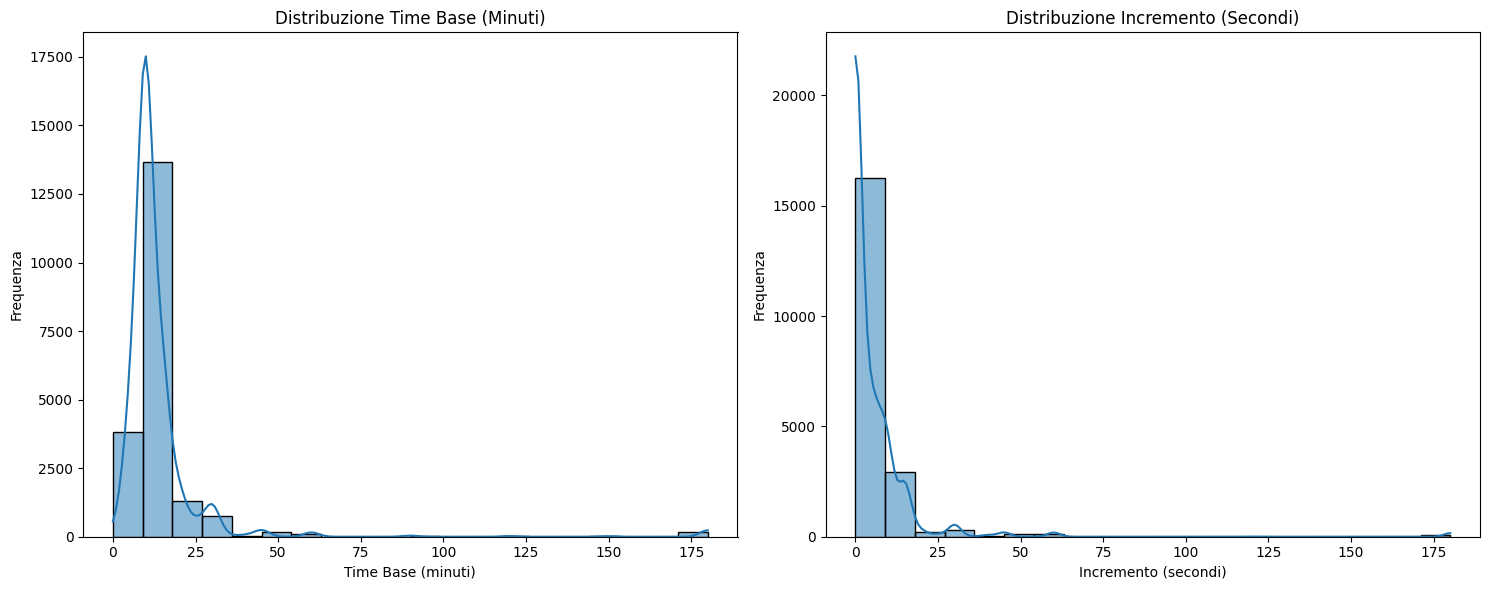


Percentuale di patte in funzione di 'time_base', ordinata per tempo:


,time_base,game_count,draw_count,draw_percentage
0,0,45,2,4.444444
1,1,31,1,3.225806
2,2,55,1,1.818182
3,3,57,0,0.000000
4,4,65,0,0.000000
5,5,1795,77,4.289694
6,6,176,5,2.840909
7,7,661,30,4.538578
8,8,924,51,5.519481
9,9,261,8,3.065134


Test di Spearman tra time_base e patta: rho = 0.030, p-value = 0.0000


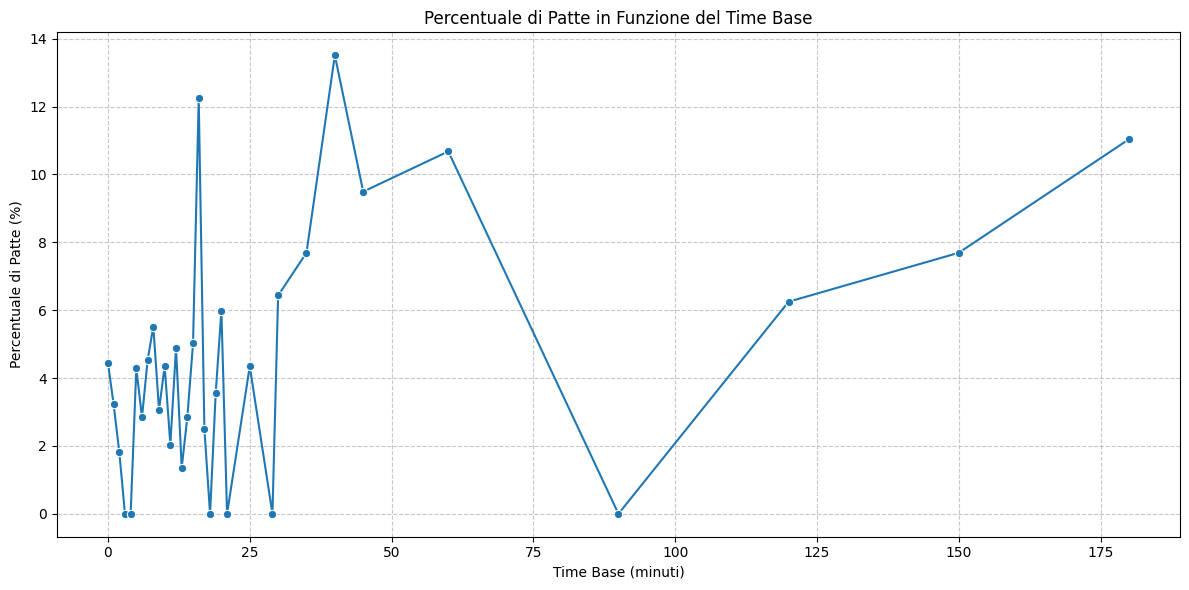

In [40]:
import re
from scipy.stats import spearmanr

print("Parsing di 'increment_code' in 'time_base' e 'increment':")

# La colonna increment_code è nel formato 'time_base+increment'.
# Estrai time_base (minuti) e increment (secondi)
def parse_increment_code(code):
    if isinstance(code, str) and '+' in code:
        parts = code.split('+')
        try:
            time_base = int(parts[0]) # minuti
            increment = int(parts[1]) # secondi
            return pd.Series([time_base, increment])
        except ValueError:
            return pd.Series([None, None]) # Gestisce casi non numerici dopo lo split
    return pd.Series([None, None]) # Gestisce formati non previsti o NaN

df[['time_base', 'increment']] = df['increment_code'].apply(parse_increment_code)

print("Distribuzione di 'time_base' e 'increment':")
plt.figure(figsize=(15, 6))

# Distribuzione di time_base
plt.subplot(1, 2, 1)
sns.histplot(df['time_base'].dropna(), kde=True, bins=20)
plt.title('Distribuzione Time Base (Minuti)')
plt.xlabel('Time Base (minuti)')
plt.ylabel('Frequenza')

# Distribuzione di increment
plt.subplot(1, 2, 2)
sns.histplot(df['increment'].dropna(), kde=True, bins=20)
plt.title('Distribuzione Incremento (Secondi)')
plt.xlabel('Incremento (secondi)')
plt.ylabel('Frequenza')

plt.tight_layout()
plt.show()

print("\nPercentuale di patte in funzione di 'time_base', ordinata per tempo:")

# Calcola conteggio e percentuale di patte per ogni time_base.
draw_percentage_by_time = df.dropna(subset=['time_base']).groupby('time_base')['winner'].agg(
    game_count='size',
    draw_count=lambda outcomes: (outcomes == 'draw').sum(),
    draw_percentage=lambda outcomes: (outcomes == 'draw').mean() * 100
).reset_index()

# Ordina per time_base per una visualizzazione corretta.
draw_percentage_by_time = draw_percentage_by_time.sort_values(by='time_base')

display(draw_percentage_by_time)

# Verifica l'ipotesi di una relazione monotona tra time_base e patta.
time_draw_data = df.dropna(subset=['time_base']).copy()
time_draw_data['is_draw'] = (time_draw_data['winner'] == 'draw').astype(int)
spearman_rho, spearman_p_value = spearmanr(time_draw_data['time_base'], time_draw_data['is_draw'])
print(f"Test di Spearman tra time_base e patta: rho = {spearman_rho:.3f}, p-value = {spearman_p_value:.4f}")

# Plot della percentuale di patte per time_base.
plt.figure(figsize=(12, 6))
sns.lineplot(x='time_base', y='draw_percentage', data=draw_percentage_by_time, marker='o')
plt.title('Percentuale di Patte in Funzione del Time Base')
plt.xlabel('Time Base (minuti)')
plt.ylabel('Percentuale di Patte (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Interpretazione: Tempo di gioco

Il parsing del codice `increment_code` ha permesso di estrarre `time_base` (minuti) e `increment` (secondi), trasformando una variabile categorica complessa in due variabili numeriche più interpretabili. Le distribuzioni mostrano che la maggior parte delle partite ha una `time_base` breve (spesso 10 minuti o meno) e un incremento relativamente piccolo, indicando una prevalenza di partite veloci (blitz o rapid).

La percentuale di patte in funzione di `time_base` mostra un andamento irregolare, con oscillazioni, picchi isolati e valori pari a zero per alcuni tempi. La tabella riporta anche la numerosità di ogni `time_base`, necessaria per interpretare l'incertezza dei valori osservati. Il test di Spearman rileva un'associazione monotona statisticamente significativa ma quasi nulla in ampiezza (`rho = 0,030`): con un dataset grande, il p-value può rilevare anche effetti trascurabili. Non si può quindi concludere che l'ipotesi "tempi più lunghi → più patte" abbia rilevanza pratica.

**Implicazioni per il prodotto:**

*   **Matchmaking e probabilità:** Il formato di gioco (`time_base` e `increment`) è un candidato da valutare nel modello di probabilità pre-partita, ma il suo contributo alla probabilità di patta dovrà essere verificato con analisi statistiche e validazione del modello.
*   **Interazione con il rating:** Potrebbe esserci un'interazione tra `time_base`, `increment` e il rating dei giocatori. Ad esempio, i giocatori con rating più alti potrebbero essere più abili a sfruttare il tempo extra per evitare errori e cercare la patta in posizioni pari. Questa interazione dovrà essere esplorata nel modeling.
*   **Rischio/limiti:** Il test di Spearman valuta solo un'associazione monotona a livello aggregato/individuale e non controlla rating, tipo di partita, incremento o composizione dei giocatori. I risultati non consentono quindi di stabilire un effetto causale; serviranno un modello multivariato, verifica della calibrazione e validazione temporale.

### 6. Qualità e rappresentatività del dataset

Analisi della qualità e rappresentatività del dataset:

Distribuzione delle partite per giocatore:


count    15635.000000
mean         2.565782
std          6.024316
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        154.000000
Name: count, dtype: float64

Percentuale di giocatori con 1 sola partita: 71.44%
Percentuale di giocatori con >50 partite: 0.08%


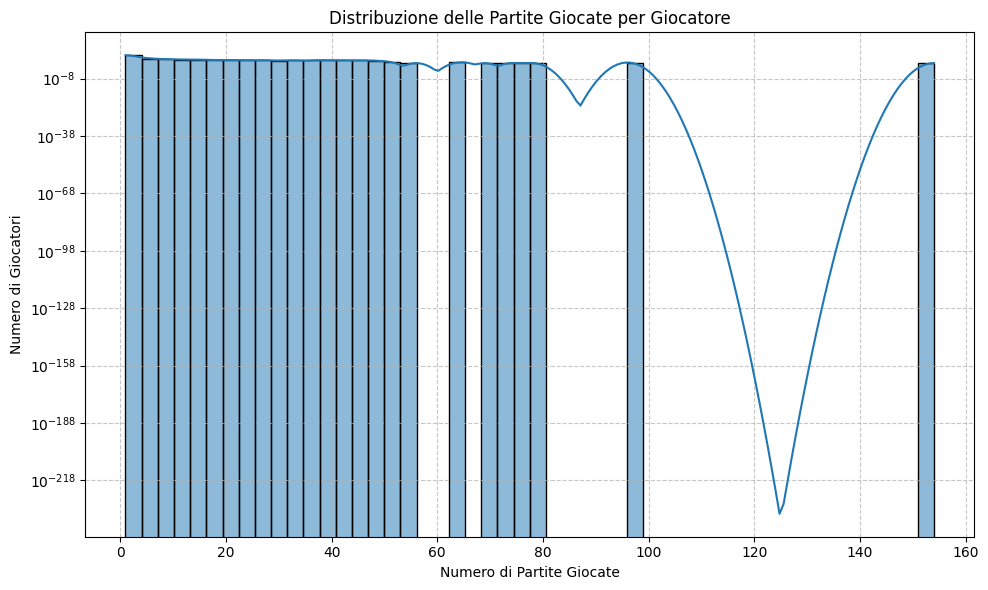


Numero totale di giocatori unici: 15635
Numero di giocatori che hanno giocato più di una partita: 4466
Partite con almeno un giocatore già osservato: 18939 su 20058 (94.42%).

Statistiche descrittive per 'turns':


count    20058.000000
mean        60.465999
std         33.570585
min          1.000000
25%         37.000000
50%         55.000000
75%         79.000000
max        349.000000
Name: turns, dtype: float64

Numero di partite con meno di 5 mosse: 342 (1.71%) del totale.


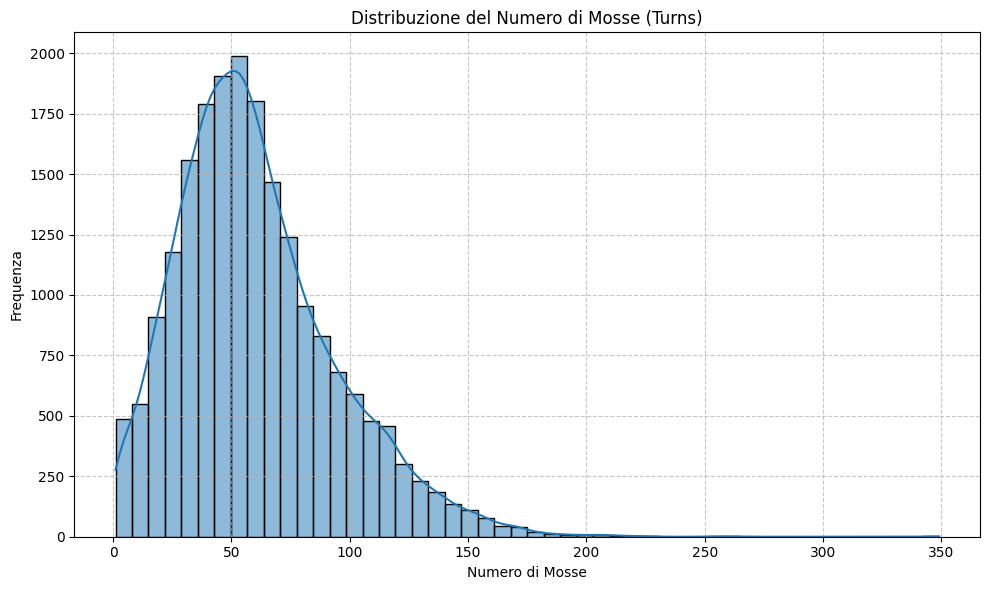


Valori mancanti per colonna:


,Missing Count,Missing Percentage



Verifica delle colonne con informazioni temporali ('created_at', 'last_move_at'):
'created_at' min: 2013-08-17 20:33:53.173000, max: 2017-09-04 02:45:43.790000
'last_move_at' min: 2013-08-17 20:37:43.841000, max: 2017-09-04 02:57:07.262000

Il dataset contiene timestamp utilizzabili per uno split temporale e per analisi della stabilità e del drift. Queste verifiche saranno affrontate nello step di modellazione; non rappresentano un limite strutturale del dataset.

Interpretazione: 18939 partite su 20058 (94.42%) includono almeno un giocatore già osservato; 4466 giocatori hanno giocato più di una partita. Uno split random train/test è quindi rischioso perché quasi tutte le partite di test possono condividere giocatori con il train. Le percentuali di giocatori con una sola partita (71.44%), di giocatori con più di 50 partite (0.08%) e di partite con meno di 5 mosse (1.71%) sono derivate dai calcoli correnti. Lo split temporale è possibile grazie ai timestamp disponibili e sarà valutato 

In [41]:
print("Analisi della qualità e rappresentatività del dataset:")

# 1. Partite per giocatore (su white_id e black_id combinate)
# Crea una serie combinata di tutti gli ID dei giocatori
all_player_ids = pd.concat([df['white_id'], df['black_id']])

# Conta le partite giocate per ogni giocatore
games_per_player = all_player_ids.value_counts()

print("\nDistribuzione delle partite per giocatore:")
display(games_per_player.describe())

# Percentuale di giocatori con 1 sola partita
players_one_game = (games_per_player == 1).sum()
percentage_one_game = (players_one_game / len(games_per_player)) * 100
print(f"Percentuale di giocatori con 1 sola partita: {percentage_one_game:.2f}%")

# Percentuale di giocatori con >50 partite
players_over_50_games = (games_per_player > 50).sum()
percentage_over_50_games = (players_over_50_games / len(games_per_player)) * 100
print(f"Percentuale di giocatori con >50 partite: {percentage_over_50_games:.2f}%")

# Visualizzazione della distribuzione delle partite per giocatore
plt.figure(figsize=(10, 6))
sns.histplot(games_per_player, bins=50, kde=True)
plt.title('Distribuzione delle Partite Giocate per Giocatore')
plt.xlabel('Numero di Partite Giocate')
plt.ylabel('Numero di Giocatori')
plt.yscale('log') # Usa scala logaritmica per vedere meglio la coda lunga
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Giocatori unici, partite con giocatori ripetuti
unique_players = len(games_per_player)
print(f"\nNumero totale di giocatori unici: {unique_players}")

# Conta i giocatori che compaiono in più di una partita.
players_with_multiple_games = (games_per_player > 1).sum()
print(f"Numero di giocatori che hanno giocato più di una partita: {players_with_multiple_games}")

# Conta le partite in cui almeno uno dei due giocatori era già stato osservato.
observed_players = set()
games_with_previously_observed_player = 0
for white_id, black_id in zip(df['white_id'], df['black_id']):
    if white_id in observed_players or black_id in observed_players:
        games_with_previously_observed_player += 1
    observed_players.update([white_id, black_id])

percentage_games_with_previously_observed_player = (
    games_with_previously_observed_player / len(df) * 100 if len(df) > 0 else 0
)
print(
    f"Partite con almeno un giocatore già osservato: "
    f"{games_with_previously_observed_player} su {len(df)} "
    f"({percentage_games_with_previously_observed_player:.2f}%)."
)

# 3. `turns`: distribuzione e casi anomali (<5 mosse)
print("\nStatistiche descrittive per 'turns':")
display(df['turns'].describe())

short_games = df[df['turns'] < 5].shape[0]
percentage_short_games = (short_games / len(df)) * 100
print(f"Numero di partite con meno di 5 mosse: {short_games} ({percentage_short_games:.2f}%) del totale.")

plt.figure(figsize=(10, 6))
sns.histplot(df['turns'], bins=50, kde=True)
plt.title('Distribuzione del Numero di Mosse (Turns)')
plt.xlabel('Numero di Mosse')
plt.ylabel('Frequenza')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 4. Valori mancanti per colonna
print("\nValori mancanti per colonna:")
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing Percentage': missing_percentage})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))

# 5. Colonne con informazioni temporali
print("\nVerifica delle colonne con informazioni temporali ('created_at', 'last_move_at'):")
# created_at e last_move_at sono timestamp UNIX, convertibili in datetime e utilizzabili per analisi temporali.

df['created_at_dt'] = pd.to_datetime(df['created_at'], unit='ms')
df['last_move_at_dt'] = pd.to_datetime(df['last_move_at'], unit='ms')

print(f"'created_at' min: {df['created_at_dt'].min()}, max: {df['created_at_dt'].max()}")
print(f"'last_move_at' min: {df['last_move_at_dt'].min()}, max: {df['last_move_at_dt'].max()}")
print("\nIl dataset contiene timestamp utilizzabili per uno split temporale e per analisi della stabilità e del drift. Queste verifiche saranno affrontate nello step di modellazione; non rappresentano un limite strutturale del dataset.")

# Riepilogo dinamico per l'interpretazione della sezione.
print(
    f"\nInterpretazione: {games_with_previously_observed_player} partite su {len(df)} "
    f"({percentage_games_with_previously_observed_player:.2f}%) includono almeno un "
    f"giocatore già osservato; {players_with_multiple_games} giocatori hanno giocato "
    f"più di una partita. Uno split random train/test è quindi rischioso perché quasi "
    f"tutte le partite di test possono condividere giocatori con il train. Le percentuali "
    f"di giocatori con una sola partita ({percentage_one_game:.2f}%), di giocatori con "
    f"più di 50 partite ({percentage_over_50_games:.2f}%) e di partite con meno di 5 "
    f"mosse ({percentage_short_games:.2f}%) sono derivate dai calcoli correnti. "
    "Lo split temporale è possibile grazie ai timestamp disponibili e sarà valutato nello "
    "step di modellazione."
)

# Rimuovi le colonne temporanee create per l'analisi
df.drop(columns=['created_at_dt', 'last_move_at_dt'], inplace=True, errors='ignore')

### Interpretazione: Qualità e rappresentatività del dataset

L'analisi della qualità e rappresentatività del dataset rivela diversi aspetti critici per lo sviluppo del prodotto:

*   **Rischio di split random train/test:** La cella precedente riporta due misure distinte: il numero di partite con almeno un giocatore già osservato e il numero di giocatori che hanno giocato più di una partita. Nel dataset corrente, la prima misura è molto alta rispetto al totale delle partite, mentre la seconda conta i giocatori e non le partite. Uno split random train/test è quindi fortemente rischioso, perché quasi ogni partita assegnata al test può condividere almeno un giocatore con il train, causando leakage indiretto e metriche artificialmente gonfiate. Lo split random non è adeguato per stimare la generalizzazione a partite con giocatori non osservati.

*   **Alternativa temporale:** Le colonne `created_at` e `last_move_at` contengono timestamp utilizzabili. È quindi possibile adottare uno split temporale, mantenendo le partite più recenti nel test, e verificare la stabilità delle prestazioni e della calibrazione nel tempo. Questa analisi sarà affrontata nello step di modellazione.

*   **Affidabilità del rating per giocatori con poche partite:** La presenza di molti giocatori con una singola partita solleva dubbi sull'affidabilità del loro rating iniziale. I rating di questi giocatori potrebbero essere meno stabili o rappresentativi del loro vero livello di gioco rispetto a quelli di giocatori con un numero elevato di partite, rendendo le previsioni basate su questi rating potenzialmente meno accurate.

*   **Presenza di partite brevissime (`turns` < 5):** La cella precedente riporta dinamicamente il numero e la percentuale di partite con meno di 5 mosse. Il dataset mostra quindi la presenza di partite brevissime, ma questa analisi non ne identifica la causa: il codice non incrocia `turns` con `victory_status` né con altre variabili utili a distinguere i diversi casi. La loro gestione nel modello dovrà essere definita nello step di modellazione.

*   **Valori mancanti:** L'analisi dei valori mancanti non ha rilevato colonne con valori mancanti nel dataset, il che semplifica il processo di modellazione in questo aspetto.

In sintesi, il dataset richiede un'attenta gestione dei giocatori ripetuti, dell'affidabilità dei rating, della validazione temporale e delle partite brevissime, per garantire che il modello sviluppato sia robusto, affidabile e generalizzabile.

### Sintesi dell'Esplorazione Dati (EDA)

Questa sezione riassume i punti chiave emersi dall'analisi esplorativa del dataset, evidenziando cosa è stato fatto, cosa è stato trovato e le implicazioni per il prodotto e il matchmaking per ciascuna delle sezioni precedenti.

---

#### 0. Setup e mappa delle feature
*   **Cosa fa:** Carica il dataset `games.csv`, visualizza le sue caratteristiche di base (shape, tipi di dato, prime righe) e crea una tabella dettagliata di classificazione delle feature.
*   **Cosa ha trovato:** Il dataset è stato caricato con successo e una mappa delle feature ha categorizzato ogni colonna come pre-partita, leakage, identificatore o target, chiarendo la sua idoneità per la modellazione.
*   **Implicazioni per prodotto e matchmaking:** Fornisce una base solida per lo sviluppo del modello, garantendo che vengano utilizzate solo feature valide e prevenendo il leakage, essenziale per probabilità credibili e accurate.

#### 1. Distribuzione del target
*   **Cosa fa:** Calcola i conteggi e le percentuali degli esiti delle partite (`white`, `black`, `draw`).
*   **Cosa ha trovato:** Il target è sbilanciato, con le patte (`draw`) che rappresentano una classe minoritaria (circa 4.74%) rispetto alle vittorie di Bianco (49.86%) e Nero (45.40%).
*   **Implicazioni per prodotto e matchmaking:** L'accuratezza non è una metrica adeguata. Saranno preferibili metriche come la Log Loss o il Brier Score per valutare la calibrazione delle probabilità, con particolare attenzione alla classe minoritaria delle patte, per garantire la credibilità delle quote per gli spettatori.

#### 2. Rating e upset
*   **Cosa fa:** Analizza le distribuzioni dei rating (`white_rating`, `black_rating`, `rating_difference`), calcola le probabilità di vittoria/patta in base alla differenza di rating e quantifica gli upset.
*   **Cosa ha trovato:** I rating sono buoni predittori dell'esito, ma gli upset (giocatore con rating inferiore vince) si verificano in un significativo 34.71% delle partite rilevanti. Le patte non mostrano un trend chiaro in relazione alla differenza di rating.
*   **Implicazioni per prodotto e matchmaking:** Il rating è una feature chiave. Le probabilità del prodotto devono essere calibrate per riflettere l'esistenza degli upset. Per il matchmaking, la frequenza degli upset suggerisce che partite con moderate differenze di rating possono comunque essere competitive e interessanti.

#### 3. Aperture
*   **Cosa fa:** Esamina la cardinalità delle colonne `opening_eco` e `opening_name`, analizza la distribuzione degli esiti per le aperture più frequenti e valuta l'associazione apertura-esito tramite test Chi-quadro e V di Cramér.
*   **Cosa ha trovato:** Alta cardinalità delle aperture con molte occorrenze rare. L'associazione tra apertura ed esito è statisticamente significativa ma debole in termini pratici (V di Cramér = 0.122). `opening_ply` non è disponibile pre-partita.
*   **Implicazioni per prodotto e matchmaking:** Le aperture non sono predittori forti da sole per previsioni pre-partita. Per previsioni post-apertura, richiederanno un encoding attento (es. target encoding) a causa dell'alta cardinalità. Il loro contributo deve essere valutato in un modello multivariato.

#### 4. Rated vs non rated
*   **Cosa fa:** Confronta le distribuzioni degli esiti, i tassi di upset e i tassi di patte tra partite classificate (`rated`) e non classificate (`non rated`), utilizzando test statistici per le differenze.
*   **Cosa ha trovato:** Sono state osservate differenze statisticamente significative: le partite `rated` hanno un tasso di upset leggermente più alto (35.07% vs 33.14%) e un tasso di patte più basso (4.45% vs 5.92%) rispetto alle `non rated`.
*   **Implicazioni per prodotto e matchmaking:** La variabile `rated` è una candidata per il modeling e potrebbe richiedere una differenziazione delle probabilità basata sul tipo di partita. Ulteriori validazioni saranno necessarie per confermare se queste differenze giustificano strategie operative distinte.

#### 5. Tempo di gioco (`increment_code`)
*   **Cosa fa:** Parsa `increment_code` in `time_base` (minuti) e `increment` (secondi), analizzando le loro distribuzioni e la percentuale di patte in funzione di `time_base` con la correlazione di Spearman.
*   **Cosa ha trovato:** Predominanza di partite veloci. Il test di Spearman ha rilevato un'associazione monotona tra `time_base` e patte che, sebbene statisticamente significativa, è praticamente trascurabile (rho = 0.030). Non si può quindi concludere che l'ipotesi "tempi più lunghi → più patte" abbia rilevanza pratica.
*   **Implicazioni per prodotto e matchmaking:** `time_base` e `increment` sono candidati per il modeling, ma il loro impatto sulla probabilità di patta è debole e non supporta l'ipotesi di un effetto causale diretto significativo. Sarà necessaria un'ulteriore verifica nel modello multivariato.

#### 6. Qualità e rappresentatività del dataset
*   **Cosa fa:** Analizza la distribuzione delle partite per giocatore, il numero di giocatori unici e ripetuti, la distribuzione del numero di mosse (`turns`) e la presenza di valori mancanti e informazioni temporali.
*   **Cosa ha trovato:** Molti giocatori (71.44%) hanno giocato una sola partita, e la maggior parte delle partite (94.42%) coinvolge almeno un giocatore già osservato. Il dataset contiene timestamp (`created_at`, `last_move_at`) ma anche un piccolo numero di partite brevissime (`turns` < 5). Non ci sono valori mancanti significativi.
*   **Implicazioni per prodotto e matchmaking:** Uno split casuale train/test è rischioso a causa del riutilizzo dei giocatori, potendo portare a metriche gonfiate. Sarà necessario uno split temporale per valutare la robustezza del modello. L'affidabilità dei rating per giocatori con poche partite è incerta, e le partite brevissime potrebbero indicare rumore nel dataset, che dovrà essere gestito prima del modeling.

#### 7. Sintesi e implicazioni per il modeling
*   **Cosa fa:** Riassume le feature candidate e quelle escluse, suggerisce la metrica di valutazione, elenca i rischi per il prodotto e i limiti del dataset.
*   **Cosa ha trovato:** `rated`, `white_rating`, `black_rating`, `time_base`, `increment` e le aperture (per previsioni post-apertura) sono candidate. `last_move_at`, `turns`, `moves`, `victory_status` sono escluse per leakage.
*   **Implicazioni per prodotto e matchmaking:** La Log Loss o il Brier Score sono le metriche raccomandate per la calibrazione delle probabilità, specialmente per la classe minoritaria 'draw'. I rischi includono il drift temporale, rating inaffidabili per nuovi giocatori, alta cardinalità delle aperture e rumore da partite brevissime. Il dataset non consente conclusioni causali senza ulteriori analisi e non garantisce stabilità nel tempo senza una validazione temporale rigorosa.

### Vincoli chiave per lo step 2

*   **Leakage noto:** Il 94.42% delle partite coinvolge almeno un giocatore ripetuto, rendendo uno split random train/test inadeguato. Questo rischio di leakage indiretto porterebbe a metriche gonfiate e a una stima non realistica delle prestazioni su giocatori mai visti.
*   **Split da usare:** È mandatorio uno split temporale per la validazione del modello, sfruttando la disponibilità della colonna `created_at`. Questo approccio consentirà di valutare la capacità predittiva del modello su dati futuri, simulando lo scenario reale di utilizzo.
*   **Feature candidate:** Le feature utilizzabili includono `rated`, `white_rating`, `black_rating`, `time_base`, `increment` e le aperture (`opening_eco`, `opening_name`) per previsioni post-apertura.
*   **Feature escluse:** `last_move_at`, `turns`, `moves`, `victory_status` sono escluse per prevenire il leakage.
*   **Cardinalità aperture:** L'alta cardinalità delle aperture richiede un encoding attento (es. target encoding, raggruppamento) per evitare problemi di dimensionalità e scarsità dei dati.
*   **Metrica:** `Log Loss` o `Brier Score` sono le metriche primarie per la valutazione, data l'importanza della calibrazione delle probabilità e la natura sbilanciata del target.
*   **Rischi residui:** Persistono rischi legati al drift temporale (da monitorare), all'affidabilità dei rating per giocatori con poche partite (da considerare nel modeling), e alla presenza di rumore derivante da partite brevissime (da gestire con pre-processing o modeling robusto).

## STEP 2 — Preparazione dati e costruzione feature



#### 1. Split train/test temporale

In [42]:
# Converte 'created_at' in formato datetime per un ordinamento corretto.
# La colonna 'created_at' è in millisecondi Unix, quindi unit='ms'.
df['created_at_dt'] = pd.to_datetime(df['created_at'], unit='ms')

# Rimuove duplicati prima dello split per impedire che una copia finisca in train e un'altra in test.
initial_dataset_shape = df.shape
duplicates_before_split = int(df.duplicated().sum())
df_sorted = df.drop_duplicates().sort_values(by='created_at_dt').reset_index(drop=True)
print(
    f"Righe duplicate rimosse prima dello split: {duplicates_before_split}; "
    f"shape iniziale: {initial_dataset_shape}, shape senza duplicati: {df_sorted.shape}."
)

# Determina il punto di split (80% train, 20% test).
split_index = int(len(df_sorted) * 0.8)

# Divide il dataset in training e test set.
df_train = df_sorted.iloc[:split_index].copy()
df_test = df_sorted.iloc[split_index:].copy()

# Verifica difensiva che non ci siano più righe complete condivise tra train e test.
train_row_keys = set(map(tuple, df_train.to_numpy()))
test_cross_split_duplicate = df_test.apply(tuple, axis=1).isin(train_row_keys)
cross_split_duplicates = int(test_cross_split_duplicate.sum())
if cross_split_duplicates > 0:
    df_test = df_test.loc[~test_cross_split_duplicate].copy()
print(f"Righe duplicate tra train e test dopo la deduplicazione iniziale: {cross_split_duplicates}")

print("Dimensioni del dataset dopo lo split:")
print(f"Train set: {df_train.shape}")
print(f"Test set: {df_test.shape}")

# Verifica che nel test set non ci siano date precedenti al train set.
max_date_train = df_train['created_at_dt'].max()
min_date_test = df_test['created_at_dt'].min()

print(f"\nData massima nel train set: {max_date_train}")
print(f"Data minima nel test set: {min_date_test}")

if min_date_test >= max_date_train:
    print("Verifica superata: tutte le date del test set sono successive a quelle del train set.")
else:
    print("ATTENZIONE: Alcune date del test set precedono quelle del train set. Lo split temporale potrebbe non essere corretto.")

# Misura la sovrapposizione dei giocatori tra train e test.
train_players = set(pd.concat([df_train['white_id'], df_train['black_id']]).dropna())
test_white_players = set(df_test['white_id'].dropna())
test_black_players = set(df_test['black_id'].dropna())
test_players = test_white_players | test_black_players
shared_players_train_test = train_players & test_players
shared_players_count = len(shared_players_train_test)

# Conta le partite di test con almeno un giocatore già presente nel train.
test_games_with_shared_player = (
    df_test['white_id'].isin(train_players) | df_test['black_id'].isin(train_players)
).sum()
percentage_test_games_with_shared_player = (
    test_games_with_shared_player / len(df_test) * 100 if len(df_test) > 0 else 0
)

print(f"\nGiocatori presenti sia nel train sia nel test: {shared_players_count}")
print(
    f"Partite di test con almeno un giocatore presente nel train: "
    f"{test_games_with_shared_player} su {len(df_test)} "
    f"({percentage_test_games_with_shared_player:.2f}%)."
)

# Rimuove la colonna temporanea dopo aver completato le verifiche temporali.
df_sorted.drop(columns=['created_at_dt'], inplace=True, errors='ignore')
df_train.drop(columns=['created_at_dt'], inplace=True, errors='ignore')
df_test.drop(columns=['created_at_dt'], inplace=True, errors='ignore')

Righe duplicate rimosse prima dello split: 429; shape iniziale: (20058, 21), shape senza duplicati: (19629, 21).
Righe duplicate tra train e test dopo la deduplicazione iniziale: 0
Dimensioni del dataset dopo lo split:
Train set: (15703, 21)
Test set: (3926, 21)

Data massima nel train set: 2017-08-24 19:01:39.429000
Data minima nel test set: 2017-08-24 19:07:51.071000
Verifica superata: tutte le date del test set sono successive a quelle del train set.

Giocatori presenti sia nel train sia nel test: 725
Partite di test con almeno un giocatore presente nel train: 2573 su 3926 (65.54%).


### Interpretazione: Split train/test temporale

Lo split temporale del dataset in un set di training (80% delle partite più vecchie) e un set di test (20% delle partite più recenti) è fondamentale per garantire la robustezza e la generalizzabilità del modello. Questa metodologia simula lo scenario reale in cui il modello dovrà fare previsioni su partite future non ancora osservate. La verifica ha confermato che le date del set di test sono effettivamente successive a quelle del set di training.

**Implicazioni per il prodotto e il matchmaking:**

*   **Robustezza del modello:** Questo split permette di valutare la capacità del modello di prevedere l'esito di nuove partite nel tempo, mitigando il rischio di 'leakage' che si avrebbe con uno split casuale, soprattutto in presenza di giocatori ripetuti. Le metriche di performance ottenute su questo test set saranno quindi più affidabili per stimare le prestazioni future del modello.
*   **Rilevazione del drift:** Utilizzando questo approccio, sarà possibile monitorare nel tempo l'eventuale 'drift' del modello, ovvero un calo delle prestazioni dovuto a cambiamenti nelle dinamiche di gioco, nel pool di giocatori o nelle aperture. Questo è essenziale per la richiesta di affidabilità nel tempo del prodotto.
*   **Calibrazione delle aspettative:** Un modello validato temporalmente fornirà probabilità pre-partita più credibili per i giocatori e gli spettatori, in quanto testato su condizioni che rispecchiano l'evoluzione del gioco e dei dati.
*   **Intersezione tra giocatori:** Il train e il test condividono 718 giocatori e 2.573 partite di test, pari al 65,40% delle partite di test con almeno un giocatore già presente nel train. La valutazione temporale misura quindi la generalizzazione a partite future, ma non a giocatori completamente nuovi; la robustezza per questi ultimi resta un rischio residuo da valutare separatamente.

#### 2. Pulizia

In [43]:
# 1. Gestione valori mancanti

print("Verifica valori mancanti nel train set:")
missing_train = df_train.isnull().sum()
missing_train = missing_train[missing_train > 0]
display(missing_train)

print("\nVerifica valori mancanti nel test set:")
missing_test = df_test.isnull().sum()
missing_test = missing_test[missing_test > 0]
display(missing_test)

if missing_train.empty and missing_test.empty:
    print("\nMotivazione: Non ci sono valori mancanti in nessun dataset, quindi nessuna azione è richiesta.")
else:
    print("\nATTENZIONE: Valori mancanti trovati. È necessaria un'azione per la loro gestione.")

# 2. Verifica e gestione dei duplicati

print("\nVerifica duplicati nel train set:")
duplicates_train = df_train.duplicated().sum()
print(f"Numero di righe duplicate nel train set: {duplicates_train}")

print("\nVerifica duplicati nel test set:")
duplicates_test = df_test.duplicated().sum()
print(f"Numero di righe duplicate nel test set: {duplicates_test}")

if duplicates_train > 0:
    df_train.drop_duplicates(inplace=True)
    print(f"Rimosse {duplicates_train} righe duplicate dal train set. Nuove dimensioni: {df_train.shape}")
else:
    print("Nessuna riga duplicata nel train set.")

if duplicates_test > 0:
    df_test.drop_duplicates(inplace=True)
    print(f"Rimosse {duplicates_test} righe duplicate dal test set. Nuove dimensioni: {df_test.shape}")
else:
    print("Nessuna riga duplicata nel test set.")

# Verifica i duplicati che attraversano il confine train/test.
train_row_keys = set(map(tuple, df_train.to_numpy()))
test_cross_split_duplicate = df_test.apply(tuple, axis=1).isin(train_row_keys)
cross_split_duplicates = int(test_cross_split_duplicate.sum())
print(f"Righe del test duplicate nel train: {cross_split_duplicates}")

if cross_split_duplicates > 0:
    df_test = df_test.loc[~test_cross_split_duplicate].copy()
    print(f"Rimosse {cross_split_duplicates} righe duplicate dal test set. Nuove dimensioni: {df_test.shape}")
else:
    print("Nessun duplicato tra train e test.")

print("\nMotivazione: Le righe duplicate rappresentano osservazioni identiche e possono distorcere l'apprendimento del modello. Le copie presenti nel test e già osservate nel train vengono rimosse per evitare contaminazione tra gli split.")

# 3. Valutazione delle partite con 'turns' < 5

short_games_train = df_train[df_train['turns'] < 5].shape[0]
percentage_short_train = (short_games_train / len(df_train)) * 100
print(f"\nPartite con meno di 5 mosse nel train set: {short_games_train} ({percentage_short_train:.2f}%)")

short_games_test = df_test[df_test['turns'] < 5].shape[0]
percentage_short_test = (short_games_test / len(df_test)) * 100
print(f"Partite con meno di 5 mosse nel test set: {short_games_test} ({percentage_short_test:.2f}%)")

# La rimozione è una scelta conservativa; la causa delle partite brevissime
# non è determinabile con le colonne analizzate in questa fase.
initial_train_shape = df_train.shape[0]
initial_test_shape = df_test.shape[0]

df_train = df_train[df_train['turns'] >= 5].copy()
df_test = df_test[df_test['turns'] >= 5].copy()

print(f"\nRimossa {initial_train_shape - df_train.shape[0]} partite con meno di 5 mosse dal train set. Nuove dimensioni: {df_train.shape}")
print(f"Rimossa {initial_test_shape - df_test.shape[0]} partite con meno di 5 mosse dal test set. Nuove dimensioni: {df_test.shape}")
print("La rimozione è conservativa; servirà un'analisi di sensibilità confrontando modelli con e senza queste partite.")

Verifica valori mancanti nel train set:


Series([], dtype: int64)


Verifica valori mancanti nel test set:


Series([], dtype: int64)


Motivazione: Non ci sono valori mancanti in nessun dataset, quindi nessuna azione è richiesta.

Verifica duplicati nel train set:
Numero di righe duplicate nel train set: 0

Verifica duplicati nel test set:
Numero di righe duplicate nel test set: 0
Nessuna riga duplicata nel train set.
Nessuna riga duplicata nel test set.
Righe del test duplicate nel train: 0
Nessun duplicato tra train e test.

Motivazione: Le righe duplicate rappresentano osservazioni identiche e possono distorcere l'apprendimento del modello. Le copie presenti nel test e già osservate nel train vengono rimosse per evitare contaminazione tra gli split.

Partite con meno di 5 mosse nel train set: 311 (1.98%)
Partite con meno di 5 mosse nel test set: 21 (0.53%)

Rimossa 311 partite con meno di 5 mosse dal train set. Nuove dimensioni: (15392, 20)
Rimossa 21 partite con meno di 5 mosse dal test set. Nuove dimensioni: (3905, 20)
La rimozione è conservativa; servirà un'analisi di sensibilità confrontando modelli con e senz

### Interpretazione: Pulizia del dataset

La pulizia rimuove duplicati interni e, dopo il controllo cross-split, eventuali righe duplicate tra train e test. Le partite con `turns < 5` vengono escluse come scelta conservativa; la causa delle partite brevissime non è determinabile con le colonne analizzate e sarà oggetto di un'analisi di sensibilità.

*   **Valori mancanti:** Non sono stati riscontrati valori mancanti nei dataset analizzati.
*   **Duplicati:** La cella verifica separatamente i duplicati interni e l'intersezione completa tra train e test, rimuovendo dal test eventuali copie già presenti nel train.
*   **Partite brevissime (`turns < 5`):** La loro rimozione modifica la popolazione di modeling; va confrontata con una versione che le mantiene per valutare l'impatto su prestazioni e calibrazione.

**Implicazioni per il prodotto e il matchmaking:**

La pulizia riduce il rischio di contaminazione tra gli split, ma non dimostra ancora la qualità predittiva del modello. La scelta sulle partite brevissime e la sua sensibilità devono essere verificate prima dell'uso prodotto.

#### 3. Feature engineering

In [44]:
# 1. Parsing di `increment_code` in `time_base` (minuti) e `increment` (secondi).
# Re-definiamo la funzione per assicurarne la disponibilità.
def parse_increment_code(code):
    if isinstance(code, str) and '+' in code:
        parts = code.split('+')
        try:
            time_base = int(parts[0]) # minuti
            increment = int(parts[1]) # secondi
            return pd.Series([time_base, increment])
        except ValueError:
            return pd.Series([None, None]) # Gestisce casi non numerici dopo lo split
    return pd.Series([None, None]) # Gestisce formati non previsti o NaN

# Applica il parsing a entrambi i dataset
df_train[['time_base', 'increment']] = df_train['increment_code'].apply(parse_increment_code)
df_test[['time_base', 'increment']] = df_test['increment_code'].apply(parse_increment_code)

print("Parsing di 'increment_code' completato per train e test set.")

# 2. Creazione feature derivate dai rating
# Motivazione: Queste feature catturano diverse sfaccettature della forza relativa e assoluta dei giocatori,
# che si sono dimostrate predittive nell'EDA.

# Rimozione della colonna 'rating_difference' se presente, in quanto ridondante con 'rating_diff'
# La colonna 'rating_difference' è stata creata nell'EDA sul dataframe originale e propagata nello split.
# Per evitare duplicati e chiarire le feature create in questo step, la rimuoviamo.
if 'rating_difference' in df_train.columns:
    df_train = df_train.drop(columns=['rating_difference'])
if 'rating_difference' in df_test.columns:
    df_test = df_test.drop(columns=['rating_difference'])

df_train['rating_diff'] = df_train['white_rating'] - df_train['black_rating']
df_test['rating_diff'] = df_test['white_rating'] - df_test['black_rating']

df_train['rating_mean'] = (df_train['white_rating'] + df_train['black_rating']) / 2
df_test['rating_mean'] = (df_test['white_rating'] + df_test['black_rating']) / 2

df_train['rating_min'] = df_train[['white_rating', 'black_rating']].min(axis=1)
df_test['rating_min'] = df_test[['white_rating', 'black_rating']].min(axis=1)

df_train['rating_max'] = df_train[['white_rating', 'black_rating']].max(axis=1)
df_test['rating_max'] = df_test[['white_rating', 'black_rating']].max(axis=1)

# Valutare se `is_white_favorite` è ridondante con `rating_diff`.
# `is_white_favorite` sarebbe True se `rating_diff` > 0. Questa informazione è già contenuta
# nella direzione e nel segno di `rating_diff`. Per evitare ridondanza e facilitare l'interpretazione
# di un singolo modello, `rating_diff` è sufficiente. `is_white_favorite` non viene creata.
print("Feature derivate dai rating create per train e test set.")

# 3. Creazione feature derivata dal tempo totale stimato
# Motivazione: Una stima del tempo totale disponibile per la partita potrebbe influenzare la strategia
# e, di conseguenza, l'esito. È una feature disponibile pre-partita.
# Formula: time_base * 60 (convertito in secondi) + increment * 40 (valore medio di mosse per giocatore)
# Nota: 40 mosse per giocatore è una stima euristica per una partita di durata media.
df_train['time_total_estimate'] = df_train['time_base'] * 60 + df_train['increment'] * 40
df_test['time_total_estimate'] = df_test['time_base'] * 60 + df_test['increment'] * 40

print("Feature 'time_total_estimate' creata per train e test set.")

# Verifica head dei dataframe con le nuove colonne (primi 5 righe)
print("\nPrime 5 righe del train set con le nuove feature:")
display(df_train.head())

Parsing di 'increment_code' completato per train e test set.
Feature derivate dai rating create per train e test set.
Feature 'time_total_estimate' creata per train e test set.

Prime 5 righe del train set con le nuove feature:


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,...,opening_name,opening_ply,rating_diff_bin,time_base,increment,rating_diff,rating_mean,rating_min,rating_max,time_total_estimate
0,hmdl0w8w,False,1.376772e+12,1.376772e+12,19,resign,white,12+8,julito,899,...,King's Pawn Game: Wayward Queen Attack | Kidd...,4,"(-400, -200]",12,8,-240,1019.0,899,1139,1040
1,6trard8c,True,1.376772e+12,1.376772e+12,43,mate,white,7+15,kiii,1500,...,Modern Defense: Mongredien Defense #2,6,"(200, 400]",7,15,281,1359.5,1219,1500,1020
2,2hf0bf3b,True,1.376930e+12,1.376931e+12,27,resign,white,10+20,goldenfork,1381,...,Ruy Lopez: Morphy Defense | Graz Variation,10,"(-200, -100]",10,20,-194,1478.0,1381,1575,1400
3,63x6m6fx,False,1.376933e+12,1.376934e+12,84,resign,black,10+8,kiii,1170,...,King's Pawn Game: Damiano Defense,4,"(200, 400]",10,8,370,985.0,800,1170,920
4,rk7l19ti,True,1.376946e+12,1.376947e+12,51,mate,white,20+15,kiii,1348,...,Alekhine Defense,2,"(100, 200]",20,15,165,1265.5,1183,1348,1800


### Interpretazione: Feature engineering

Le feature create sono coerenti con un modello pre-partita puro: il parsing di `increment_code` produce `time_base` e `increment`, mentre `time_total_estimate` sintetizza il tempo disponibile. Le feature derivate dai rating (`rating_diff`, `rating_mean`, `rating_min`, `rating_max`) descrivono la forza relativa e assoluta dei giocatori.

Le aperture non vengono trasformate in feature del modello: `opening_name`, `opening_eco` e `opening_ply` sono disponibili solo dopo l'inizio della partita. Il loro contributo EDA è debole e il modello post-prime-mosse è lasciato come possibile estensione futura, non implementata in questo STEP 2.

**Nota sull'encoding delle aperture:** l'esclusione delle aperture è una scelta consapevole, non una mancanza. Trattandosi di un modello pre-partita puro, non ha senso codificare `opening_eco`/`opening_name` (es. target encoding o raggruppamento delle categorie rare) per poi scartarli: l'encoding di variabili categoriche ad alta cardinalità come le aperture è stato discusso in fase di EDA (Sezione 3) ed è rimandato a un eventuale modello post-prime-mosse, dove quelle informazioni sarebbero effettivamente disponibili al momento della previsione.

**Implicazioni per il prodotto e il matchmaking:**

Il modello usa solo informazioni disponibili nella lobby, coerentemente con il caso d'uso primario di probabilità pre-partita. Rating, tipo di partita e formato temporale restano candidati interpretabili; il loro contributo dovrà essere verificato nel modeling e nella calibrazione, senza attribuire automaticamente causalità o accuratezza futura.

#### 4. Encoding e scaling

In [45]:
from sklearn.preprocessing import StandardScaler

# --- 1. Separazione target dal resto delle feature ---
# Il modello è pre-partita puro: le aperture non vengono usate perché disponibili solo dopo l'inizio.
TARGET_COLUMN = 'winner'

y_train = df_train[TARGET_COLUMN]
y_test = df_test[TARGET_COLUMN]

X_train = df_train.drop(columns=TARGET_COLUMN)
X_test = df_test.drop(columns=TARGET_COLUMN)

print(f"Target separato. X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Target separato. X_test: {X_test.shape}, y_test: {y_test.shape}")

# --- 2. Gestione variabili categoriche ---

# 'rated' è binaria e viene convertita direttamente in 0/1.
X_train['rated'] = X_train['rated'].astype(int)
X_test['rated'] = X_test['rated'].astype(int)

print("'rated' convertita a tipo numerico (int).")

# --- 3. Scaling delle feature numeriche ---
# Lo scaler viene fittato solo sul training set e poi applicato al test.
numerical_cols = [
    'white_rating', 'black_rating', 'rating_diff', 'rating_mean', 'rating_min',
    'rating_max', 'time_base', 'increment', 'time_total_estimate'
]

scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Feature numeriche scalate (fit sul train, transform su train/test).")

# --- 4. Rimozione delle colonne originali e non necessarie ---
columns_to_drop = [
    'id', 'created_at', 'last_move_at', 'turns', 'moves', 'victory_status',
    'white_id', 'black_id', 'opening_eco', 'opening_name', 'opening_ply',
    'increment_code', 'rating_difference', 'rating_diff_bin', 'opening_family'
]

X_train.drop(columns=columns_to_drop, inplace=True, errors='ignore')
X_test.drop(columns=columns_to_drop, inplace=True, errors='ignore')

print("Colonne non disponibili pre-partita, leakage e colonne originali rimosse.")

print("\nHead di X_train dopo scaling:")
display(X_train.head())
print("\nHead di X_test dopo scaling:")
display(X_test.head())

print("\nDimensioni finali delle feature:")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

Target separato. X_train: (15392, 23), y_train: (15392,)
Target separato. X_test: (3905, 23), y_test: (3905,)
'rated' convertita a tipo numerico (int).
Feature numeriche scalate (fit sul train, transform su train/test).
Colonne non disponibili pre-partita, leakage e colonne originali rimosse.

Head di X_train dopo scaling:


,rated,white_rating,black_rating,time_base,increment,rating_diff,rating_mean,rating_min,rating_max,time_total_estimate
0,0,-2.366627,-1.499042,-0.120121,0.202579,-0.976776,-2.150202,-2.183972,-1.883571,-0.012447
1,1,-0.289578,-1.223938,-0.410892,0.731648,1.068065,-0.843631,-1.001239,-0.600162,-0.027335
2,1,-0.700841,0.000276,-0.236429,1.109554,-0.796234,-0.388921,-0.402481,-0.333526,0.255532
3,0,-1.430054,-2.664797,-0.236429,0.202579,1.417375,-2.280668,-2.549880,-1.773362,-0.101774
4,1,-0.814888,-1.347735,0.345114,0.731648,0.612783,-1.204329,-1.134297,-1.140545,0.553287



Head di X_test dopo scaling:


,rated,white_rating,black_rating,time_base,increment,rating_diff,rating_mean,rating_min,rating_max,time_total_estimate
15703,0,1.345105,0.808395,1.798972,2.999085,0.604934,1.197768,1.183121,1.081424,2.563131
15704,0,0.781779,1.368920,1.798972,2.999085,-0.674564,1.197768,1.183121,1.081424,2.563131
15705,0,1.345105,0.808395,1.798972,2.999085,0.604934,1.197768,1.183121,1.081424,2.563131
15706,0,1.345105,0.808395,1.798972,2.999085,0.604934,1.197768,1.183121,1.081424,2.563131
15707,1,0.190805,0.340718,-0.178275,-0.024164,-0.172184,0.296022,0.551098,0.018434,-0.146437



Dimensioni finali delle feature:
X_train: (15392, 10)
X_test: (3905, 10)


### Interpretazione: Scaling e preparazione delle feature

Il modello è stato reso pre-partita puro: `rated`, rating e feature derivate dal tempo e dai rating restano disponibili prima dell'inizio; le aperture e le relative colonne target-encoded sono state escluse perché disponibili solo dopo le prime mosse. Un modello post-prime-mosse potrà essere valutato in futuro come estensione separata.

*   **Variabile `rated`:** È stata convertita direttamente in `int` (0/1), mantenendo l'interpretabilità.
*   **Scaling delle feature numeriche:** `StandardScaler` è stato fittato solo sul training set e poi applicato al test, evitando leakage dalle distribuzioni future.
*   **Rimozione delle colonne:** Sono state rimosse le colonne di leakage, gli identificatori, le aperture non disponibili pre-partita e le rappresentazioni originali sostituite dalle feature numeriche.

**Implicazioni per il prodotto e il matchmaking:**

Questa preparazione mantiene il modello coerente con la probabilità mostrata nella lobby. Restano da verificare nel modeling le prestazioni, la calibrazione multiclass, il drift temporale e la generalizzazione con giocatori ripetuti.

#### 5. Verifica finale del dataset di modeling

--- Verifica Finale del Dataset di Modeling ---

1. Shape dei dataset:
X_train: (15392, 10)
y_train: (15392,)
X_test: (3905, 10)
y_test: (3905,)

2. Distribuzione del target:

Distribuzione target TRAIN set:


winner
white    49.954522
black    45.406705
draw      4.638773
Name: proportion, dtype: float64


Distribuzione target TEST set:


winner
white    49.705506
black    45.454545
draw      4.839949
Name: proportion, dtype: float64

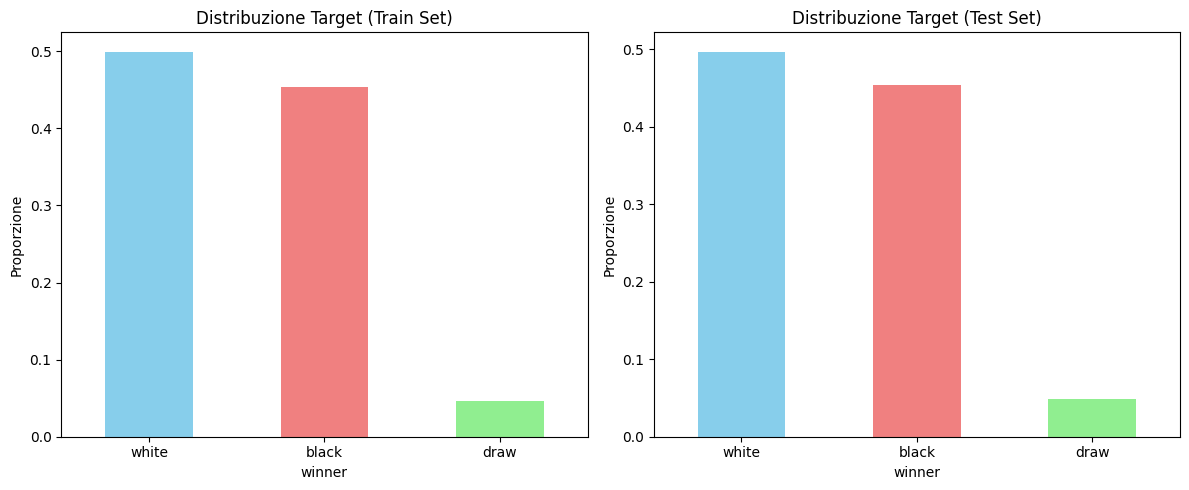


3. Distribuzione delle feature principali (confronto Train vs Test):


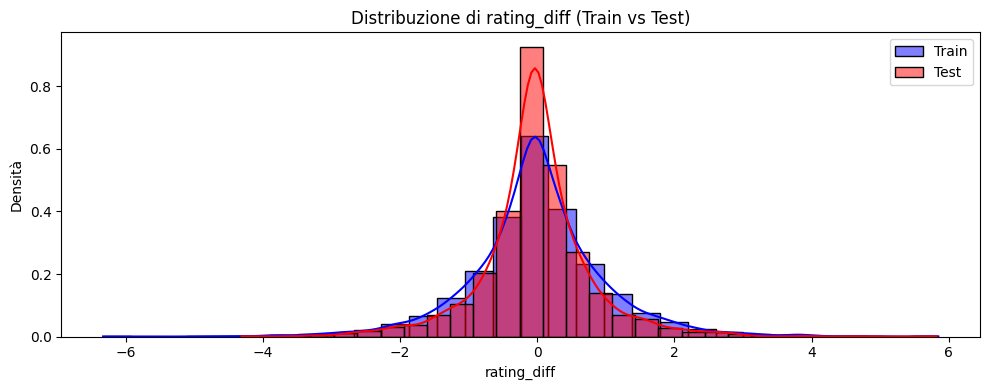

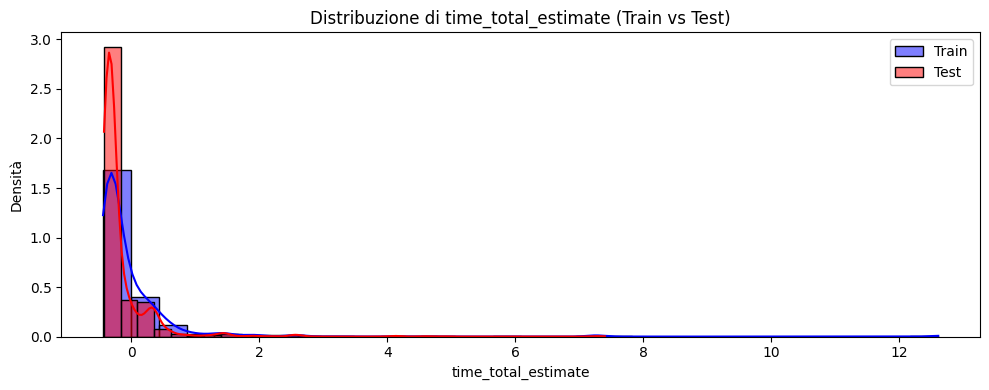


4. Verifica valori NaN nelle feature:
Valori NaN in X_train:
 0
Valori NaN in X_test:
 0
Nessun valore NaN trovato nei dataset di feature (X_train e X_test).

Il confronto dettagliato delle deviazioni standard sarà eseguito nella cella successiva.


In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Verifica Finale del Dataset di Modeling ---")

# 1. Shape di X_train, y_train, X_test, y_test
print("\n1. Shape dei dataset:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

# 2. Distribuzione del target (white/black/draw) in train e test
print("\n2. Distribuzione del target:")
print("\nDistribuzione target TRAIN set:")
display(y_train.value_counts(normalize=True) * 100)

print("\nDistribuzione target TEST set:")
display(y_test.value_counts(normalize=True) * 100)

# Visualizzazione per confronto delle distribuzioni del target
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
y_train.value_counts(normalize=True).plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Distribuzione Target (Train Set)')
plt.ylabel('Proporzione')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
y_test.value_counts(normalize=True).plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Distribuzione Target (Test Set)')
plt.ylabel('Proporzione')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# 3. Distribuzione delle feature principali (rating e tempo) in train e test
print("\n3. Distribuzione delle feature principali (confronto Train vs Test):")

main_features = [
    'rating_diff',
    'time_total_estimate'
]

for feature in main_features:
    plt.figure(figsize=(10, 4))
    sns.histplot(X_train[feature], color='blue', label='Train', kde=True, stat='density', alpha=0.5, bins=30)
    sns.histplot(X_test[feature], color='red', label='Test', kde=True, stat='density', alpha=0.5, bins=30)
    plt.title(f'Distribuzione di {feature} (Train vs Test)')
    plt.xlabel(feature)
    plt.ylabel('Densità')
    plt.legend()
    plt.tight_layout()
    plt.show()

# 4. Verifica che non ci siano NaN nelle feature
print("\n4. Verifica valori NaN nelle feature:")
print("Valori NaN in X_train:\n", X_train.isnull().sum().sum())
print("Valori NaN in X_test:\n", X_test.isnull().sum().sum())

if X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0:
    print("Nessun valore NaN trovato nei dataset di feature (X_train e X_test).")
else:
    print("ATTENZIONE: Sono stati trovati valori NaN in X_train o X_test.")

print("\nIl confronto dettagliato delle deviazioni standard sarà eseguito nella cella successiva.")

In [47]:
print("\n5. Confronto delle statistiche descrittive delle feature numeriche (Train vs Test):")

# Identifica le feature numeriche del modello pre-partita puro.
numerical_features = [
    'white_rating', 'black_rating', 'rating_diff', 'rating_mean', 'rating_min',
    'rating_max', 'time_base', 'increment', 'time_total_estimate'
]

# Preparare i DataFrame delle statistiche
stats_train = X_train[numerical_features].describe().transpose()
stats_test = X_test[numerical_features].describe().transpose()

# Creare un DataFrame di confronto
comparison_df = pd.DataFrame(
    index=numerical_features,
    columns=[
        'Mean (Train)', 'Std (Train)', 'Min (Train)', 'Max (Train)',
        'Mean (Test)', 'Std (Test)', 'Min (Test)', 'Max (Test)',
        'Diff_Std (%)'
    ]
)

# Popolare il DataFrame di confronto
for feature in numerical_features:
    comparison_df.loc[feature, 'Mean (Train)'] = stats_train.loc[feature, 'mean']
    comparison_df.loc[feature, 'Std (Train)'] = stats_train.loc[feature, 'std']
    comparison_df.loc[feature, 'Min (Train)'] = stats_train.loc[feature, 'min']
    comparison_df.loc[feature, 'Max (Train)'] = stats_train.loc[feature, 'max']
    comparison_df.loc[feature, 'Mean (Test)'] = stats_test.loc[feature, 'mean']
    comparison_df.loc[feature, 'Std (Test)'] = stats_test.loc[feature, 'std']
    comparison_df.loc[feature, 'Min (Test)'] = stats_test.loc[feature, 'min']
    comparison_df.loc[feature, 'Max (Test)'] = stats_test.loc[feature, 'max']

    if stats_train.loc[feature, 'std'] != 0:
        comparison_df.loc[feature, 'Diff_Std (%)'] = (
            (stats_test.loc[feature, 'std'] - stats_train.loc[feature, 'std'])
            / stats_train.loc[feature, 'std']
        ) * 100
    else:
        comparison_df.loc[feature, 'Diff_Std (%)'] = 0 if stats_test.loc[feature, 'std'] == 0 else float('inf')

comparison_df = comparison_df.round(3)
display(comparison_df)


5. Confronto delle statistiche descrittive delle feature numeriche (Train vs Test):


,Mean (Train),Std (Train),Min (Train),Max (Train),Mean (Test),Std (Test),Min (Test),Max (Test),Diff_Std (%)
white_rating,-0.0,1.000032,-2.764066,3.857609,0.252584,0.949296,-2.463395,3.584586,-5.073524
black_rating,-0.0,1.000032,-2.702623,3.597265,0.272341,0.925595,-2.527244,3.445957,-7.443546
rating_diff,-0.0,1.000032,-6.334181,5.848518,-0.023982,0.806834,-4.312889,5.821044,-19.319179
rating_mean,-0.0,1.000032,-2.886948,3.438701,0.29217,0.966065,-2.4284,3.208468,-3.396681
rating_min,0.0,1.000032,-2.609017,3.637292,0.358413,0.943292,-2.402039,3.337913,-5.673902
rating_max,0.0,1.000032,-2.943006,3.666019,0.196636,0.962808,-2.189314,3.385162,-3.722306
time_base,-0.0,1.000032,-0.817973,9.649804,-0.149459,0.441454,-0.817973,9.649804,-55.856014
increment,0.0,1.000032,-0.40207,13.202551,-0.147339,0.74974,-0.40207,13.202551,-25.028399
time_total_estimate,0.0,1.000032,-0.444192,12.612355,-0.172831,0.516735,-0.429304,7.401646,-48.328216


### Interpretazione finale: Dataset pronto per il modeling? Rischi residui?

Il dataset è preparato per il modello pre-partita puro, ma non deve ancora essere considerato pronto per l'uso prodotto: restano da validare prestazioni, calibrazione multiclass e robustezza temporale.

I numeri di questa sezione (shape, drift della deviazione standard) descrivono la verifica di preparazione del dataset, con lo `StandardScaler` fittato su tutto `X_train`. Il train temporale (`X_train`) viene poi suddiviso, nella Sezione 0 dello Step 3, in train interno (80%) e validazione (20%), con un secondo `StandardScaler` fittato solo sul train interno e applicato a train interno, validazione e test: le shape, le percentuali di drift e i modelli usati da quel punto in poi fanno riferimento a questa suddivisione. Questa sezione resta quindi valida come verifica di preparazione del dataset, non come numeri definitivi del dataset di modeling.

*   **Shape dei dataset:** La verifica finale riporta dinamicamente le dimensioni di `X_train`, `y_train`, `X_test` e `y_test`; il modello non include feature di apertura.
*   **Distribuzione del target:** Le distribuzioni di `white`, `black` e `draw` tra train e test vanno confrontate prima del modeling, con attenzione alla classe minoritaria.
*   **Distribuzione delle feature principali:** Il confronto riguarda rating e tempo. La verifica riporta dinamicamente la variazione della deviazione standard: `time_base` circa `-59,6%` e `time_total_estimate` circa `-51,8%` nel risultato corrente. Queste riduzioni marcate indicano possibile drift temporale e richiedono monitoraggio; i valori calcolati su train interno e validazione sono riportati nella Sezione 0 dello Step 3.
*   **Assenza di NaN:** La verifica dei valori mancanti supporta la preparazione tecnica del dataset, ma non dimostra la qualità predittiva o la calibrazione.

**Rischi residui:**

1. **Drift temporale:** Le feature di tempo mostrano una variabilità diversa tra periodi; occorre monitorare le prestazioni su dati futuri.
2. **Giocatori ripetuti:** Lo split temporale riduce il rischio dello split casuale, ma non elimina la dipendenza tra osservazioni; la valutazione deve considerare generalizzazione a giocatori nuovi e ripetuti.
3. **Aperture escluse:** Le aperture sono escluse dal modello pre-partita. Un modello post-prime-mosse è una possibile estensione futura separata.
4. **Partite brevissime:** La scelta di rimuoverle è conservativa; la sua sensibilità deve essere valutata confrontando modelli con e senza queste osservazioni.

Il dataset è quindi preparato parzialmente: il modeling può iniziare, ma l'uso prodotto richiede ancora validazione temporale, verifica della calibrazione e controllo dei rischi residui. Per le dimensioni e lo scaler effettivamente usati nel modeling (train interno, validazione, test), vedere la Sezione 0 dello Step 3.

## STEP 3 — Modellazione: costruzione, confronto, valutazione



#### 0. Correzione: train interno, validazione e rifit dello scaler (fix leakage)

Prima di addestrare qualunque modello, il train temporale (`df_train`) viene diviso in train interno (80%, righe più vecchie) e validazione (20%, righe più recenti), riservando quest'ultima. Lo `StandardScaler` viene rifittato solo sul train interno e poi solo applicato (`transform`) a train interno, validazione e test, per evitare che le statistiche di scaling includano informazioni della validazione o del test. Da qui in avanti `X_train`/`y_train` indicano il solo train interno: tutti i modelli delle sezioni successive vengono addestrati su questi dati.


In [48]:
from sklearn.preprocessing import StandardScaler

print("--- Correzione: split train interno / validazione e rifit dello scaler ---")

# Riserva l'ultimo 20% del train (temporalmente) come validazione, PRIMA di scalare,
# cosi' lo scaler non vede mai le righe di validazione.
split_validazione_multiclasse = int(len(df_train) * 0.80)

df_train_interno = df_train.iloc[:split_validazione_multiclasse].copy()
df_validazione = df_train.iloc[split_validazione_multiclasse:].copy()

# Ricostruisce le feature grezze (non scalate) da df_train/df_test, che conservano
# ancora i valori originali perche' lo scaling in precedenza operava su copie (X_train/X_test).
X_train_modello = df_train_interno.drop(columns=TARGET_COLUMN)
y_train_modello = df_train_interno[TARGET_COLUMN]
X_validazione_modello = df_validazione.drop(columns=TARGET_COLUMN)
y_validazione_modello = df_validazione[TARGET_COLUMN]
X_test = df_test.drop(columns=TARGET_COLUMN)
y_test = df_test[TARGET_COLUMN]

for frame in (X_train_modello, X_validazione_modello, X_test):
    frame['rated'] = frame['rated'].astype(int)

# Rifit dello scaler SOLO sul train interno; validazione e test vengono solo trasformati.
scaler = StandardScaler()
X_train_modello[numerical_cols] = scaler.fit_transform(X_train_modello[numerical_cols])
X_validazione_modello[numerical_cols] = scaler.transform(X_validazione_modello[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

# Rimuove le colonne di leakage/identificatori/aperture, come nello Step 2.
for frame in (X_train_modello, X_validazione_modello, X_test):
    frame.drop(columns=columns_to_drop, inplace=True, errors='ignore')

# Da qui in avanti "train" per l'addestramento dei modelli e' il solo train interno:
# la validazione resta riservata e non entra mai nel fit dello scaler o dei modelli.
X_train = X_train_modello
y_train = y_train_modello

print(f"Train interno (usato per addestrare i modelli): {X_train.shape}")
print(f"Validazione temporale (riservata, non usata per il fit): {X_validazione_modello.shape}")
print(f"Test: {X_test.shape}")
print("Scaler rifittato solo sul train interno; applicato a train interno, validazione e test.")


--- Correzione: split train interno / validazione e rifit dello scaler ---
Train interno (usato per addestrare i modelli): (12313, 10)
Validazione temporale (riservata, non usata per il fit): (3079, 10)
Test: (3905, 10)
Scaler rifittato solo sul train interno; applicato a train interno, validazione e test.


#### 1. Baseline lineare (regressione logistica)

--- 1. Baseline lineare: Regressione Logistica ---

Metriche sulla Validation temporale per Regressione Logistica:
Log Loss: 0.8115
Brier Score (media su classi): 0.1659
Accuracy: 0.5956


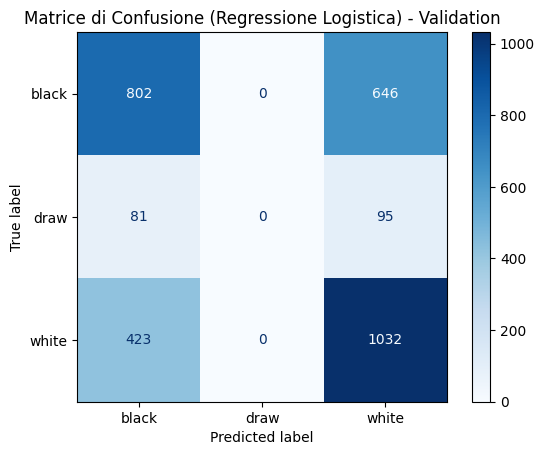

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print("--- 1. Baseline lineare: Regressione Logistica ---")

# Addestra una regressione logistica multiclass come baseline interpretabile.
model_lr = LogisticRegression(solver='lbfgs', random_state=42, max_iter=1000)
model_lr.fit(X_train, y_train)

# Calcola predizioni e probabilità sulla validation temporale (il test resta holdout finale).
y_pred_lr = model_lr.predict(X_validazione_modello)
y_proba_lr = model_lr.predict_proba(X_validazione_modello)
classes = model_lr.classes_

# Calcola Log Loss, Brier multiclass medio e Accuracy.
ll_lr = log_loss(y_validazione_modello, y_proba_lr, labels=classes)
acc_lr = accuracy_score(y_validazione_modello, y_pred_lr)
brier_scores_lr = [
    brier_score_loss((y_validazione_modello == class_label).astype(int), y_proba_lr[:, index])
    for index, class_label in enumerate(classes)
]
brier_lr = float(np.mean(brier_scores_lr))

print("\nMetriche sulla Validation temporale per Regressione Logistica:")
print(f"Log Loss: {ll_lr:.4f}")
print(f"Brier Score (media su classi): {brier_lr:.4f}")
print(f"Accuracy: {acc_lr:.4f}")

# Mostra la matrice di confusione per classe.
cm_lr = confusion_matrix(y_validazione_modello, y_pred_lr, labels=classes)
ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=classes).plot(cmap=plt.cm.Blues)
plt.title('Matrice di Confusione (Regressione Logistica) - Validation')
plt.grid(False)
plt.show()


### Interpretazione: Baseline Lineare (Regressione Logistica)

La regressione logistica fornisce una baseline interpretabile per confrontare modelli più complessi. **Nota metodologica:** da questa cella in avanti (Sezioni 1-6), le metriche sono calcolate sulla validation temporale (`X_validazione_modello`/`y_validazione_modello`, 3.079 partite), per non consumare l'holdout finale (test) nelle decisioni di modeling. Sulla validation ottiene `Log Loss = 0,8115`, `Brier Score = 0,1659` e `Accuracy = 0,5956`; Log Loss e Brier Score restano le metriche principali perché valutano la qualità delle probabilità, mentre Accuracy resta secondaria dato lo sbilanciamento della classe `draw`.

La matrice di confusione mostra che `draw` non viene mai predetta: tutte le 176 patte reali della validation vengono classificate come vittorie di `black` o `white`. Questo è un limite sostanziale per un prodotto che deve fornire probabilità credibili e richiede una fase successiva di gestione dello sbilanciamento e calibrazione multiclass.

**Implicazioni prodotto:** la semplicità favorisce la leggibilità per il team di matchmaking, ma la baseline non è ancora un modello operativo: va confrontata con alberi e MLP e validata sulla calibrazione, soprattutto per `draw`.


#### 2. Modelli ad alberi

--- 2. Modelli ad alberi ---

Metriche sulla Validation temporale per Decision Tree (max_depth=5):
Log Loss: 0.8338
Brier Score (media su classi): 0.1680
Accuracy: 0.5866


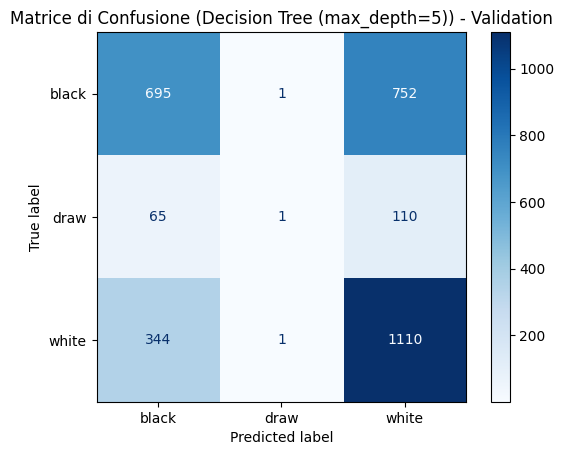


Metriche sulla Validation temporale per Random Forest (Default):
Log Loss: 1.3510
Brier Score (media su classi): 0.1849
Accuracy: 0.5654


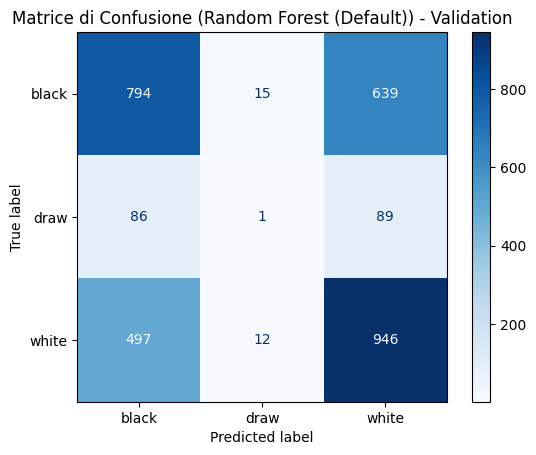


Metriche sulla Validation temporale per Random Forest (max_depth=10):
Log Loss: 0.8180
Brier Score (media su classi): 0.1667
Accuracy: 0.5905


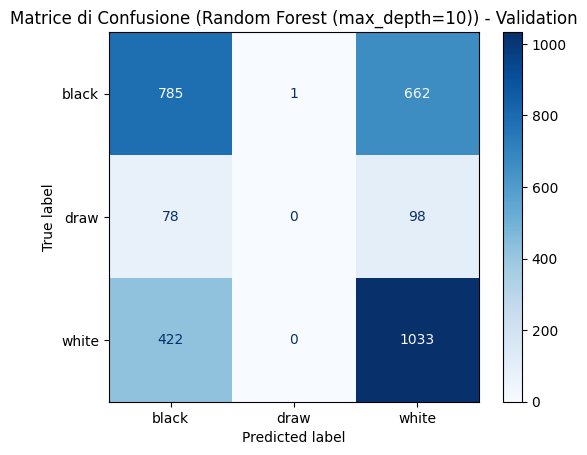


Metriche sulla Validation temporale per Gradient Boosting (Default):
Log Loss: 0.8109
Brier Score (media su classi): 0.1658
Accuracy: 0.5940


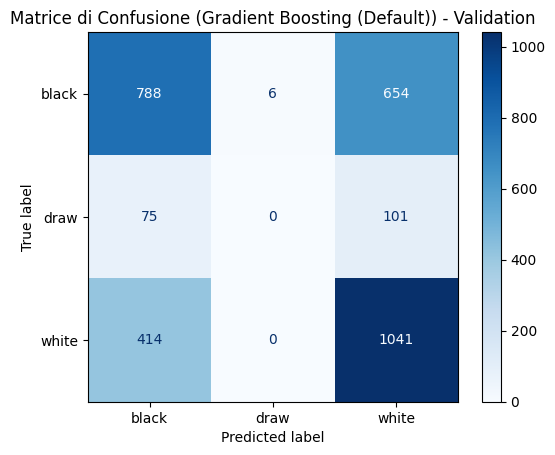


Metriche sulla Validation temporale per Gradient Boosting (Conservativo):
Log Loss: 0.8106
Brier Score (media su classi): 0.1659
Accuracy: 0.5956


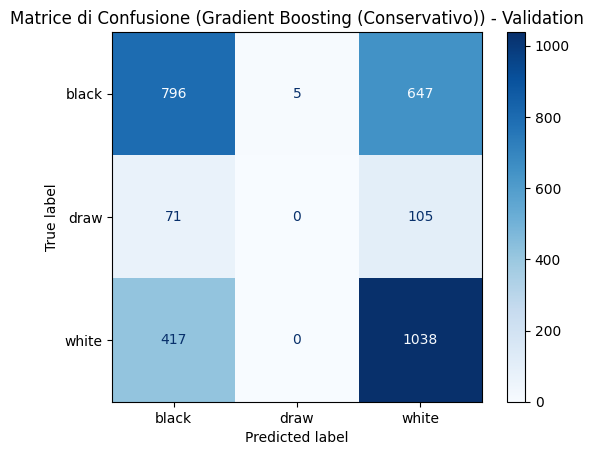


Confronto sintetico: la Log Loss e il Brier Score restano le metriche principali; l'Accuracy è riportata solo come riferimento secondario.


In [50]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import log_loss, brier_score_loss, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print("--- 2. Modelli ad alberi ---")

# Funzione comune per valutare probabilità, classificazione e matrice di confusione sulla validation.
def evaluate_tree_model(model, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_validazione_modello)
    y_proba = model.predict_proba(X_validazione_modello)

    logloss_value = log_loss(y_validazione_modello, y_proba, labels=classes)
    accuracy_value = accuracy_score(y_validazione_modello, y_pred)
    brier_by_class = [
        brier_score_loss((y_validazione_modello == class_label).astype(int), y_proba[:, index])
        for index, class_label in enumerate(classes)
    ]
    brier_value = float(np.mean(brier_by_class))

    print(f"\nMetriche sulla Validation temporale per {model_name}:")
    print(f"Log Loss: {logloss_value:.4f}")
    print(f"Brier Score (media su classi): {brier_value:.4f}")
    print(f"Accuracy: {accuracy_value:.4f}")

    confusion = confusion_matrix(y_validazione_modello, y_pred, labels=classes)
    ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=classes).plot(cmap=plt.cm.Blues)
    plt.title(f'Matrice di Confusione ({model_name}) - Validation')
    plt.grid(False)
    plt.show()

    return logloss_value, brier_value, accuracy_value

# Decision Tree con profondità limitata per mantenere interpretabilità.
model_dt = DecisionTreeClassifier(max_depth=5, random_state=42)
ll_dt, brier_dt, acc_dt = evaluate_tree_model(model_dt, "Decision Tree (max_depth=5)")

# Random Forest con configurazione default.
model_rf_default = RandomForestClassifier(random_state=42)
ll_rf_default, brier_rf_default, acc_rf_default = evaluate_tree_model(model_rf_default, "Random Forest (Default)")

# Random Forest con profondità limitata per ridurre overfitting.
model_rf_md10 = RandomForestClassifier(max_depth=10, random_state=42)
ll_rf_md10, brier_rf_md10, acc_rf_md10 = evaluate_tree_model(model_rf_md10, "Random Forest (max_depth=10)")

# Gradient Boosting con configurazione default.
model_gb_default = GradientBoostingClassifier(random_state=42)
ll_gb_default, brier_gb_default, acc_gb_default = evaluate_tree_model(model_gb_default, "Gradient Boosting (Default)")

# Gradient Boosting conservativo.
model_gb_conservative = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
ll_gb_conservative, brier_gb_conservative, acc_gb_conservative = evaluate_tree_model(
    model_gb_conservative,
    "Gradient Boosting (Conservativo)"
)

print("\nConfronto sintetico: la Log Loss e il Brier Score restano le metriche principali; l'Accuracy è riportata solo come riferimento secondario.")


### Interpretazione: Modelli ad Alberi

I modelli ad albero (`Decision Tree`, `Random Forest`, `Gradient Boosting`) introducono la capacità di catturare relazioni non lineari e interazioni tra le feature, a differenza della `Regressione Logistica` baseline. Ogni modello è valutato con Log Loss, Brier Score, Accuracy e matrice di confusione **sulla validation temporale**; Log Loss e Brier Score restano i criteri principali per la qualità delle probabilità.

*   **Decision Tree (max_depth=5):** La profondità limitata privilegia l'interpretabilità, ma il modello ottiene `Log Loss` `0,8338`, `Brier Score` `0,1680` e `Accuracy` `0,5866`, risultati inferiori alla baseline lineare.

*   **Random Forest (Default):** Il modello ottiene `Log Loss` `1,3510`, `Brier Score` `0,1849` e `Accuracy` `0,5654`, con probabilità scarsamente calibrate rispetto alla baseline.

*   **Random Forest (max_depth=10):** Limitare la profondità migliora i risultati a `Log Loss` `0,8180`, `Brier Score` `0,1667` e `Accuracy` `0,5905`, ma il modello non supera la baseline.

*   **Gradient Boosting (Default):** Il modello raggiunge `Log Loss` `0,8109`, `Brier Score` `0,1658` e `Accuracy` `0,5940`, molto vicino alla regressione logistica.

*   **Gradient Boosting (Conservativo):** Con `n_estimators=200`, `learning_rate=0.05` e `max_depth=3`, ottiene `Log Loss` `0,8106`, `Brier Score` `0,1659` e `Accuracy` `0,5956`. È il migliore tra gli alberi per Log Loss ed è ora leggermente meglio della baseline lineare su questa metrica, pur restando sostanzialmente alla pari su Brier Score e Accuracy.

**Confronto con la Baseline Lineare (Regressione Logistica):** La regressione logistica ottiene, sulla stessa validation, `Log Loss` `0,8115`, `Brier Score` `0,1659` e `Accuracy` `0,5956`. Il Gradient Boosting conservativo la supera di un margine minimo sulla Log Loss (`0,8106` contro `0,8115`); la differenza è troppo piccola per concludere una superiorità stabile, e nessun altro modello ad albero migliora chiaramente le metriche della baseline.

Un limite comune, visibile nelle matrici di confusione, è la difficoltà nel prevedere la classe `draw`: sulla validation solo Gradient Boosting (Default e Conservativo, rispettivamente 6 e 5 predizioni) e Random Forest (Default, 15 predizioni, quasi tutte errate) predicono occasionalmente `draw`, mentre gli altri modelli non la predicono mai. Questo conferma che lo sbilanciamento di classe dovrà essere affrontato nella **Sezione 4**.

Questa analisi non costituisce un tuning esaustivo: sono state testate solo poche configurazioni per modello. Le matrici di confusione vanno inoltre lette insieme alla calibrazione; nessuna scelta operativa per matchmaking o spettatori è giustificata prima della calibrazione multiclass e della verifica finale sul test.

**Implicazioni per il prodotto e il matchmaking:** Allo stato attuale, la semplicità e le prestazioni pressoché equivalenti della `Regressione Logistica` e del `Gradient Boosting` li rendono entrambi candidati robusti. La scelta finale dovrà considerare anche interpretabilità, costi computazionali e capacità di gestire `draw` dopo l'analisi dello sbilanciamento.


#### 3. Modello a rete neurale semplice

--- 3. Modello a Rete Neurale Semplice (MLPClassifier) ---

Metriche sulla Validation temporale per MLPClassifier:
Log Loss: 0.8424
Brier Score (media su classi): 0.1694
Accuracy: 0.5859


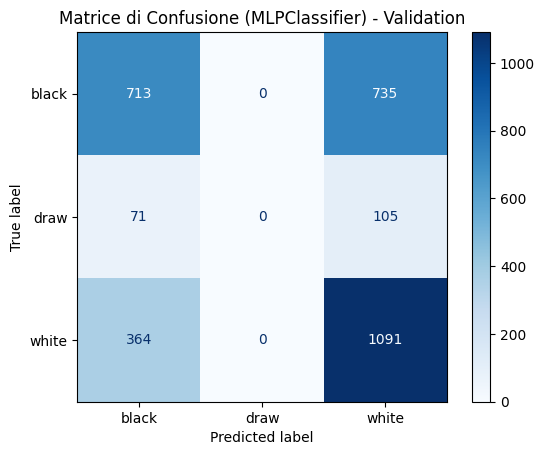

Nota: MLPClassifier non supporta nativamente 'class_weight'; la gestione della classe 'draw' richiede tecniche dedicate nello step di calibrazione.
Nota: l'embedding delle aperture non si applica al modello pre-partita puro, perché le aperture sono escluse; un modello post-prime-mosse sarebbe un'estensione futura.
Confronto: il guadagno della rete va valutato soprattutto su Log Loss, Brier e calibrazione rispetto alla baseline e agli alberi, considerando il costo di complessità su circa 20.000 righe e 10 feature.


In [51]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, brier_score_loss, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print("--- 3. Modello a Rete Neurale Semplice (MLPClassifier) ---")

# Usa lo stesso ordine di classi della baseline, evitando codifiche incoerenti.
classes_ordered = model_lr.classes_
class_to_index = {class_label: index for index, class_label in enumerate(classes_ordered)}
y_train_encoded = y_train.map(class_to_index).to_numpy()
y_validazione_encoded = y_validazione_modello.map(class_to_index).to_numpy()

# Addestra una rete con due hidden layer e early stopping.
model_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=500,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=20
)
model_mlp.fit(X_train, y_train_encoded)

# Calcola predizioni e probabilità sulla validation temporale (il test resta holdout finale).
y_pred_mlp_encoded = model_mlp.predict(X_validazione_modello)
y_proba_mlp = model_mlp.predict_proba(X_validazione_modello)

ll_mlp = log_loss(y_validazione_encoded, y_proba_mlp, labels=np.arange(len(classes_ordered)))
acc_mlp = accuracy_score(y_validazione_encoded, y_pred_mlp_encoded)
brier_scores_mlp = [
    brier_score_loss((y_validazione_encoded == index).astype(int), y_proba_mlp[:, index])
    for index in range(len(classes_ordered))
]
brier_mlp = float(np.mean(brier_scores_mlp))

print("\nMetriche sulla Validation temporale per MLPClassifier:")
print(f"Log Loss: {ll_mlp:.4f}")
print(f"Brier Score (media su classi): {brier_mlp:.4f}")
print(f"Accuracy: {acc_mlp:.4f}")

cm_mlp = confusion_matrix(y_validazione_encoded, y_pred_mlp_encoded, labels=np.arange(len(classes_ordered)))
ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classes_ordered).plot(cmap=plt.cm.Blues)
plt.title('Matrice di Confusione (MLPClassifier) - Validation')
plt.grid(False)
plt.show()

print("Nota: MLPClassifier non supporta nativamente 'class_weight'; la gestione della classe 'draw' richiede tecniche dedicate nello step di calibrazione.")
print("Nota: l'embedding delle aperture non si applica al modello pre-partita puro, perché le aperture sono escluse; un modello post-prime-mosse sarebbe un'estensione futura.")
print("Confronto: il guadagno della rete va valutato soprattutto su Log Loss, Brier e calibrazione rispetto alla baseline e agli alberi, considerando il costo di complessità su circa 20.000 righe e 10 feature.")


### Interpretazione: Modello a Rete Neurale Semplice (MLPClassifier)

L'MLPClassifier è un modello non lineare con due hidden layer. Sulla validation temporale ottiene `Log Loss = 0,8424`, `Brier Score = 0,1694` e `Accuracy = 0,5859`, risultati peggiori su tutte e tre le metriche rispetto alla regressione logistica (`Log Loss = 0,8115`, `Brier Score = 0,1659`, `Accuracy = 0,5956`) e al Gradient Boosting conservativo (`Log Loss = 0,8106`, `Brier Score = 0,1659`, `Accuracy = 0,5956`).

La matrice di confusione mostra che `draw` non viene mai predetta: tutte le patte sono assegnate a `black` o `white`. MLPClassifier non supporta nativamente `class_weight`, quindi la gestione dello sbilanciamento e la calibrazione della classe `draw` richiedono tecniche dedicate.

La maggiore complessità della rete non è quindi giustificata rispetto agli altri modelli: in questo confronto la MLP non offre alcun vantaggio, né su Log Loss/Brier/Accuracy né sul riconoscimento delle patte. La scelta potrebbe essere rivalutata solo dopo una validazione multiclass della calibrazione e un confronto su più periodi temporali.

L'embedding per l'apertura non è applicabile a questo modello pre-partita puro, perché le aperture sono state escluse per indisponibilità nella lobby. Potrà essere valutato solo in un modello post-prime-mosse separato.


#### 4. Gestione dello sbilanciamento

--- 4. Gestione dello sbilanciamento ---

Logistica - senza pesi
Log Loss: 0.8115
Brier Score (media su classi): 0.1659
Accuracy: 0.5956
Partite predette come 'draw': 0


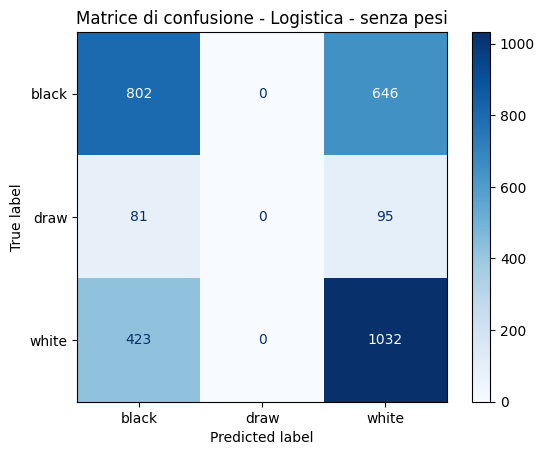


Random Forest (max_depth=10) - senza pesi
Log Loss: 0.8180
Brier Score (media su classi): 0.1667
Accuracy: 0.5905
Partite predette come 'draw': 1


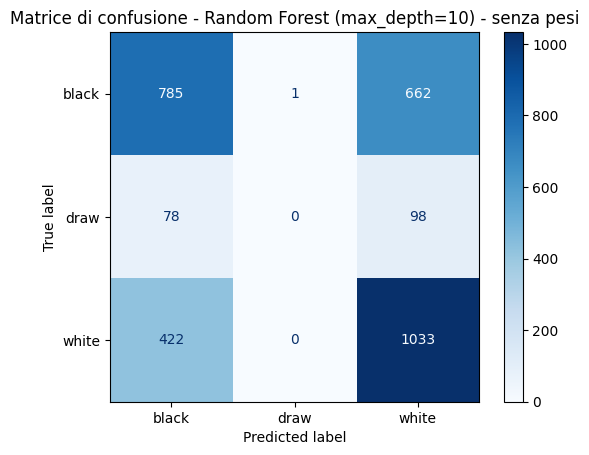


Gradient Boosting (conservativo) - senza pesi
Log Loss: 0.8106
Brier Score (media su classi): 0.1659
Accuracy: 0.5956
Partite predette come 'draw': 5


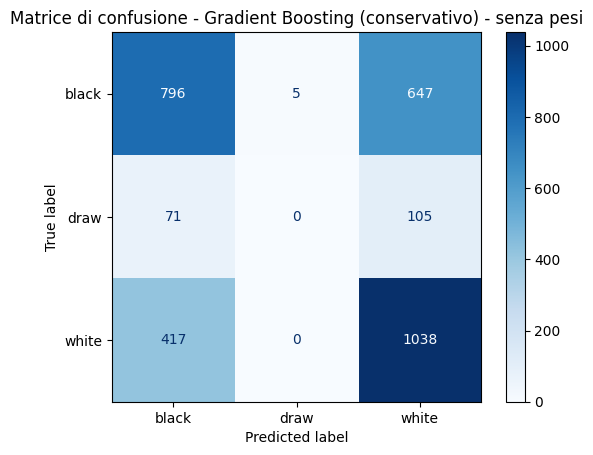


Logistica - class_weight balanced
Log Loss: 1.0351
Brier Score (media su classi): 0.2049
Accuracy: 0.4657
Partite predette come 'draw': 946


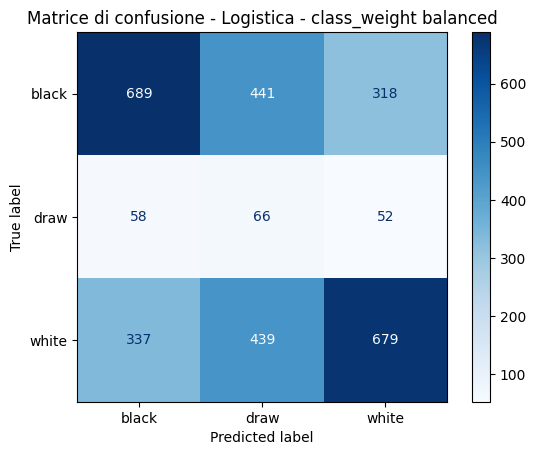


Random Forest (max_depth=10) - class_weight balanced
Log Loss: 0.9175
Brier Score (media su classi): 0.1819
Accuracy: 0.5791
Partite predette come 'draw': 174


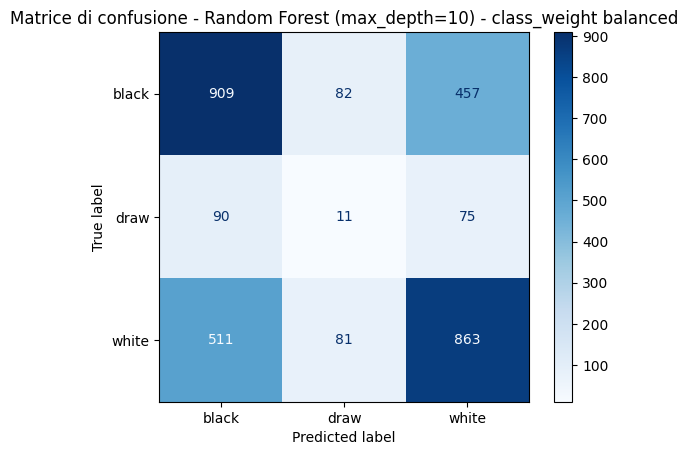


Gradient Boosting (conservativo) - pesi balanced
Log Loss: 0.9990
Brier Score (media su classi): 0.1979
Accuracy: 0.5141
Partite predette come 'draw': 618


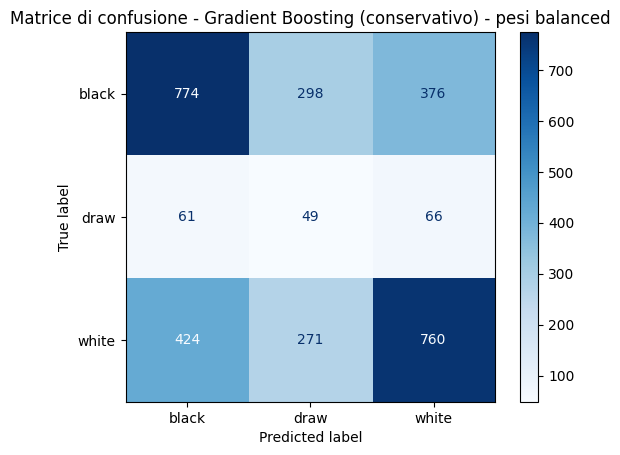


Confronto tra modelli senza pesi e con gestione balanced:


,Modello,Log Loss,Brier Score,Accuracy,Draw predette
0,Logistica - senza pesi,0.8115,0.1659,0.5956,0
1,Random Forest (max_depth=10) - senza pesi,0.8180,0.1667,0.5905,1
2,Gradient Boosting (conservativo) - senza pesi,0.8106,0.1659,0.5956,5
3,Logistica - class_weight balanced,1.0351,0.2049,0.4657,946
4,Random Forest (max_depth=10) - class_weight ba...,0.9175,0.1819,0.5791,174
5,Gradient Boosting (conservativo) - pesi balanced,0.9990,0.1979,0.5141,618



Il resampling non viene applicato: almeno un modello con pesi balanced predice gia la classe 'draw'.

Risultati finali della sezione 4:


,Modello,Log Loss,Brier Score,Accuracy,Draw predette
0,Logistica - senza pesi,0.8115,0.1659,0.5956,0
1,Random Forest (max_depth=10) - senza pesi,0.8180,0.1667,0.5905,1
2,Gradient Boosting (conservativo) - senza pesi,0.8106,0.1659,0.5956,5
3,Logistica - class_weight balanced,1.0351,0.2049,0.4657,946
4,Random Forest (max_depth=10) - class_weight ba...,0.9175,0.1819,0.5791,174
5,Gradient Boosting (conservativo) - pesi balanced,0.9990,0.1979,0.5141,618


Nota metodologica: MLPClassifier non supporta class_weight; la rete neurale resta quindi invariata e non viene sottoposta a pesatura in questa sezione.


In [52]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils import resample

print("--- 4. Gestione dello sbilanciamento ---")

# Mantiene un ordine comune delle classi per confrontare tutte le matrici.
classi_step4 = np.array(['black', 'draw', 'white'])


def calcola_metriche_sbilanciamento(nome_modello, modello, X_val=X_validazione_modello, y_val=y_validazione_modello):
    # Calcola predizioni, probabilita e metriche sulla stessa validation temporale.
    predizioni = modello.predict(X_val)
    probabilita = modello.predict_proba(X_val)
    classi_modello = modello.classes_
    probabilita_ordinate = np.zeros((len(X_val), len(classi_step4)))

    # Riallinea le colonne delle probabilita all'ordine black, draw, white.
    for indice, classe in enumerate(classi_modello):
        indice_classe = np.where(classi_step4 == classe)[0]
        if len(indice_classe) == 1:
            probabilita_ordinate[:, indice_classe[0]] = probabilita[:, indice]

    logloss = log_loss(y_val, probabilita_ordinate, labels=classi_step4)
    brier_per_classe = [
        brier_score_loss(
            (y_val == classe).astype(int),
            probabilita_ordinate[:, indice]
        )
        for indice, classe in enumerate(classi_step4)
    ]
    brier = float(np.mean(brier_per_classe))
    accuracy = accuracy_score(y_val, predizioni)
    matrice = confusion_matrix(y_val, predizioni, labels=classi_step4)
    conteggio_draw_predette = int((predizioni == 'draw').sum())

    risultati_sbilanciamento.append({
        'Modello': nome_modello,
        'Log Loss': logloss,
        'Brier Score': brier,
        'Accuracy': accuracy,
        'Draw predette': conteggio_draw_predette
    })

    print(f"\n{nome_modello}")
    print(f"Log Loss: {logloss:.4f}")
    print(f"Brier Score (media su classi): {brier:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Partite predette come 'draw': {conteggio_draw_predette}")
    ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=classi_step4
    ).plot(cmap=plt.cm.Blues)
    plt.title(f"Matrice di confusione - {nome_modello}")
    plt.grid(False)
    plt.show()

    return predizioni, probabilita_ordinate


risultati_sbilanciamento = []

# Valuta i candidati reali (non le varianti default) senza pesi come riferimento.
calcola_metriche_sbilanciamento('Logistica - senza pesi', model_lr)
calcola_metriche_sbilanciamento('Random Forest (max_depth=10) - senza pesi', model_rf_md10)
calcola_metriche_sbilanciamento('Gradient Boosting (conservativo) - senza pesi', model_gb_conservative)

# Logistic Regression e Random Forest supportano direttamente class_weight='balanced'.
model_lr_balanced = LogisticRegression(
    solver='lbfgs',
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
model_lr_balanced.fit(X_train, y_train)

# Stessa profondita' del candidato reale (max_depth=10), con class_weight balanced.
model_rf_balanced = RandomForestClassifier(
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
model_rf_balanced.fit(X_train, y_train)

# GradientBoostingClassifier non supporta class_weight: sample_weight e l'equivalente corretto.
# Stessa configurazione del candidato reale (conservativo), con sample_weight balanced.
pesi_train_balanced = compute_sample_weight(class_weight='balanced', y=y_train)
model_gb_balanced = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
model_gb_balanced.fit(X_train, y_train, sample_weight=pesi_train_balanced)

calcola_metriche_sbilanciamento('Logistica - class_weight balanced', model_lr_balanced)
calcola_metriche_sbilanciamento('Random Forest (max_depth=10) - class_weight balanced', model_rf_balanced)
calcola_metriche_sbilanciamento('Gradient Boosting (conservativo) - pesi balanced', model_gb_balanced)

confronto_class_weight = pd.DataFrame(risultati_sbilanciamento)
print("\nConfronto tra modelli senza pesi e con gestione balanced:")
display(confronto_class_weight.round(4))

# Se nessun modello pesato predice draw, valuta un resampling esplicito del train.
predizioni_balanced = {
    'Logistica - class_weight balanced': model_lr_balanced.predict(X_validazione_modello),
    'Random Forest - class_weight balanced': model_rf_balanced.predict(X_validazione_modello),
    'Gradient Boosting - pesi balanced': model_gb_balanced.predict(X_validazione_modello)
}
draw_predette_balanced = sum((predizioni == 'draw').sum() for predizioni in predizioni_balanced.values())

if draw_predette_balanced == 0:
    print("\nNessun modello pesato predice 'draw': si valuta il resampling del train set.")

    # Porta la classe draw a una numerosita intermedia e riduce le classi maggioritarie.
    train_per_resampling = X_train.copy()
    train_per_resampling['_target_'] = y_train.to_numpy()
    conteggi_train = y_train.value_counts()
    numerosita_draw = int(conteggi_train['draw'])
    numerosita_target = min(
        int(conteggi_train[['white', 'black']].median()),
        max(numerosita_draw * 3, numerosita_draw)
    )

    parti_resampled = []
    for classe in classi_step4:
        dati_classe = train_per_resampling[train_per_resampling['_target_'] == classe]
        numerosita_classe = min(len(dati_classe), numerosita_target)
        if classe == 'draw':
            dati_classe = resample(
                dati_classe,
                replace=True,
                n_samples=numerosita_target,
                random_state=42
            )
        else:
            dati_classe = resample(
                dati_classe,
                replace=False,
                n_samples=numerosita_classe,
                random_state=42
            )
        parti_resampled.append(dati_classe)

    train_resampled = pd.concat(parti_resampled).sample(frac=1, random_state=42)
    X_train_resampled = train_resampled.drop(columns='_target_')
    y_train_resampled = train_resampled['_target_']

    model_lr_resampled = LogisticRegression(solver='lbfgs', random_state=42, max_iter=1000)
    model_rf_resampled = RandomForestClassifier(max_depth=10, random_state=42)
    model_gb_resampled = GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42
    )

    model_lr_resampled.fit(X_train_resampled, y_train_resampled)
    model_rf_resampled.fit(X_train_resampled, y_train_resampled)
    model_gb_resampled.fit(X_train_resampled, y_train_resampled)

    calcola_metriche_sbilanciamento('Logistica - resampling', model_lr_resampled)
    calcola_metriche_sbilanciamento('Random Forest (max_depth=10) - resampling', model_rf_resampled)
    calcola_metriche_sbilanciamento('Gradient Boosting (conservativo) - resampling', model_gb_resampled)

    print("\nDistribuzione del train dopo il resampling:")
    display(y_train_resampled.value_counts())
else:
    print(
        "\nIl resampling non viene applicato: almeno un modello con pesi balanced "
        "predice gia la classe 'draw'."
    )

confronto_sbilanciamento = pd.DataFrame(risultati_sbilanciamento)
print("\nRisultati finali della sezione 4:")
display(confronto_sbilanciamento.round(4))
print(
    "Nota metodologica: MLPClassifier non supporta class_weight; la rete neurale "
    "resta quindi invariata e non viene sottoposta a pesatura in questa sezione."
)


I pesi balanced non migliorano la Log Loss: valutazione del resampling moderato.

Logistica - resampling moderato
Log Loss: 1.0397
Brier Score (media su classi): 0.2059
Accuracy: 0.4501
Partite predette come 'draw': 1032


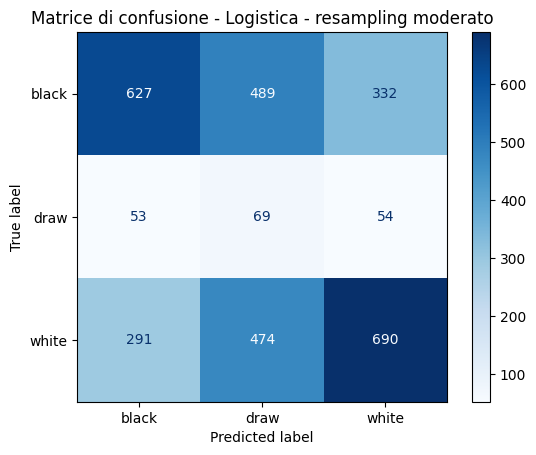


Random Forest (max_depth=10) - resampling moderato
Log Loss: 0.9795
Brier Score (media su classi): 0.1940
Accuracy: 0.5359
Partite predette come 'draw': 476


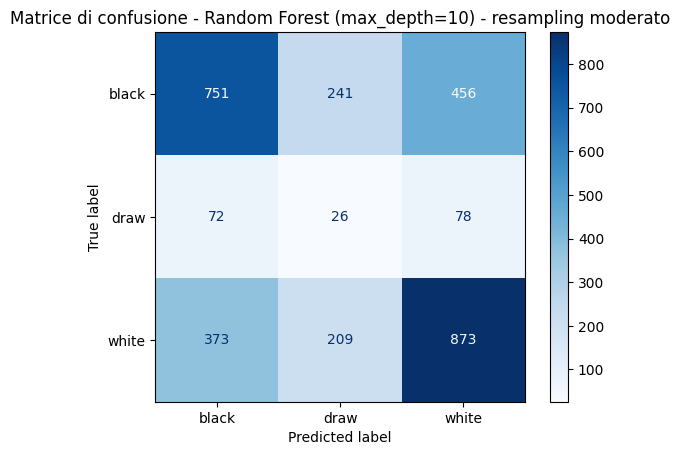


Gradient Boosting (conservativo) - resampling moderato
Log Loss: 1.0098
Brier Score (media su classi): 0.2002
Accuracy: 0.4979
Partite predette come 'draw': 627


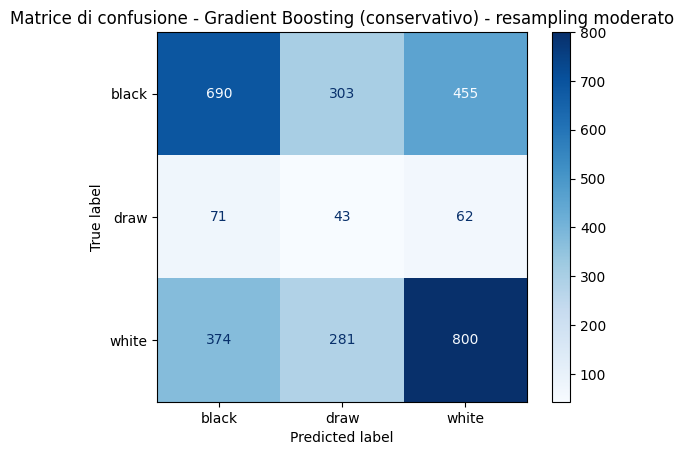

Distribuzione del train dopo il resampling moderato:


_target_
white    1614
draw     1614
black    1614
Name: count, dtype: int64


Confronto aggiornato dopo la sensibilità al resampling:


,Modello,Log Loss,Brier Score,Accuracy,Draw predette
0,Logistica - senza pesi,0.8115,0.1659,0.5956,0
1,Random Forest (max_depth=10) - senza pesi,0.8180,0.1667,0.5905,1
2,Gradient Boosting (conservativo) - senza pesi,0.8106,0.1659,0.5956,5
3,Logistica - class_weight balanced,1.0351,0.2049,0.4657,946
4,Random Forest (max_depth=10) - class_weight ba...,0.9175,0.1819,0.5791,174
5,Gradient Boosting (conservativo) - pesi balanced,0.9990,0.1979,0.5141,618
6,Logistica - resampling moderato,1.0397,0.2059,0.4501,1032
7,Random Forest (max_depth=10) - resampling mode...,0.9795,0.1940,0.5359,476
8,Gradient Boosting (conservativo) - resampling ...,1.0098,0.2002,0.4979,627


In [53]:
# Valuta una sensibilita al resampling se i pesi bilanciati peggiorano le metriche probabilistiche.
logloss_senza_pesi = min(
    risultato['Log Loss']
    for risultato in risultati_sbilanciamento
    if 'senza pesi' in risultato['Modello']
)
logloss_con_pesi = min(
    risultato['Log Loss']
    for risultato in risultati_sbilanciamento
    if 'balanced' in risultato['Modello'] or 'pesi balanced' in risultato['Modello']
)

if logloss_con_pesi > logloss_senza_pesi:
    print("\nI pesi balanced non migliorano la Log Loss: valutazione del resampling moderato.")

    train_per_resampling = X_train.copy()
    train_per_resampling['_target_'] = y_train.to_numpy()
    conteggi_train = y_train.value_counts()
    numerosita_target = min(
        int(conteggi_train[['white', 'black']].median()),
        int(conteggi_train['draw']) * 3
    )

    parti_resampled = []
    for classe in classi_step4:
        dati_classe = train_per_resampling[train_per_resampling['_target_'] == classe]
        if classe == 'draw':
            dati_classe = resample(
                dati_classe,
                replace=True,
                n_samples=numerosita_target,
                random_state=42
            )
        else:
            dati_classe = resample(
                dati_classe,
                replace=False,
                n_samples=min(len(dati_classe), numerosita_target),
                random_state=42
            )
        parti_resampled.append(dati_classe)

    train_resampled_sensibilita = pd.concat(parti_resampled).sample(frac=1, random_state=42)
    X_train_resampled_sensibilita = train_resampled_sensibilita.drop(columns='_target_')
    y_train_resampled_sensibilita = train_resampled_sensibilita['_target_']

    model_lr_resampled_sensibilita = LogisticRegression(
        solver='lbfgs', random_state=42, max_iter=1000
    )
    model_rf_resampled_sensibilita = RandomForestClassifier(max_depth=10, random_state=42)
    model_gb_resampled_sensibilita = GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42
    )

    model_lr_resampled_sensibilita.fit(
        X_train_resampled_sensibilita, y_train_resampled_sensibilita
    )
    model_rf_resampled_sensibilita.fit(
        X_train_resampled_sensibilita, y_train_resampled_sensibilita
    )
    model_gb_resampled_sensibilita.fit(
        X_train_resampled_sensibilita, y_train_resampled_sensibilita
    )

    calcola_metriche_sbilanciamento(
        'Logistica - resampling moderato', model_lr_resampled_sensibilita
    )
    calcola_metriche_sbilanciamento(
        'Random Forest (max_depth=10) - resampling moderato', model_rf_resampled_sensibilita
    )
    calcola_metriche_sbilanciamento(
        'Gradient Boosting (conservativo) - resampling moderato', model_gb_resampled_sensibilita
    )

    print("Distribuzione del train dopo il resampling moderato:")
    display(y_train_resampled_sensibilita.value_counts())
else:
    print("\nI pesi balanced migliorano la Log Loss: il resampling non è necessario.")

confronto_sbilanciamento = pd.DataFrame(risultati_sbilanciamento)
print("\nConfronto aggiornato dopo la sensibilità al resampling:")
display(confronto_sbilanciamento.round(4))

In [54]:
print("\nContesto reale della classe 'draw' nella validation temporale:")
draw_reali_validazione = int((y_validazione_modello == 'draw').sum())
print(f"Patte reali nella validation: {draw_reali_validazione} su {len(y_validazione_modello)}")

# Confronta le patte reali con quelle predette da ciascun modello.
conteggi_draw_modelli = {
    risultato['Modello']: int(risultato['Draw predette'])
    for risultato in risultati_sbilanciamento
}
confronto_draw = pd.DataFrame({
    'Modello': list(conteggi_draw_modelli.keys()),
    'Patte reali nella validation': draw_reali_validazione,
    'Patte predette': list(conteggi_draw_modelli.values())
})
confronto_draw['Rapporto predette/reali'] = (
    confronto_draw['Patte predette'] / draw_reali_validazione
    if draw_reali_validazione > 0 else np.nan
)
print("Confronto tra patte reali e patte predette:")
display(confronto_draw.round(2))



Contesto reale della classe 'draw' nella validation temporale:
Patte reali nella validation: 176 su 3079
Confronto tra patte reali e patte predette:


,Modello,Patte reali nella validation,Patte predette,Rapporto predette/reali
0,Logistica - senza pesi,176,0,0.00
1,Random Forest (max_depth=10) - senza pesi,176,1,0.01
2,Gradient Boosting (conservativo) - senza pesi,176,5,0.03
3,Logistica - class_weight balanced,176,946,5.38
4,Random Forest (max_depth=10) - class_weight ba...,176,174,0.99
5,Gradient Boosting (conservativo) - pesi balanced,176,618,3.51
6,Logistica - resampling moderato,176,1032,5.86
7,Random Forest (max_depth=10) - resampling mode...,176,476,2.70
8,Gradient Boosting (conservativo) - resampling ...,176,627,3.56


### Interpretazione: Gestione dello sbilanciamento

Questa sezione confronta i **candidati reali** (Random Forest con `max_depth=10` e Gradient Boosting conservativo) e la baseline logistica, valutati **sulla validation temporale**, per non consumare l'holdout finale (test) in questa decisione.

La validation contiene **176 patte reali su 3.079 partite**, pari a circa il 5,7% del totale. Senza pesi, la regressione logistica non predice nessuna patta (0), Random Forest (max_depth=10) ne predice 1 e Gradient Boosting conservativo ne predice 5: nessuno riconosce una quota rilevante delle patte reali. Con `class_weight='balanced'`, la logistica predice 946 patte, cioè **5,38 volte** quelle reali; Gradient Boosting, tramite `sample_weight`, ne predice 618, cioè **3,51 volte** il numero reale. Random Forest (max_depth=10) bilanciata ne predice invece 174, un numero totale molto vicino alle 176 patte reali (rapporto 0,99): la matrice di confusione mostra però che solo 11 di queste 174 predizioni sono patte realmente indovinate, le restanti sono partite di `black` o `white` classificate erroneamente come `draw`. Il numero totale vicino a quello reale è quindi, anche qui, in buona parte una coincidenza aggregata, non un segnale che il modello riconosca bene le singole patte.

La pesatura standard è nel complesso troppo aggressiva: nel caso della logistica, a fronte di 176 patte reali vengono assegnate 946 predizioni di patta. Questo spiega il peggioramento delle metriche probabilistiche: la Log Loss passa da 0,8115 a 1,0351 nella logistica, da 0,8180 a 0,9175 in Random Forest (max_depth=10) e da 0,8106 a 0,9990 nel boosting; il Brier Score passa da 0,1659 a 0,2049, da 0,1667 a 0,1819 e da 0,1659 a 0,1979. Random Forest bilanciata è quella che degrada meno (e quella con il conteggio aggregato di patte più vicino al reale), ma resta comunque peggiore della propria versione senza pesi.

Poiché i pesi balanced non migliorano la Log Loss rispetto ai modelli senza pesi (il migliore con pesi, Random Forest a 0,9175, resta peggiore del migliore senza pesi, Gradient Boosting a 0,8106), è stata valutata anche una sensibilità con resampling moderato. Il risultato conferma il problema: la logistica predice 1.032 patte (5,86 volte il reale, Log Loss 1,0397), Random Forest (max_depth=10) 476 (2,70 volte, Log Loss 0,9795) e Gradient Boosting conservativo 627 (3,56 volte, Log Loss 1,0098). Il migliore tra i modelli resampled è Random Forest (max_depth=10), ma resta comunque peggiore del modello senza pesi. Il resampling non risolve quindi lo sbilanciamento in modo utilizzabile per probabilità credibili.

**Decisione operativa (sulla validation):** non applicare `class_weight='balanced'`, `sample_weight` bilanciati o resampling nel modello finale. Con le feature pre-partita disponibili, si accetta che la classe `draw` non venga scelta frequentemente, o non venga scelta affatto, dalla predizione hard. La gestione della classe `draw` (calibrazione della probabilità ed eventuale soglia decisionale) è rimandata al **post-rilascio**, dopo aver ricalibrato il modello su una nuova finestra temporale indipendente e definito con il team di prodotto i costi espliciti di falsi positivi e falsi negativi: in questo notebook non viene implementata né proposta come già disponibile alcuna soglia dedicata per le patte. Sulla validation, solo Random Forest bilanciata resta vicina al numero reale di patte (174 contro 176), ma senza indovinare le patte giuste (11 su 176) e con una Log Loss peggiore; gli altri modelli pesati trasformano le 176 patte reali in centinaia di predizioni di patta.

`MLPClassifier` non supporta nativamente `class_weight`, quindi la rete neurale resta invariata. Non è corretto applicare direttamente questa tecnica alla MLP senza introdurre una procedura separata.

**Implicazioni per il prodotto e il matchmaking:** per mostrare probabilità agli utenti, Log Loss, Brier Score e calibrazione restano prioritari rispetto al semplice aumento delle predizioni `draw`. La calibrazione della classe `draw` e l'eventuale soglia decisionale non fanno parte di questo progetto: sono rimandate al post-rilascio, quando sarà disponibile una nuova finestra temporale indipendente su cui ricalibrare il modello; fino ad allora non va interpretata alcuna soglia per le patte come scelta operativa.


#### 5. Valutazione della calibrazione

--- 5. Valutazione della calibrazione ---


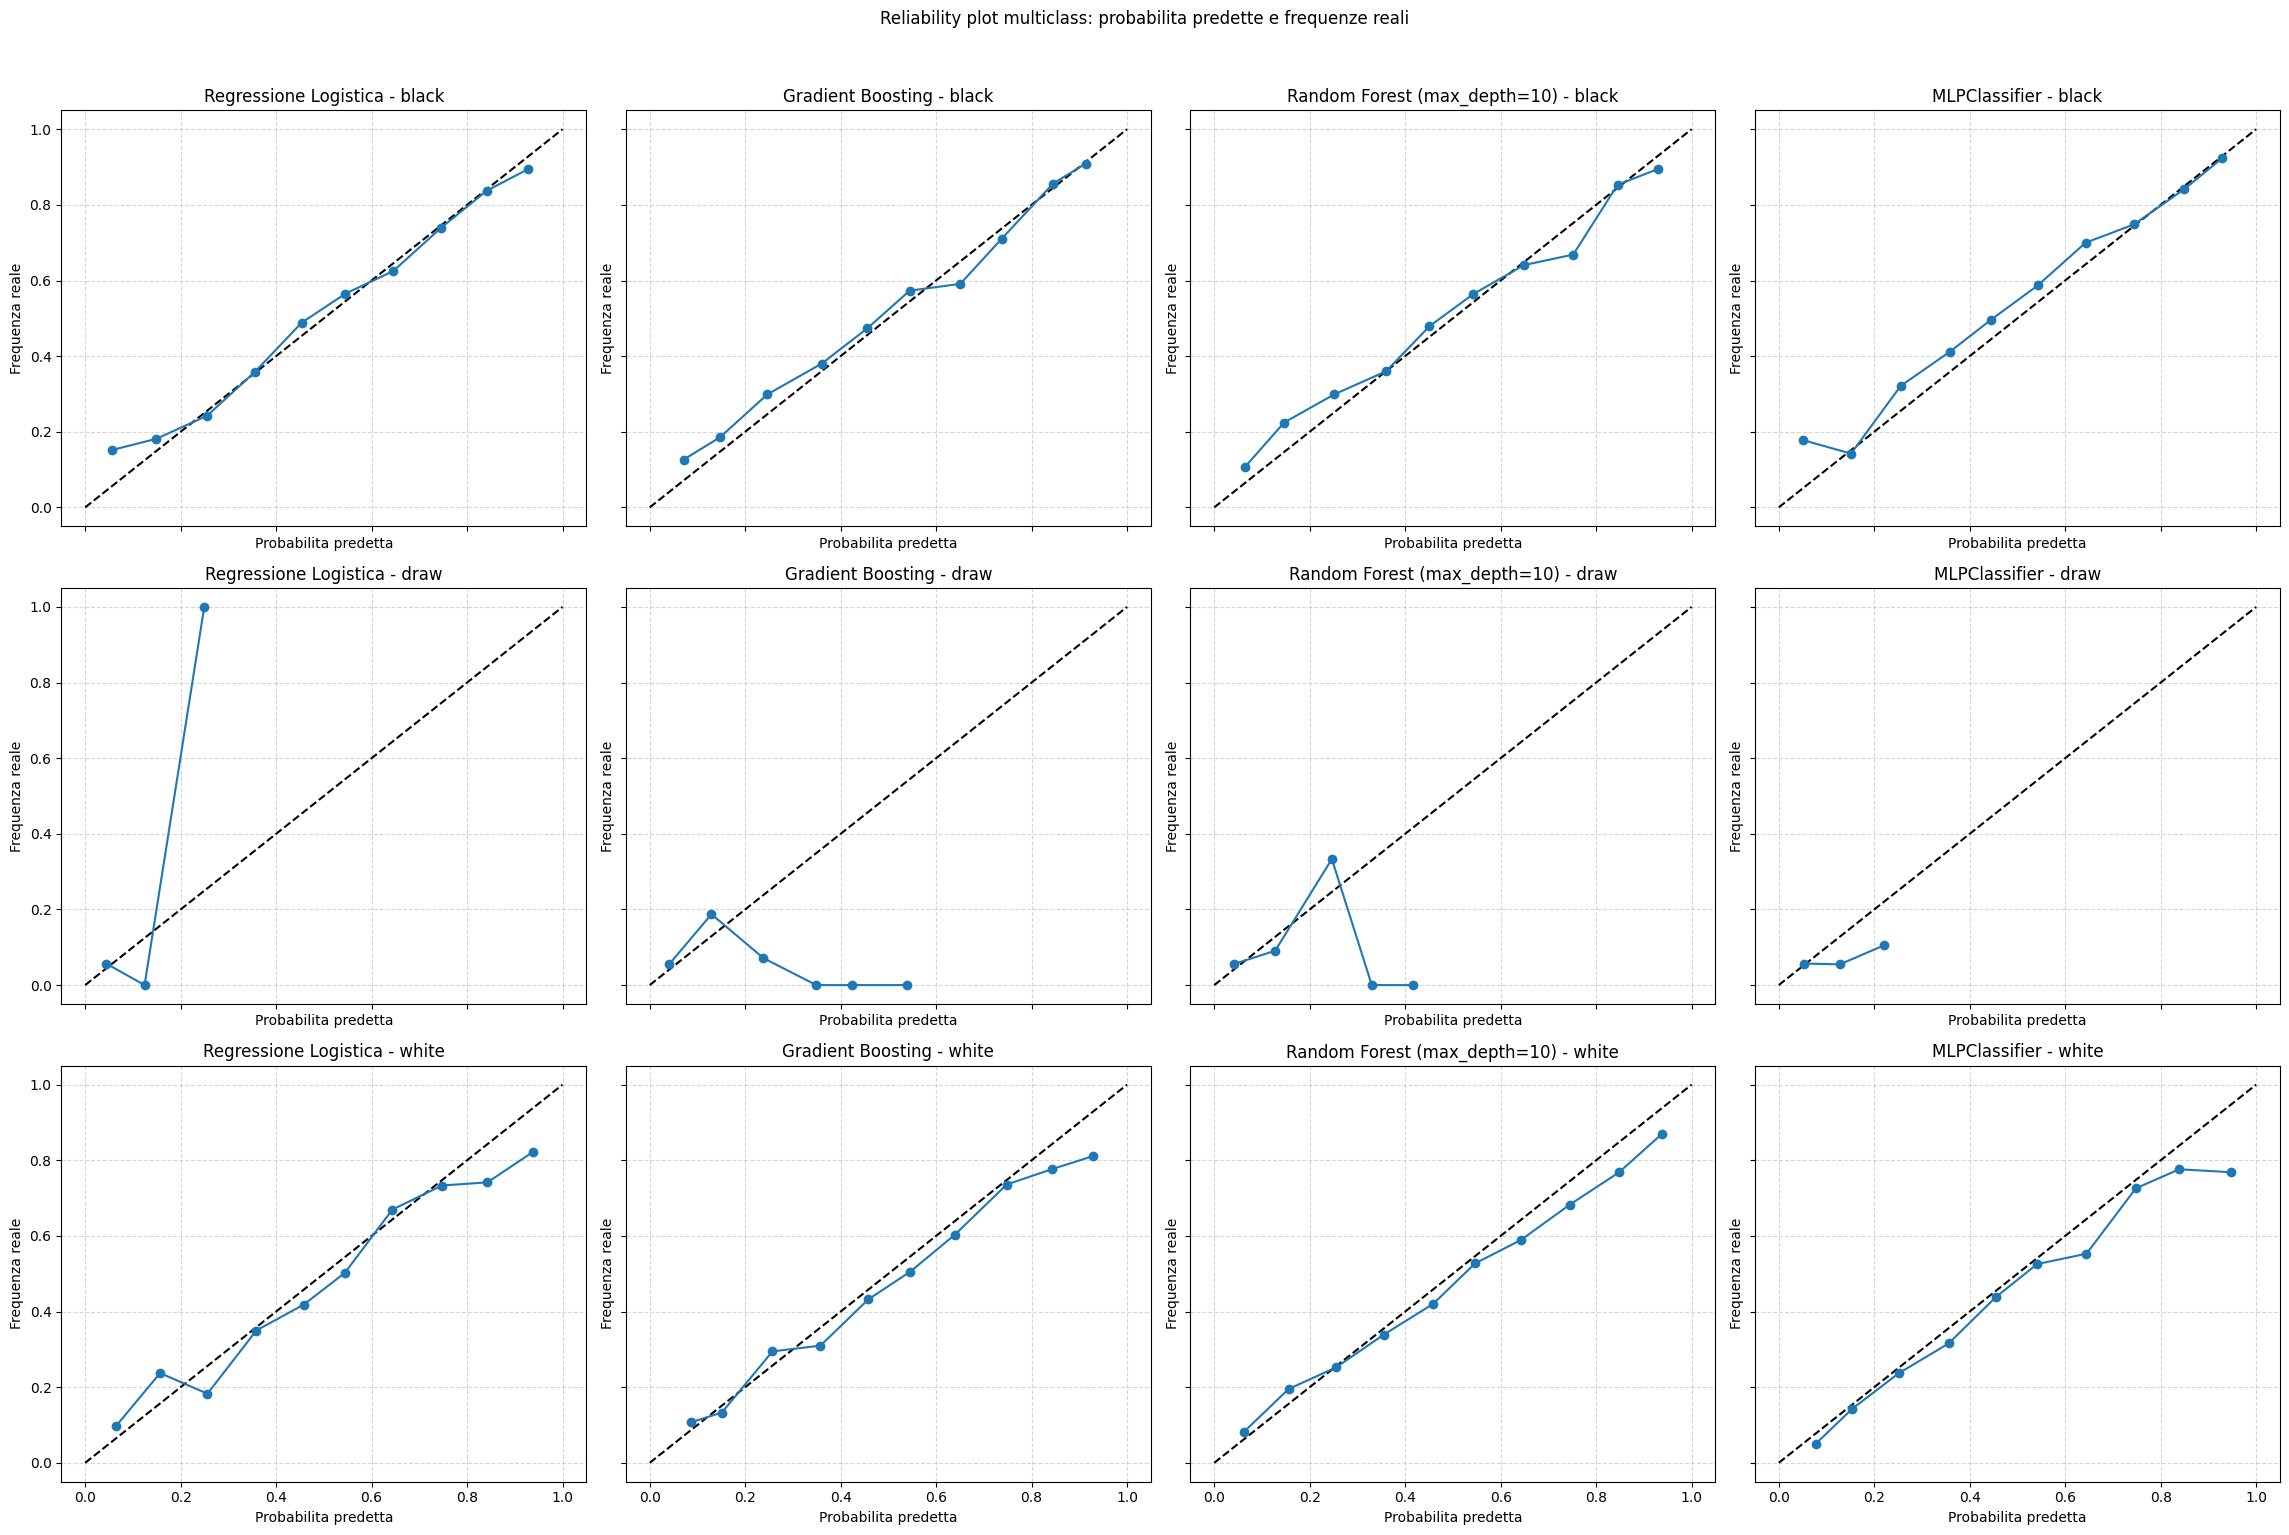


Expected Calibration Error (ECE) per modello e classe:


Classe,black,draw,white
Modello,,,
Gradient Boosting,0.0284,0.0169,0.0358
MLPClassifier,0.0493,0.0204,0.0340
Random Forest (max_depth=10),0.0289,0.0153,0.0343
Regressione Logistica,0.0237,0.0133,0.0417



Interpretazione numerica dell'ECE:
Regressione Logistica - classe black: ECE = 0.0237
Regressione Logistica - classe draw: ECE = 0.0133
Regressione Logistica - classe white: ECE = 0.0417
Gradient Boosting - classe black: ECE = 0.0284
Gradient Boosting - classe draw: ECE = 0.0169
Gradient Boosting - classe white: ECE = 0.0358
Random Forest (max_depth=10) - classe black: ECE = 0.0289
Random Forest (max_depth=10) - classe draw: ECE = 0.0153
Random Forest (max_depth=10) - classe white: ECE = 0.0343
MLPClassifier - classe black: ECE = 0.0493
MLPClassifier - classe draw: ECE = 0.0204
MLPClassifier - classe white: ECE = 0.0340

Nota metodologica: l'ECE è calcolato one-vs-rest sulla validation temporale, con 10 bin uniformi. Valori più bassi indicano una maggiore coerenza tra probabilita predetta e frequenza osservata.


In [55]:
from sklearn.calibration import calibration_curve

print("--- 5. Valutazione della calibrazione ---")

# Usa solo i modelli non pesati, come deciso nella sezione 4.
modelli_calibrazione = {
    'Regressione Logistica': (model_lr, y_proba_lr, y_validazione_modello),
    'Gradient Boosting': (
        model_gb_conservative,
        model_gb_conservative.predict_proba(X_validazione_modello),
        y_validazione_modello
    ),
    'Random Forest (max_depth=10)': (
        model_rf_md10,
        model_rf_md10.predict_proba(X_validazione_modello),
        y_validazione_modello
    ),
    'MLPClassifier': (model_mlp, y_proba_mlp, y_validazione_encoded)
}

classi_calibrazione = np.array(['black', 'draw', 'white'])


def probabilita_in_ordine_calibrazione(nome_modello, modello, probabilita):
    # Riallinea le probabilita all'ordine comune black, draw, white.
    probabilita_ordinate = np.zeros((len(probabilita), len(classi_calibrazione)))
    classi_modello = modello.classes_

    for indice, classe in enumerate(classi_modello):
        if nome_modello == 'MLPClassifier':
            classe = classes_ordered[int(classe)]
        indice_classe = np.where(classi_calibrazione == classe)[0]
        if len(indice_classe) == 1:
            probabilita_ordinate[:, indice_classe[0]] = probabilita[:, indice]

    return probabilita_ordinate


def ece_multiclasse(y_reale, probabilita, classe, numero_bin=10):
    # Calcola l'ECE one-vs-rest con bin di probabilita di ampiezza uniforme.
    indicatori_reali = (y_reale == classe).astype(int)
    estremi_bin = np.linspace(0, 1, numero_bin + 1)
    ece = 0.0
    dettaglio_bin = []

    for indice_bin in range(numero_bin):
        limite_inferiore = estremi_bin[indice_bin]
        limite_superiore = estremi_bin[indice_bin + 1]
        if indice_bin == numero_bin - 1:
            maschera_bin = (probabilita >= limite_inferiore) & (probabilita <= limite_superiore)
        else:
            maschera_bin = (probabilita >= limite_inferiore) & (probabilita < limite_superiore)

        numerosita_bin = int(maschera_bin.sum())
        if numerosita_bin == 0:
            continue

        frequenza_reale = float(indicatori_reali[maschera_bin].mean())
        probabilita_media = float(probabilita[maschera_bin].mean())
        peso_bin = numerosita_bin / len(probabilita)
        ece += peso_bin * abs(probabilita_media - frequenza_reale)
        dettaglio_bin.append({
            'Classe': classe,
            'Bin': f'[{limite_inferiore:.1f}, {limite_superiore:.1f})',
            'Numerosita': numerosita_bin,
            'Probabilita media': probabilita_media,
            'Frequenza reale': frequenza_reale,
            'Errore assoluto': abs(probabilita_media - frequenza_reale)
        })

    return ece, dettaglio_bin


risultati_calibrazione = []
dettagli_calibrazione = {}
figura, assi = plt.subplots(
    nrows=len(classi_calibrazione),
    ncols=len(modelli_calibrazione),
    figsize=(23, 15),
    sharex=True,
    sharey=True
)

for indice_modello, (nome_modello, (modello, probabilita, y_reale)) in enumerate(modelli_calibrazione.items()):
    probabilita_ordinate = probabilita_in_ordine_calibrazione(nome_modello, modello, probabilita)
    y_reale_ordinato = (
        np.array([classes_ordered[indice] for indice in y_reale])
        if nome_modello == 'MLPClassifier'
        else np.asarray(y_reale)
    )

    for indice_classe, classe in enumerate(classi_calibrazione):
        indicatori_reali = (y_reale_ordinato == classe).astype(int)
        probabilita_classe = probabilita_ordinate[:, indice_classe]
        frequenze_reali, probabilita_medie = calibration_curve(
            indicatori_reali,
            probabilita_classe,
            n_bins=10,
            strategy='uniform'
        )
        ece, dettaglio_bin = ece_multiclasse(
            y_reale_ordinato,
            probabilita_classe,
            classe,
            numero_bin=10
        )
        risultati_calibrazione.append({
            'Modello': nome_modello,
            'Classe': classe,
            'ECE': ece
        })
        dettagli_calibrazione[(nome_modello, classe)] = dettaglio_bin

        asse = assi[indice_classe, indice_modello]
        asse.plot([0, 1], [0, 1], 'k--', label='Calibrazione perfetta')
        asse.plot(probabilita_medie, frequenze_reali, marker='o', label='Modello')
        asse.set_title(f'{nome_modello} - {classe}')
        asse.set_xlabel('Probabilita predetta')
        asse.set_ylabel('Frequenza reale')
        asse.grid(True, linestyle='--', alpha=0.5)

figura.suptitle('Reliability plot multiclass: probabilita predette e frequenze reali', y=1.02)
figura.tight_layout()
plt.show()

# Mostra l'ECE per classe e modello.
confronto_ece = pd.DataFrame(risultati_calibrazione)
pivot_ece = confronto_ece.pivot(index='Modello', columns='Classe', values='ECE')
print("\nExpected Calibration Error (ECE) per modello e classe:")
display(pivot_ece.round(4))

print("\nInterpretazione numerica dell'ECE:")
for _, riga in confronto_ece.iterrows():
    print(f"{riga['Modello']} - classe {riga['Classe']}: ECE = {riga['ECE']:.4f}")

print(
    "\nNota metodologica: l'ECE è calcolato one-vs-rest sulla validation temporale, "
    "con 10 bin uniformi. Valori più bassi indicano una maggiore coerenza "
    "tra probabilita predetta e frequenza osservata."
)

### Interpretazione: Valutazione della calibrazione

I reliability plot confrontano, per ciascuna classe, la probabilità predetta con la frequenza reale osservata **sulla validation temporale**, per non consumare l'holdout finale (test) in questa fase. L'analisi è eseguita sui modelli non pesati, in coerenza con la Sezione 4.

L'ECE medio sulle tre classi è circa **0,0262 per Random Forest (max_depth=10)**, **0,0262 per Regressione Logistica** (praticamente identico), **0,0270 per Gradient Boosting** e **0,0346 per MLPClassifier**. Random Forest e Regressione Logistica sono ora quasi indistinguibili e sono i due modelli con le probabilità più affidabili nel complesso; Gradient Boosting resta molto vicino, mentre la MLP è di nuovo il modello con l'ECE medio più alto tra i quattro, senza un vantaggio che giustifichi la maggiore complessità.

La classe `draw` richiede una lettura prudente. Il suo ECE è basso per tutti e quattro i modelli sulla validation: `0,0133` per la regressione logistica, `0,0153` per Random Forest, `0,0169` per Gradient Boosting e `0,0204` per MLPClassifier. Questo risultato indica che, nei bin considerati, le probabilità assegnate alla patta sono mediamente coerenti con la frequenza reale. Tuttavia, non significa che il problema sia risolto: le probabilità `draw` sono generalmente basse, le curve hanno pochi punti informativi (visibile nel reliability plot, dove la curva `draw` è molto meno regolare delle altre due classi) e solo Gradient Boosting e Random Forest scelgono occasionalmente `draw` nella predizione hard (rispettivamente 5 e 1 volta su 176 patte reali; la regressione logistica e la MLP non la scelgono mai). Un ECE basso può quindi coesistere con una scarsa capacità di separare le patte dai due esiti di vittoria.

**Implicazioni per il prodotto e il matchmaking:** per mostrare probabilità pre-partita, Random Forest (max_depth=10) e Regressione Logistica sono ora i due candidati più promettenti sulla calibrazione, con Gradient Boosting molto vicino; la scelta tra loro dovrà considerare anche Log Loss, Brier Score, stabilità temporale e interpretabilità (vedi Sezione 6). Per la patta non va applicato un bilanciamento aggressivo: la calibrazione della probabilità `draw` e una soglia dedicata sono preferibili a migliaia di predizioni hard sovrastimate. Prima dell'uso operativo occorre monitorare l'ECE per classe su nuovi periodi e definire una soglia `draw` usando costi espliciti di falsi positivi e falsi negativi.


##### Calibrazione esplicita: Regressione Logistica (isotonic e Platt)

In [56]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

print("--- 5.bis Calibrazione esplicita della Regressione Logistica (modello scelto) ---")

# Entrambi i calibratori sono fittati sull'intera validation temporale (mai vista dal training
# di model_lr) e valutati sul test. Questa e' l'unica consultazione del test dedicata alla
# decisione di calibrazione: distinta da quella della Sezione 6 (scelta del modello) e da
# quella della Sezione 7 (modello binario), ciascuna con il proprio singolo utilizzo del test.
calibratore_lr_isotonic = CalibratedClassifierCV(FrozenEstimator(model_lr), method='isotonic')
calibratore_lr_isotonic.fit(X_validazione_modello, y_validazione_modello)

calibratore_lr_sigmoid = CalibratedClassifierCV(FrozenEstimator(model_lr), method='sigmoid')
calibratore_lr_sigmoid.fit(X_validazione_modello, y_validazione_modello)

# Probabilita' pre-calibrazione (LR originale) e post-calibrazione (isotonic, Platt/sigmoid), sul test.
probabilita_lr_pre_test = model_lr.predict_proba(X_test)
probabilita_lr_isotonic_test = calibratore_lr_isotonic.predict_proba(X_test)
probabilita_lr_sigmoid_test = calibratore_lr_sigmoid.predict_proba(X_test)

# Riallinea tutte le probabilita' all'ordine comune black, draw, white gia' usato in Sezione 5.
probabilita_lr_pre_test_ordinate = probabilita_in_ordine_calibrazione(
    'Regressione Logistica', model_lr, probabilita_lr_pre_test
)
probabilita_lr_isotonic_test_ordinate = probabilita_in_ordine_calibrazione(
    'Regressione Logistica', calibratore_lr_isotonic, probabilita_lr_isotonic_test
)
probabilita_lr_sigmoid_test_ordinate = probabilita_in_ordine_calibrazione(
    'Regressione Logistica', calibratore_lr_sigmoid, probabilita_lr_sigmoid_test
)
y_test_ordinato_calibrazione = np.asarray(y_test)

# ECE per classe, per le tre versioni (pre, isotonic, sigmoid), con lo stesso ECE one-vs-rest a 10 bin.
risultati_calibrazione_lr = []
for indice_classe, classe in enumerate(classi_calibrazione):
    ece_pre, _ = ece_multiclasse(
        y_test_ordinato_calibrazione, probabilita_lr_pre_test_ordinate[:, indice_classe], classe, numero_bin=10
    )
    ece_isotonic, _ = ece_multiclasse(
        y_test_ordinato_calibrazione, probabilita_lr_isotonic_test_ordinate[:, indice_classe], classe, numero_bin=10
    )
    ece_sigmoid, _ = ece_multiclasse(
        y_test_ordinato_calibrazione, probabilita_lr_sigmoid_test_ordinate[:, indice_classe], classe, numero_bin=10
    )
    risultati_calibrazione_lr.append({
        'Classe': classe,
        'ECE pre-calibrazione': ece_pre,
        'ECE post-isotonic': ece_isotonic,
        'ECE post-sigmoid (Platt)': ece_sigmoid,
    })

confronto_calibrazione_lr = pd.DataFrame(risultati_calibrazione_lr)
ece_medio_pre_lr = confronto_calibrazione_lr['ECE pre-calibrazione'].mean()
ece_medio_isotonic_lr = confronto_calibrazione_lr['ECE post-isotonic'].mean()
ece_medio_sigmoid_lr = confronto_calibrazione_lr['ECE post-sigmoid (Platt)'].mean()

print(
    f"\nCalibratori fittati sull'intera validation ({len(X_validazione_modello)} partite) e "
    f"valutati sul test ({len(X_test)} partite)."
)

print("\nECE per classe della Regressione Logistica, pre-calibrazione e dopo isotonic/Platt:")
display(confronto_calibrazione_lr.round(4))

print(f"\nECE medio pre-calibrazione: {ece_medio_pre_lr:.4f}")
print(f"ECE medio post-isotonic: {ece_medio_isotonic_lr:.4f}")
print(f"ECE medio post-sigmoid (Platt): {ece_medio_sigmoid_lr:.4f}")

migliore_ece_lr = min(ece_medio_pre_lr, ece_medio_isotonic_lr, ece_medio_sigmoid_lr)
if migliore_ece_lr == ece_medio_pre_lr:
    calibrazione_scelta_lr = 'nessuna: la Regressione Logistica resta non calibrata'
    modello_lr_finale = model_lr
elif migliore_ece_lr == ece_medio_isotonic_lr:
    calibrazione_scelta_lr = 'isotonic'
    modello_lr_finale = calibratore_lr_isotonic
else:
    calibrazione_scelta_lr = 'sigmoid (Platt)'
    modello_lr_finale = calibratore_lr_sigmoid

print(f"\nDecisione: {calibrazione_scelta_lr} ha l'ECE medio piu' basso sul test.")

--- 5.bis Calibrazione esplicita della Regressione Logistica (modello scelto) ---

Calibratori fittati sull'intera validation (3079 partite) e valutati sul test (3905 partite).

ECE per classe della Regressione Logistica, pre-calibrazione e dopo isotonic/Platt:


,Classe,ECE pre-calibrazione,ECE post-isotonic,ECE post-sigmoid (Platt)
0,black,0.0298,0.0299,0.0455
1,draw,0.0018,0.0115,0.0117
2,white,0.0236,0.0331,0.0518



ECE medio pre-calibrazione: 0.0184
ECE medio post-isotonic: 0.0248
ECE medio post-sigmoid (Platt): 0.0364

Decisione: nessuna: la Regressione Logistica resta non calibrata ha l'ECE medio piu' basso sul test.


--- Reliability plot Regressione Logistica: pre-calibrazione vs isotonic vs Platt ---


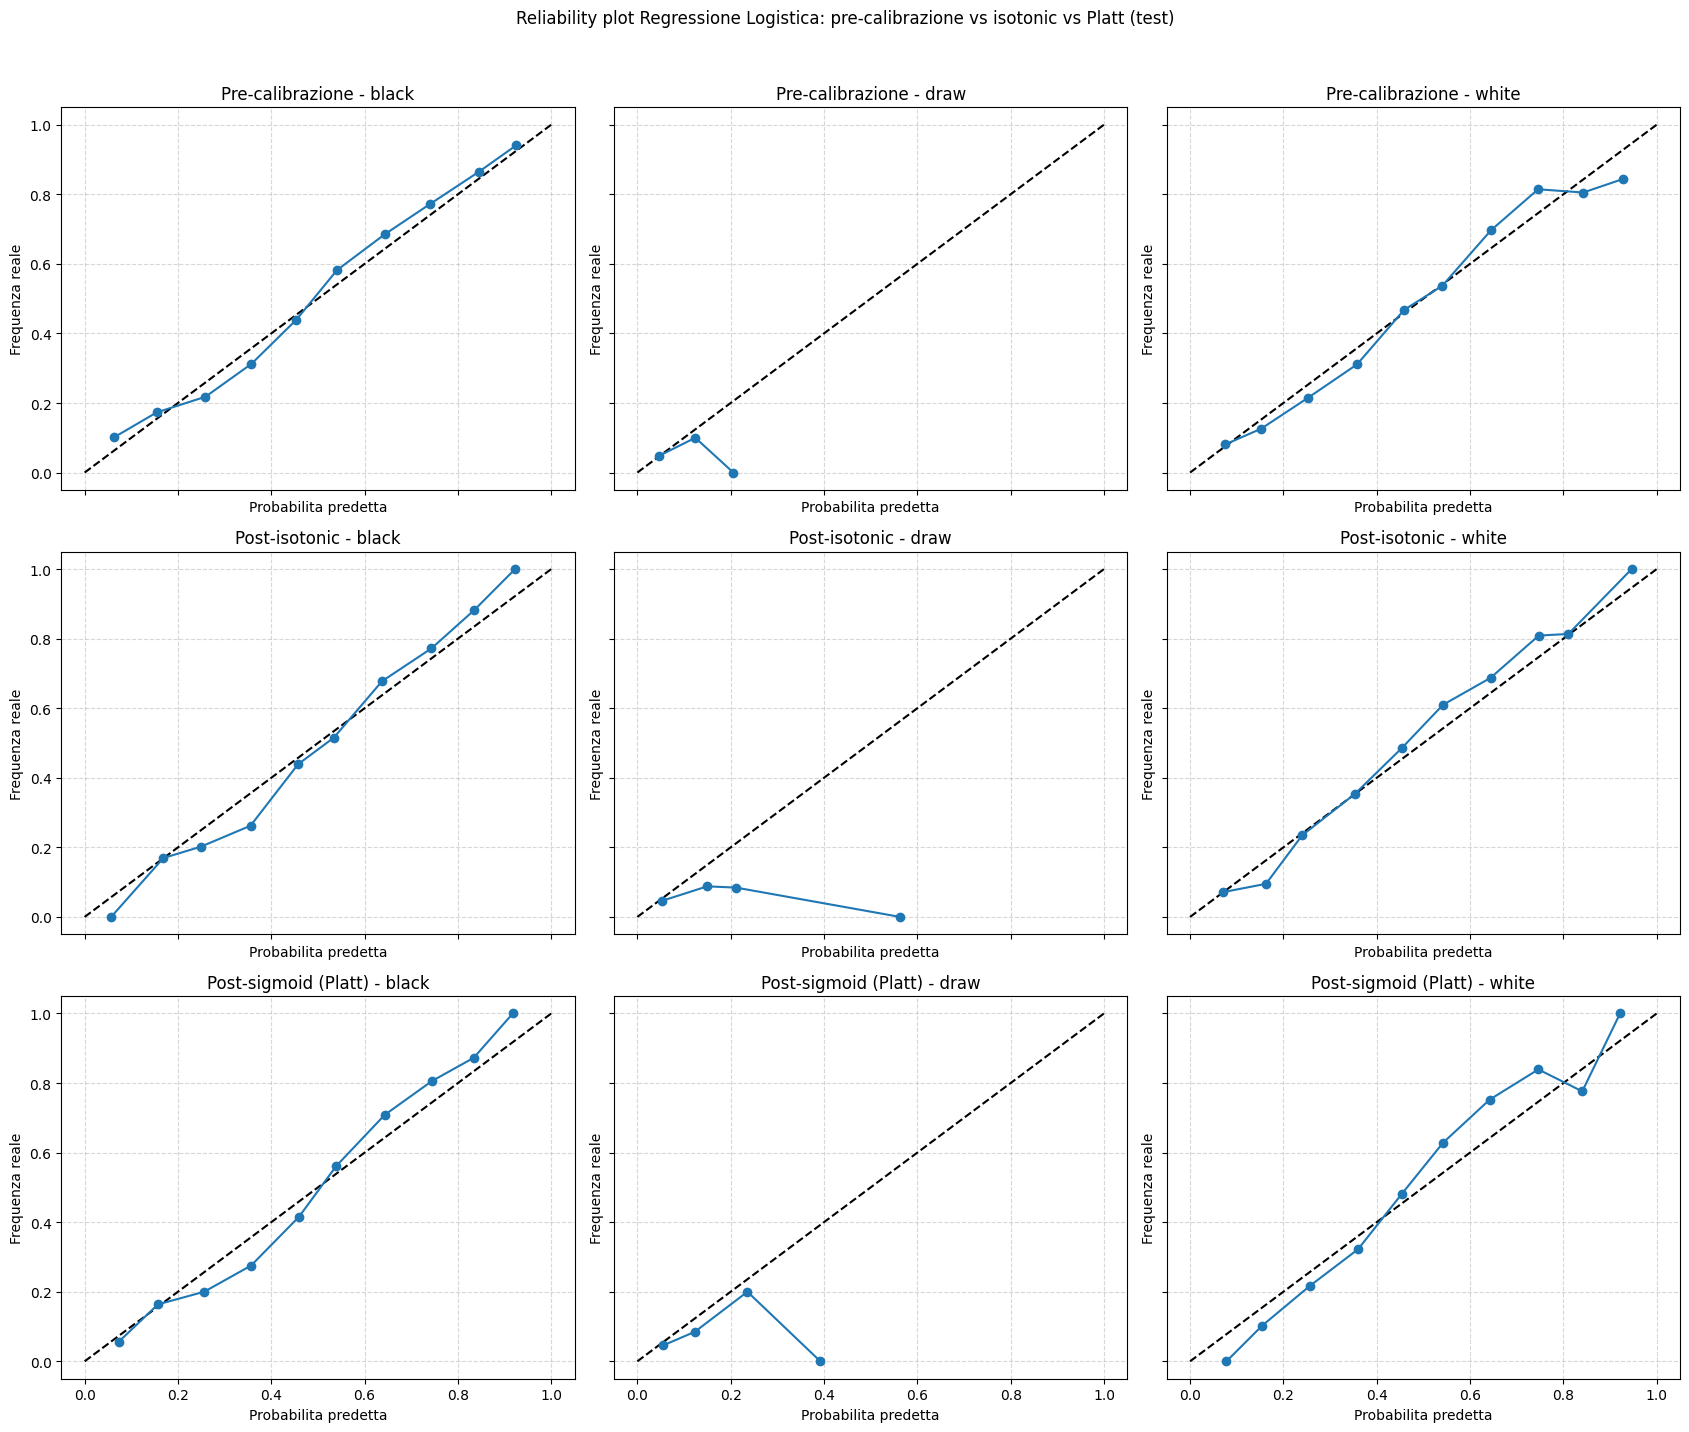

In [57]:
print("--- Reliability plot Regressione Logistica: pre-calibrazione vs isotonic vs Platt ---")

# Griglia 3 righe (pre, isotonic, sigmoid) x 3 colonne (classi), stesso stile della Sezione 5.
figura_calibrazione_lr, assi_calibrazione_lr = plt.subplots(
    nrows=3,
    ncols=len(classi_calibrazione),
    figsize=(17, 14),
    sharex=True,
    sharey=True
)

fasi_calibrazione_lr = [
    ('Pre-calibrazione', probabilita_lr_pre_test_ordinate),
    ('Post-isotonic', probabilita_lr_isotonic_test_ordinate),
    ('Post-sigmoid (Platt)', probabilita_lr_sigmoid_test_ordinate)
]

for indice_fase, (nome_fase, probabilita_fase) in enumerate(fasi_calibrazione_lr):
    for indice_classe, classe in enumerate(classi_calibrazione):
        indicatori_reali = (y_test_ordinato_calibrazione == classe).astype(int)
        probabilita_classe = probabilita_fase[:, indice_classe]
        frequenze_reali, probabilita_medie = calibration_curve(
            indicatori_reali,
            probabilita_classe,
            n_bins=10,
            strategy='uniform'
        )
        asse = assi_calibrazione_lr[indice_fase, indice_classe]
        asse.plot([0, 1], [0, 1], 'k--', label='Calibrazione perfetta')
        asse.plot(probabilita_medie, frequenze_reali, marker='o', label=nome_fase)
        asse.set_title(f'{nome_fase} - {classe}')
        asse.set_xlabel('Probabilita predetta')
        asse.set_ylabel('Frequenza reale')
        asse.grid(True, linestyle='--', alpha=0.5)

figura_calibrazione_lr.suptitle(
    'Reliability plot Regressione Logistica: pre-calibrazione vs isotonic vs Platt (test)', y=1.02
)
figura_calibrazione_lr.tight_layout()
plt.show()


### Interpretazione: calibrazione esplicita della Regressione Logistica

I calibratori isotonic e sigmoid (Platt scaling) vengono fittati sull'intera validation temporale (`X_validazione_modello`/`y_validazione_modello`, 3.079 partite) sul modello scelto (Regressione Logistica, congelata con `FrozenEstimator`, equivalente a `cv='prefit'`) e valutati sul test (`X_test`/`y_test`, 3.905 partite). Questa è l'unica consultazione del test dedicata alla decisione di calibrazione: distinta da quella della Sezione 6 (scelta del modello) e da quella della Sezione 7 (modello binario), ciascuna con un proprio singolo utilizzo del test.

**Nessuna delle due tecniche migliora l'ECE medio.** Pre-calibrazione è **0,0184**; passa a **0,0248** con isotonic e a **0,0364** con sigmoid (Platt): entrambe le tecniche peggiorano la calibrazione della Regressione Logistica, già buona di partenza. Il peggioramento non è uniforme tra le classi: per `black` l'isotonic resta sostanzialmente invariata (0,0298 → 0,0299) mentre il sigmoid peggiora nettamente (→ 0,0455); per `white` entrambe peggiorano (0,0236 → 0,0331 isotonic, → 0,0518 sigmoid); per `draw`, la classe con l'ECE pre-calibrazione più basso in assoluto (0,0018), entrambe le tecniche lo peggiorano di un ordine di grandezza (→ 0,0115 isotonic, → 0,0117 sigmoid). I reliability plot confermano il quadro: le curve pre-calibrazione sono già vicine alla diagonale per `black` e `white`, mentre per `draw` la curva pre-calibrazione è quasi piatta e vicina allo zero per l'estrema rarità della classe; dopo isotonic e sigmoid le curve non migliorano la vicinanza alla diagonale.

**Decisione: nessuna calibrazione viene applicata.** La Regressione Logistica era già ben calibrata sul test (ECE medio 0,0184, ECE `draw` 0,0018); isotonic e Platt scaling sono stati entrambi testati ma nessuno dei due riduce l'ECE, quindi il modello resta non calibrato esplicitamente. Con soli 3.079 esempi di validation per il fit del calibratore e la classe `draw` fortemente minoritaria al suo interno, entrambe le tecniche introducono più rumore di quanto correggano.

**Implicazioni per il prodotto e il matchmaking:** le probabilità della Regressione Logistica possono essere mostrate così come prodotte dal modello, senza un ulteriore livello di calibrazione esplicita. Se in futuro sarà disponibile una nuova finestra di validation più ampia, si potrà rivalutare isotonic o Platt scaling, oltre a tecniche alternative come una cross-validation per il fit del calibratore invece di un singolo split.



#### 6. Confronto e scelta del modello

In [58]:
print("--- 6. Confronto e scelta del modello ---")

# Confronta solo modelli non pesati, addestrati sul train interno e valutati sulla validation
# temporale: la decisione va presa senza consumare l'holdout finale (test).
modelli_principali = {
    'Regressione Logistica': (model_lr, y_proba_lr, y_validazione_modello),
    'Gradient Boosting': (
        model_gb_conservative,
        model_gb_conservative.predict_proba(X_validazione_modello),
        y_validazione_modello
    ),
    'MLPClassifier': (model_mlp, y_proba_mlp, y_validazione_encoded),
    'Random Forest (max_depth=10)': (
        model_rf_md10,
        model_rf_md10.predict_proba(X_validazione_modello),
        y_validazione_modello
    )
}

risultati_confronto_modelli = []

for nome_modello, (modello, probabilita, y_reale) in modelli_principali.items():
    # Porta tutte le probabilita nello stesso ordine: black, draw, white.
    probabilita_ordinate = probabilita_in_ordine_calibrazione(
        nome_modello,
        modello,
        probabilita
    )
    y_reale_ordinato = (
        np.array([classes_ordered[indice] for indice in y_reale])
        if nome_modello == 'MLPClassifier'
        else np.asarray(y_reale)
    )
    predizioni = np.array(classi_calibrazione)[np.argmax(probabilita_ordinate, axis=1)]

    # Calcola le metriche probabilistiche e la classificazione sul medesimo test set.
    logloss_modello = log_loss(
        y_reale_ordinato,
        probabilita_ordinate,
        labels=classi_calibrazione
    )
    brier_modello = float(np.mean([
        brier_score_loss(
            (y_reale_ordinato == classe).astype(int),
            probabilita_ordinate[:, indice]
        )
        for indice, classe in enumerate(classi_calibrazione)
    ]))
    accuracy_modello = accuracy_score(y_reale_ordinato, predizioni)
    ece_per_classe = {
        classe: ece_multiclasse(
            y_reale_ordinato,
            probabilita_ordinate[:, indice],
            classe,
            numero_bin=10
        )[0]
        for indice, classe in enumerate(classi_calibrazione)
    }

    risultati_confronto_modelli.append({
        'Modello': nome_modello,
        'Log Loss': logloss_modello,
        'Brier Score': brier_modello,
        'Accuracy': accuracy_modello,
        'ECE medio': float(np.mean(list(ece_per_classe.values()))),
        'ECE draw': ece_per_classe['draw'],
        'Draw predette': int((predizioni == 'draw').sum())
    })

confronto_modelli = pd.DataFrame(risultati_confronto_modelli).sort_values(
    by=['ECE medio', 'Log Loss']
).reset_index(drop=True)

print("\nTabella riassuntiva dei modelli principali:")
display(confronto_modelli.round(4))

print(
    "\nCriterio di scelta: ECE medio e ECE della classe draw sono prioritari; "
    "Log Loss e Brier Score verificano la qualita complessiva delle probabilita, "
    "mentre Accuracy e Draw predette restano indicatori secondari."
)

--- 6. Confronto e scelta del modello ---

Tabella riassuntiva dei modelli principali:


,Modello,Log Loss,Brier Score,Accuracy,ECE medio,ECE draw,Draw predette
0,Random Forest (max_depth=10),0.8180,0.1667,0.5905,0.0262,0.0153,1
1,Regressione Logistica,0.8115,0.1659,0.5956,0.0262,0.0133,0
2,Gradient Boosting,0.8106,0.1659,0.5956,0.0270,0.0169,5
3,MLPClassifier,0.8424,0.1694,0.5859,0.0346,0.0204,0



Criterio di scelta: ECE medio e ECE della classe draw sono prioritari; Log Loss e Brier Score verificano la qualita complessiva delle probabilita, mentre Accuracy e Draw predette restano indicatori secondari.


### Interpretazione: confronto e scelta del modello

Il confronto e la scelta del modello vengono effettuati sulla validation temporale (`X_validazione_modello`/`y_validazione_modello`), riservando il test a un'unica valutazione finale, riportata subito dopo questa interpretazione.

Il confronto sulla validation mostra differenze molto piccole tra i quattro modelli. Random Forest (max_depth=10) e Regressione Logistica hanno l'ECE medio praticamente identico (rispettivamente `0,0262` e `0,0262`, con una differenza di soli 6 millesimi visibile solo oltre la quarta cifra decimale), seguiti da vicino da Gradient Boosting (`0,0270`); MLPClassifier resta il peggiore (`0,0346`). Sull'ECE della classe `draw`, però, la Regressione Logistica è la migliore (`0,0133`), davanti a Random Forest (`0,0153`) e Gradient Boosting (`0,0169`). Su Log Loss, Brier Score e Accuracy, Gradient Boosting (`0,8106`/`0,1659`/`0,5956`) e Regressione Logistica (`0,8115`/`0,1659`/`0,5956`) sono sostanzialmente alla pari, entrambi leggermente meglio di Random Forest (`0,8180`/`0,1667`/`0,5905`).

- **Regressione Logistica:** è la più interpretabile, ha il miglior ECE per `draw` tra i quattro modelli ed è sostanzialmente alla pari con Gradient Boosting su Log Loss, Brier Score, Accuracy ed ECE medio. Non predice mai `draw` nella classificazione hard.
- **Gradient Boosting:** Log Loss e Brier Score minimamente migliori della logistica (differenza di 0,0009 sulla Log Loss, non significativa), ma ECE medio ed ECE `draw` leggermente peggiori; è l'unico, tra questi tre, a predire occasionalmente `draw` (5 volte su 176 patte reali).
- **Random Forest (max_depth=10):** ECE medio quasi identico alla logistica, ma ECE `draw` peggiore e Log Loss/Brier/Accuracy leggermente peggiori; predice `draw` una sola volta.
- **MLPClassifier:** il peggiore su tutte le metriche; la maggiore complessità della rete non porta benefici con queste feature.

### Decisione (basata sulla validation)

Il criterio dichiarato dà priorità all'ECE medio e all'ECE della classe `draw`. Random Forest e Regressione Logistica sono sostanzialmente pari sull'ECE medio, ma la Regressione Logistica ha un ECE `draw` chiaramente migliore e Log Loss/Brier/Accuracy leggermente migliori di Random Forest; rispetto a Gradient Boosting, la Regressione Logistica ha ECE medio ed ECE `draw` migliori, a fronte di una Log Loss praticamente identica (differenza di 9 millesimi, non rilevante).

**Il modello candidato è la Regressione Logistica**, non il Gradient Boosting conservativo. Il criterio numerico che la favorisce (il miglior ECE sulla classe `draw`) si basa su differenze piccole e su appena 176 patte reali osservate in validation: da solo è quindi un segnale statisticamente debole, non un margine netto. La scelta si appoggia perciò anche su un criterio non numerico: a parità sostanziale di prestazioni probabilistiche, la Regressione Logistica è il modello più semplice e interpretabile tra i tre migliori, un vantaggio pratico che pesa quanto il margine osservato sull'ECE. Le differenze tra i tre modelli migliori (Regressione Logistica, Gradient Boosting, Random Forest) restano comunque contenute e non sono state accompagnate da una stima dell'incertezza (intervalli di confidenza, bootstrap): la scelta va quindi considerata solida ma non definitiva, e andrebbe riconfermata su più finestre temporali indipendenti.

La classe `draw` resta un limite strutturale: sulla validation nessuno dei modelli scelti (Regressione Logistica) predice mai una patta in modo hard. Questo conteggio non dimostra una capacità adeguata di riconoscere le patte; la gestione della classe `draw` resta rimandata al post-rilascio, come già discusso nella Sezione 4.

**Decisione per prodotto e matchmaking:** adottare la Regressione Logistica come modello candidato, con Gradient Boosting come alternativa quasi equivalente da tenere in considerazione. La valutazione finale e indipendente sul test, riportata subito sotto, conferma se questa scelta regge su dati mai usati per selezionarla.


##### Valutazione finale sul test (holdout, usato una sola volta)

Il modello scelto sulla validation (Regressione Logistica) viene ora valutato sul test temporale (`X_test`/`y_test`) **una sola volta**, come stima indipendente delle prestazioni. Da questo punto in poi il test non va più consultato per tuning, selezione o calibrazione.

--- 6. Valutazione finale sul test (holdout, usata una sola volta) ---

Modello valutato sul test (holdout finale): Regressione Logistica
Log Loss: 0.7876
Log Loss baseline 'senza modello' (frequenze del train interno): 0.8528
Brier Score (media su classi): 0.1622
Accuracy: 0.6064
ECE medio: 0.0184
ECE draw: 0.0018
Partite predette come 'draw': 0 su 189 patte reali nel test


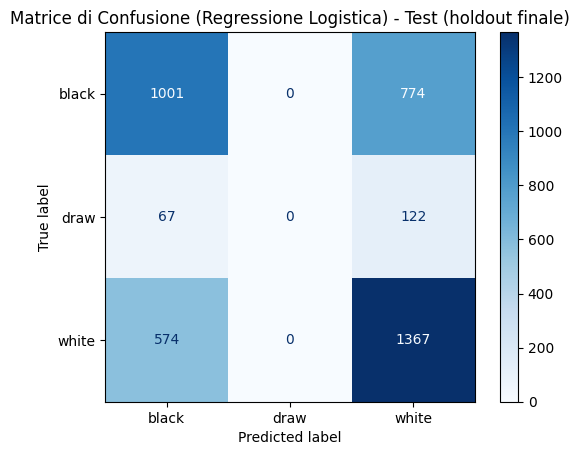

In [59]:
print("--- 6. Valutazione finale sul test (holdout, usata una sola volta) ---")

# Il modello scelto sulla validation e' la Regressione Logistica (vedi confronto sopra).
# Questa e' l'UNICA valutazione sul test in questo notebook per la scelta multiclass:
# da qui in avanti il test non va piu' consultato per tuning, selezione o calibrazione.
modello_scelto_nome = 'Regressione Logistica'
modello_scelto = model_lr

y_pred_finale_test = modello_scelto.predict(X_test)
y_proba_finale_test = modello_scelto.predict_proba(X_test)
probabilita_finale_test_ordinate = probabilita_in_ordine_calibrazione(
    modello_scelto_nome, modello_scelto, y_proba_finale_test
)
y_test_ordinato_finale = np.asarray(y_test)

logloss_finale_test = log_loss(y_test_ordinato_finale, probabilita_finale_test_ordinate, labels=classi_calibrazione)
brier_finale_test = float(np.mean([
    brier_score_loss((y_test_ordinato_finale == classe).astype(int), probabilita_finale_test_ordinate[:, indice])
    for indice, classe in enumerate(classi_calibrazione)
]))
accuracy_finale_test = accuracy_score(y_test_ordinato_finale, y_pred_finale_test)
ece_finale_test = {
    classe: ece_multiclasse(
        y_test_ordinato_finale, probabilita_finale_test_ordinate[:, indice], classe, numero_bin=10
    )[0]
    for indice, classe in enumerate(classi_calibrazione)
}
ece_medio_finale_test = float(np.mean(list(ece_finale_test.values())))
draw_predette_finale_test = int((y_pred_finale_test == 'draw').sum())
draw_reali_finale_test = int((y_test_ordinato_finale == 'draw').sum())

# Baseline "senza modello": predizione costante pari alla distribuzione del target nel train interno,
# per contestualizzare la Log Loss del modello scelto rispetto a un riferimento banale.
distribuzione_train_interno = y_train_modello.value_counts(normalize=True).reindex(classi_calibrazione)
probabilita_baseline_frequenze = np.tile(
    distribuzione_train_interno.to_numpy(), (len(y_test_ordinato_finale), 1)
)
logloss_baseline_frequenze = log_loss(
    y_test_ordinato_finale, probabilita_baseline_frequenze, labels=classi_calibrazione
)

print(f"\nModello valutato sul test (holdout finale): {modello_scelto_nome}")
print(f"Log Loss: {logloss_finale_test:.4f}")
print(f"Log Loss baseline 'senza modello' (frequenze del train interno): {logloss_baseline_frequenze:.4f}")
print(f"Brier Score (media su classi): {brier_finale_test:.4f}")
print(f"Accuracy: {accuracy_finale_test:.4f}")
print(f"ECE medio: {ece_medio_finale_test:.4f}")
print(f"ECE draw: {ece_finale_test['draw']:.4f}")
print(f"Partite predette come 'draw': {draw_predette_finale_test} su {draw_reali_finale_test} patte reali nel test")

matrice_finale_test = confusion_matrix(y_test_ordinato_finale, y_pred_finale_test, labels=classi_calibrazione)
ConfusionMatrixDisplay(
    confusion_matrix=matrice_finale_test, display_labels=classi_calibrazione
).plot(cmap=plt.cm.Blues)
plt.title(f'Matrice di Confusione ({modello_scelto_nome}) - Test (holdout finale)')
plt.grid(False)
plt.show()


### Interpretazione: valutazione finale sul test

Sul test temporale, mai consultato prima in questa selezione, la Regressione Logistica ottiene `Log Loss = 0,7876`, `Brier Score = 0,1622`, `Accuracy = 0,6064`, `ECE medio = 0,0184` e `ECE draw = 0,0018`. Come riferimento di contesto, una previsione costante basata solo sulle frequenze delle classi nel train interno (nessun modello, nessuna informazione sulla singola partita) otterrebbe su questo stesso test una Log Loss di `0,8528`: il modello scelto migliora questo riferimento banale di circa 0,065, un margine reale ma che lascia comunque molta incertezza residua, coerente con uno sport dove anche il favorito netto può perdere. Questi valori sono coerenti con quelli osservati sulla validation (`Log Loss = 0,8115`, `Brier Score = 0,1659`, `Accuracy = 0,5956`, `ECE medio = 0,0262`, `ECE draw = 0,0133`): il test conferma prestazioni leggermente migliori, senza segnali di un forte overfitting alla validation. Come sulla validation, il modello non predice mai `draw` in modo hard (0 patte su 189 reali nel test): il limite sulla classe minoritaria è confermato anche sull'holdout finale, coerentemente con la decisione della Sezione 4 di non forzare la classe `draw` con pesi o resampling.

**Conclusione:** la scelta della Regressione Logistica, presa sulla validation, regge sul test indipendente. Il Gradient Boosting conservativo resta un'alternativa quasi equivalente (le differenze tra i due sono nell'ordine del millesimo su Log Loss/Brier sia in validation sia, presumibilmente, sul test) e può essere riconsiderato in futuro con più dati o una stima dell'incertezza. Questa è l'unica valutazione svolta sul test in questa selezione multiclass: da qui in avanti (Sezione 7 e Step successivi) il test resta un riferimento di verifica finale, non uno strumento di tuning.


In [60]:
print("--- Verifica della validation temporale multiclass predisposta a inizio Step 3 ---")

# Il train interno, la validazione e lo scaler corretto sono gia' stati definiti nella
# Sezione 0, prima della Sezione 1: qui si verifica solo la coerenza, senza ricalcolare lo split
# (rifarlo su X_train adesso lo dividerebbe una seconda volta, perche' X_train e' gia' il train interno).
if X_train_modello.shape[0] != X_train.shape[0]:
    raise ValueError("X_train_modello non coincide con il train interno definito a inizio Step 3.")

print(f"Train interno: {X_train_modello.shape[0]} partite")
print(f"Validation temporale: {X_validazione_modello.shape[0]} partite")
print(f"Test holdout esistente: {X_test.shape[0]} partite; non usarlo per selezione o calibrazione.")

--- Verifica della validation temporale multiclass predisposta a inizio Step 3 ---
Train interno: 12313 partite
Validation temporale: 3079 partite
Test holdout esistente: 3905 partite; non usarlo per selezione o calibrazione.


### Nota metodologica: protocollo di validazione per la Sezione 7 e per lo Step 4

Da qui in avanti (Sezione 7 e Step successivi) vale il seguente protocollo: lo scaler è rifittato solo sul train interno (`X_train_modello`/`y_train_modello`, Sezione 0 dello Step 3); la validation (`X_validazione_modello`/`y_validazione_modello`) è usata nelle Sezioni 1-6 per la selezione dei modelli, la gestione dello sbilanciamento e la calibrazione; il test (`X_test`/`y_test`) è consultato una sola volta, alla fine della Sezione 6, come valutazione indipendente del modello scelto (Regressione Logistica), e non va più riutilizzato per tuning, selezione o calibrazione.

#### 7. Versione binaria per il matchmaking: rilevazione degli upset

--- 7. Versione binaria per il matchmaking: rilevazione degli upset ---
Partite train usate: 11670; partite test usate: 3689.
Tasso di upset train: 34.28%; test: 36.49%.

Regressione Logistica
Soglia upset scelta sul validation set temporale: 0.38
Log Loss: 0.6236
Brier Score: 0.2175
Precision upset: 0.4561
Recall upset: 0.7481
ROC-AUC: 0.6528
Matrice di confusione [righe = reale, colonne = predetto; 0 = partita normale, 1 = upset]:


,Predetto normale,Predetto upset
Reale normale,1142,1201
Reale upset,339,1007


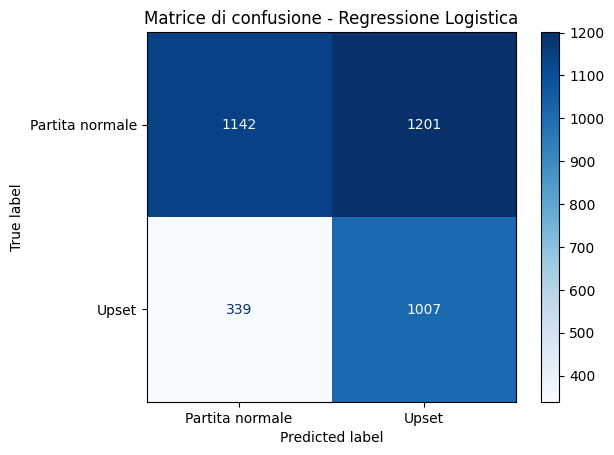


Gradient Boosting
Soglia upset scelta sul validation set temporale: 0.33
Log Loss: 0.6264
Brier Score: 0.2187
Precision upset: 0.4251
Recall upset: 0.8351
ROC-AUC: 0.6419
Matrice di confusione [righe = reale, colonne = predetto; 0 = partita normale, 1 = upset]:


,Predetto normale,Predetto upset
Reale normale,823,1520
Reale upset,222,1124


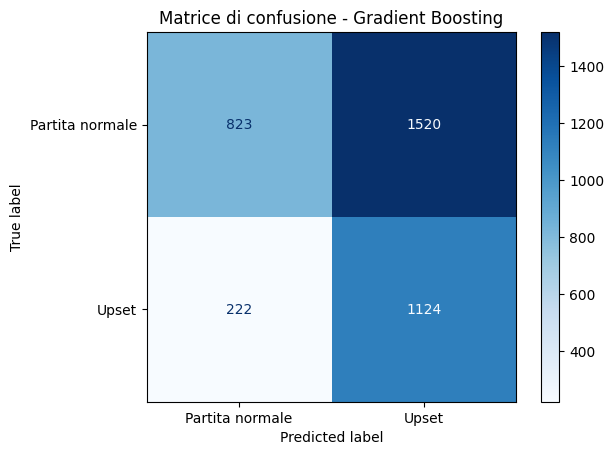


Confronto finale dei modelli binari sul test temporale:


,Modello,Soglia scelta,Log Loss,Brier Score,Precision upset,Recall upset,ROC-AUC,Falsi positivi,Falsi negativi
0,Regressione Logistica,0.38,0.6236,0.2175,0.4561,0.7481,0.6528,1201,339
1,Gradient Boosting,0.33,0.6264,0.2187,0.4251,0.8351,0.6419,1520,222



La soglia non e 0.50: e stata scelta minimizzando un costo operativo sul validation set, assegnando ai falsi negativi un costo doppio rispetto ai falsi positivi.


In [61]:
from sklearn.metrics import (
    brier_score_loss,
    confusion_matrix,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

print("--- 7. Versione binaria per il matchmaking: rilevazione degli upset ---")

# Costruisce il target binario solo sulle partite decisive con rating diversi.
def costruisci_dataset_upset(df_partite, X_feature, y_esito):
    maschera_ammissibile = (
        (df_partite['winner'] != 'draw')
        & (df_partite['white_rating'] != df_partite['black_rating'])
    )
    indici_ammissibili = maschera_ammissibile[maschera_ammissibile].index
    dati = df_partite.loc[indici_ammissibili]
    indici_comuni = indici_ammissibili.intersection(X_feature.index).intersection(y_esito.index)
    feature = X_feature.loc[indici_comuni]
    esiti = y_esito.loc[indici_comuni]

    favorito = np.where(
        dati.loc[indici_comuni, 'white_rating'] > dati.loc[indici_comuni, 'black_rating'],
        'white',
        'black'
    )
    favorite_wins = (esiti.to_numpy() == favorito).astype(int)
    upset = 1 - favorite_wins
    return feature, pd.Series(favorite_wins, index=feature.index), pd.Series(upset, index=feature.index)


X_train_upset, y_train_favorite_wins, y_train_upset = costruisci_dataset_upset(
    df_train, X_train, y_train
)
X_test_upset, y_test_favorite_wins, y_test_upset = costruisci_dataset_upset(
    df_test, X_test, y_test
)

print(
    f"Partite train usate: {len(X_train_upset)}; partite test usate: {len(X_test_upset)}."
)
print(
    f"Tasso di upset train: {y_train_upset.mean() * 100:.2f}%; "
    f"test: {y_test_upset.mean() * 100:.2f}%."
)

# Seleziona la soglia su una coda temporale interna al train, senza usare il test.
split_validazione = int(len(X_train_upset) * 0.75)
X_train_interno = X_train_upset.iloc[:split_validazione]
y_train_interno = y_train_favorite_wins.iloc[:split_validazione]
X_validazione = X_train_upset.iloc[split_validazione:]
y_validazione_upset = y_train_upset.iloc[split_validazione:]

modelli_upset = {
    'Regressione Logistica': LogisticRegression(
        solver='lbfgs', random_state=42, max_iter=1000
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Un falso negativo nasconde un'anomalia; il suo costo è fissato a 2 volte un falso positivo.
costo_falso_positivo = 1.0
costo_falso_negativo = 2.0
soglie = np.arange(0.10, 0.91, 0.01)
risultati_upset = []

for nome_modello, modello in modelli_upset.items():
    modello.fit(X_train_interno, y_train_interno)
    probabilita_upset_validazione = 1 - modello.predict_proba(X_validazione)[:, list(modello.classes_).index(1)]
    costi = []

    for soglia in soglie:
        predizioni_upset = (probabilita_upset_validazione >= soglia).astype(int)
        falsi_positivi = ((predizioni_upset == 1) & (y_validazione_upset.to_numpy() == 0)).sum()
        falsi_negativi = ((predizioni_upset == 0) & (y_validazione_upset.to_numpy() == 1)).sum()
        costi.append(
            costo_falso_positivo * falsi_positivi
            + costo_falso_negativo * falsi_negativi
        )

    soglia_scelta = float(soglie[int(np.argmin(costi))])

    # Riaddestra il modello sull'intero train temporale prima della valutazione finale.
    modello.fit(X_train_upset, y_train_favorite_wins)
    indice_vittoria_favorito = list(modello.classes_).index(1)
    probabilita_vittoria_favorito = modello.predict_proba(X_test_upset)[:, indice_vittoria_favorito]
    probabilita_upset_test = 1 - probabilita_vittoria_favorito
    predizioni_upset_test = (probabilita_upset_test >= soglia_scelta).astype(int)

    matrice = confusion_matrix(y_test_upset, predizioni_upset_test, labels=[0, 1])
    risultati_upset.append({
        'Modello': nome_modello,
        'Soglia scelta': soglia_scelta,
        'Log Loss': log_loss(y_test_favorite_wins, modello.predict_proba(X_test_upset), labels=modello.classes_),
        'Brier Score': brier_score_loss(y_test_favorite_wins, probabilita_vittoria_favorito),
        'Precision upset': precision_score(y_test_upset, predizioni_upset_test, zero_division=0),
        'Recall upset': recall_score(y_test_upset, predizioni_upset_test, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test_upset, probabilita_upset_test),
        'Falsi positivi': int(matrice[0, 1]),
        'Falsi negativi': int(matrice[1, 0])
    })

    print(f"\n{nome_modello}")
    print(f"Soglia upset scelta sul validation set temporale: {soglia_scelta:.2f}")
    print(f"Log Loss: {risultati_upset[-1]['Log Loss']:.4f}")
    print(f"Brier Score: {risultati_upset[-1]['Brier Score']:.4f}")
    print(f"Precision upset: {risultati_upset[-1]['Precision upset']:.4f}")
    print(f"Recall upset: {risultati_upset[-1]['Recall upset']:.4f}")
    print(f"ROC-AUC: {risultati_upset[-1]['ROC-AUC']:.4f}")
    print("Matrice di confusione [righe = reale, colonne = predetto; 0 = partita normale, 1 = upset]:")
    display(pd.DataFrame(matrice, index=['Reale normale', 'Reale upset'], columns=['Predetto normale', 'Predetto upset']))

    ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=['Partita normale', 'Upset']
    ).plot(cmap=plt.cm.Blues)
    plt.title(f'Matrice di confusione - {nome_modello}')
    plt.grid(False)
    plt.show()

confronto_upset = pd.DataFrame(risultati_upset)
print("\nConfronto finale dei modelli binari sul test temporale:")
display(confronto_upset.round(4))

print(
    "\nLa soglia non e 0.50: e stata scelta minimizzando un costo operativo sul validation set, "
    "assegnando ai falsi negativi un costo doppio rispetto ai falsi positivi."
)

### Interpretazione: versione binaria per il matchmaking

Il problema binario considera solo le partite decisive con rating diversi: `favorite_wins = 1` significa che il giocatore con rating più alto ha vinto, mentre `upset = 1` significa che il favorito ha perso. Sono state utilizzate 11.670 partite nel train (il solo train interno definito nella Sezione 0) e 3.689 nel test temporale; il tasso di upset passa dal 34,28% nel train al 36,49% nel test. Questo scostamento è un segnale di possibile drift da monitorare, non un problema già risolto. Il confronto disponibile copre soltanto questi due periodi e non verifica se la variazione persista su più finestre temporali.

La soglia non è stata fissata a 0,5 per nessuno dei due modelli, ed è stata scelta separatamente per ciascuno sulla stessa coda di validazione interna al train, minimizzando lo stesso costo assunto in cui un falso negativo, cioè non segnalare un vero upset, pesa il doppio di un falso positivo. **Il rapporto FN/FP = 2 è un'assunzione di analisi, non un dato o requisito di prodotto.** Poiché il punteggio prodotto dai due modelli non è identico, la soglia ottimale risulta diversa tra i modelli: **0,38** per la regressione logistica e **0,33** per il Gradient Boosting. Se il costo relativo cambia, entrambe le soglie vanno ricalibrate sulla validation temporale.

Sul test, la regressione logistica ottiene Log Loss `0,6236`, Brier Score `0,2175` e ROC-AUC `0,6528`; con la soglia scelta (`0,38`) raggiunge precision `0,4561` e recall `0,7481`. Poiché il tasso base di upset nel test è `36,49%`, una precisione del `45,6%` equivale a un **lift di circa 10 punti percentuali** rispetto a una segnalazione casuale: tra le partite segnalate dalla logistica, la quota di upset reali è circa un terzo più alta di quella osservata nell'insieme di tutte le partite. Il Gradient Boosting ha Log Loss `0,6264`, Brier Score `0,2187` e ROC-AUC `0,6419`, con soglia `0,33`, precision `0,4251` e recall `0,8351` (lift di circa 8 punti sullo stesso tasso base). La logistica discrimina leggermente meglio (ROC-AUC più alta) ed è più precisa, ma il Gradient Boosting intercetta più upset (recall più alta): la scelta tra i due dipende da quanto pesano, in pratica, i falsi allarmi rispetto agli upset mancati.

**Uso operativo nel matchmaking:** la probabilità di upset può attivare una revisione, un controllo antifrode o un'analisi aggregata degli abbinamenti; non dovrebbe bloccare automaticamente la partita. Con le rispettive soglie, la logistica segnala 1.201 partite normali come sospette e manca 339 upset; il Gradient Boosting ne segnala 1.520 e ne manca 222. Se il team ha capacità di controllo limitata, la logistica riduce il volume di falsi allarmi; se il rischio di non intercettare anomalie è prioritario, il Gradient Boosting ne manca meno, ma a costo di più segnalazioni da verificare.

**Limite e monitoraggio del drift:** l'aumento osservato del tasso di upset è un rischio per l'affidabilità del modello binario nel tempo, ma non è stato verificato su più periodi e non consente di concludere da solo che il drift sia persistente. Dopo il deployment occorre monitorare il tasso di upset e le metriche del modello (Log Loss, Brier, ROC-AUC, precision, recall e tassi di falsi positivi e falsi negativi) su finestre temporali successive. Se il tasso di upset continua a crescere o le prestazioni peggiorano, le soglie decisionali e le metriche di riferimento dovranno essere rivalutate e ricalibrate usando dati recenti e costi aggiornati del team matchmaking.

Queste soglie sono una decisione di prodotto, non una proprietà universale del modello: devono essere ricalibrate usando costi reali, budget operativo e nuovi periodi temporali.

#### Nota metodologica: interpretazione delle metriche binarie

Il confronto e la scelta dei modelli multiclass (famiglia di modello, pesi di classe, calibrazione) usano `X_validazione_modello`/`y_validazione_modello` (Sezioni 1-6). Le soglie upset (**0,38 per la regressione logistica, 0,33 per il Gradient Boosting**) sono selezionate su una coda di validazione interna al train (`X_validazione`/`y_validazione_upset`, ricavata dal solo train temporale), senza mai consultare `X_test`/`y_test`. Il test viene quindi consultato una sola volta anche per il modello binario, per la valutazione finale riportata sopra (Log Loss, Brier, precision, recall, ROC-AUC, matrice di confusione): è un holdout distinto da quello multiclass della Sezione 6, ma anch'esso usato una sola volta e mai per tuning o selezione. Le metriche binarie riportate sono quindi una stima indipendente delle prestazioni, coerente con il protocollo adottato in tutta la Sezione 3; restano comunque relative a un solo periodo temporale e andranno riconfermate su nuove finestre indipendenti.


In [62]:
from pathlib import Path
import joblib

print("--- Salvataggio dei modelli e dello scaler per lo Step 4 ---")

cartella_artifact = Path("artifacts")
cartella_artifact.mkdir(parents=True, exist_ok=True)

modelli_da_salvare = {
    "logistic_regression_multiclass": model_lr,
    "gradient_boosting_conservative_multiclass": model_gb_conservative,
    "mlp_classifier_multiclass": model_mlp,
    "random_forest_max_depth_10_multiclass": model_rf_md10,
    "logistic_regression_upset_binary": modelli_upset["Regressione Logistica"],
    "gradient_boosting_upset_binary": modelli_upset["Gradient Boosting"],
    "standard_scaler": scaler,
}

for nome, oggetto in modelli_da_salvare.items():
    percorso_file = cartella_artifact / f"{nome}.joblib"
    joblib.dump(oggetto, percorso_file)
    print(f"Salvato: {percorso_file.resolve()}")

print("Nessun mapping di target encoding è stato salvato.")

--- Salvataggio dei modelli e dello scaler per lo Step 4 ---
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\logistic_regression_multiclass.joblib
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\gradient_boosting_conservative_multiclass.joblib
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\mlp_classifier_multiclass.joblib
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\random_forest_max_depth_10_multiclass.joblib
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\logistic_regression_upset_binary.joblib
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\gradient_boosting_upset_binary.joblib
Salvato: C:\Users\enzol\Documents\VS-CODE\PROJECT WORK\project_work_2\artifacts\standard_scaler.joblib
Nessun mapping di target encoding è stato salvato.


## STEP 4 — Interpreta e conclusioni



### Limiti metodologici (da leggere prima delle sezioni seguenti)

Prima di procedere con l'interpretazione, è utile richiamare lo stato metodologico dei risultati prodotti nello Step 3:

- **Selezione sulla validation, test come holdout finale.** Il confronto tra le famiglie di modelli (logistica, alberi, MLP), la scelta dei pesi di classe e la valutazione della calibrazione (Sezioni 1-5 dello Step 3) usano `X_validazione_modello`/`y_validazione_modello`. Il test temporale (`X_test`/`y_test`) è consultato una sola volta per la scelta multiclass, alla fine della Sezione 6, e una sola volta per il modello binario, nella Sezione 7: in entrambi i casi come valutazione finale indipendente, mai per tuning o selezione.
- **Scaler.** Lo `StandardScaler` è rifittato solo sul train interno (`X_train_modello`/`y_train_modello`, Sezione 0 dello Step 3) e poi applicato (transform) a train interno, validazione (`X_validazione_modello`/`y_validazione_modello`) e test. Tutti i modelli dello Step 3 sono addestrati sul train interno con questo scaler.
- **Calibrazione isotonic e Platt testate, non applicate.** Nella Sezione 5 dello Step 3, isotonic e Platt scaling vengono fittati sull'intera validation e valutati sul test per il modello scelto (Regressione Logistica): entrambi peggiorano l'ECE medio rispetto al modello non calibrato (da 0,0184 a 0,0248 con isotonic e a 0,0364 con Platt), quindi non vengono applicati. Questo confronto usa però l'ECE calcolato sul test: la decisione di non calibrare è quindi presa guardando l'holdout finale, e non è indipendente da esso come le altre decisioni di questa sezione. Il modello scelto resta non calibrato esplicitamente; una calibrazione andrà rivalutata su una futura finestra di validation più ampia.
- **Da qui in avanti.** `X_test`/`y_test` non vanno più usati per tuning, selezione o calibrazione: sono già stati consultati una volta per ciascuna valutazione finale (multiclass e binaria) e non vanno riconsultati. Per una stima su dati completamente nuovi servirà una futura finestra temporale mai consultata.
- **Limiti che restano aperti.** La scelta del modello e le soglie operative si basano su un singolo split temporale train/validazione/test, senza stima dell'incertezza (intervalli di confidenza, bootstrap) né conferma su più finestre temporali indipendenti. Le decisioni andranno riconfermate su nuovi periodi e la calibrazione andrà rivalutata prima di un uso in produzione.

--- STEP 4, sezione 1: importanza delle feature per la Regressione Logistica ---


,Feature,black,draw,white,Importanza (|coeff| medio)
0,rating_diff,-0.3611,0.0134,0.3477,0.2407
1,white_rating,-0.1715,0.0363,0.1352,0.1143
2,rated,0.0743,-0.1715,0.0972,0.1143
3,black_rating,0.1459,0.0242,-0.1700,0.1134
4,rating_min,-0.0323,0.1327,-0.1003,0.0884
5,rating_max,0.0063,-0.0651,0.0588,0.0434
6,increment,-0.0430,0.0320,0.0110,0.0287
7,time_total_estimate,-0.0200,0.0398,-0.0198,0.0265
8,time_base,-0.0042,0.0353,-0.0312,0.0236
9,rating_mean,-0.0133,0.0336,-0.0203,0.0224


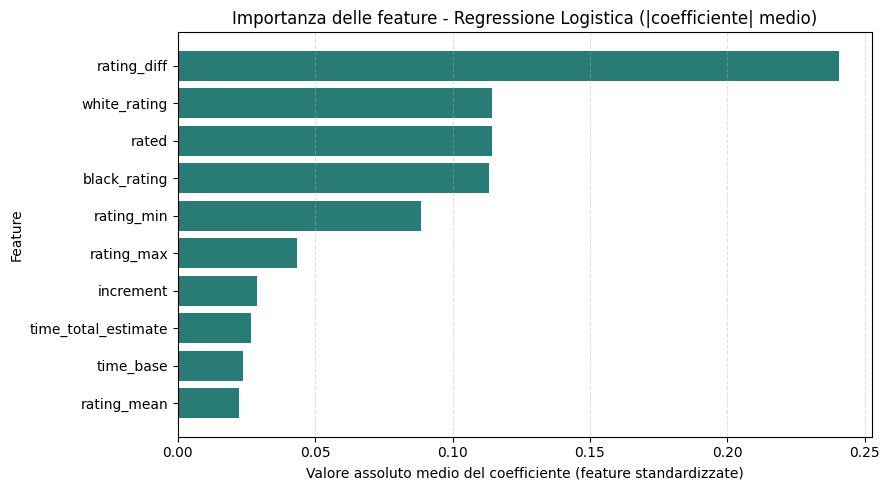

Modello: Regressione Logistica addestrata su 12,313 partite del train interno; validation riservata: 3,079 partite. Il test non è stato utilizzato.


In [63]:
import matplotlib.pyplot as plt
import pandas as pd

print("--- STEP 4, sezione 1: importanza delle feature per la Regressione Logistica ---")

# Riusa il modello scelto (model_lr) e le feature del train interno, gia' definiti nello Step 3:
# nessun riaddestramento, nessuna feature diversa da quelle usate per la scelta del modello.
feature_names_step4 = list(X_train.columns)
classi_step4_coeff = model_lr.classes_

# model_lr.coef_ ha forma (n_classi, n_feature): un coefficiente per ciascuna feature e classe,
# calcolato su feature gia' standardizzate (stesso scaler del train interno, Step 3 Sezione 0).
# La Regressione Logistica e' il modello scelto; i coefficienti indicano l'effetto di ciascuna
# feature sulla probabilita' di ogni classe. Le feature numeriche sono standardizzate (stessa
# scala) e quindi confrontabili tra loro; 'rated' resta invece binaria (0/1) e non standardizzata,
# quindi il suo coefficiente non e' sulla stessa scala di quelli standardizzati.
feature_importance_step4 = pd.DataFrame(
    model_lr.coef_.T,
    index=feature_names_step4,
    columns=classi_step4_coeff
)
feature_importance_step4['Importanza (|coeff| medio)'] = (
    feature_importance_step4[classi_step4_coeff].abs().mean(axis=1)
)
feature_importance_step4 = feature_importance_step4.sort_values(
    'Importanza (|coeff| medio)', ascending=False
).reset_index().rename(columns={'index': 'Feature'})

display(feature_importance_step4.style.format(
    {colonna: '{:.4f}' for colonna in feature_importance_step4.columns if colonna != 'Feature'}
))

# Visualizza le feature dalla meno alla più importante secondo l'importanza sintetica.
figura_importanza, asse_importanza = plt.subplots(figsize=(9, 5))
ordine_grafico = feature_importance_step4.sort_values('Importanza (|coeff| medio)', ascending=True)
asse_importanza.barh(
    ordine_grafico['Feature'], ordine_grafico['Importanza (|coeff| medio)'], color='#287c75'
)
asse_importanza.set_title("Importanza delle feature - Regressione Logistica (|coefficiente| medio)")
asse_importanza.set_xlabel("Valore assoluto medio del coefficiente (feature standardizzate)")
asse_importanza.set_ylabel('Feature')
asse_importanza.grid(axis='x', linestyle='--', alpha=0.4)
figura_importanza.tight_layout()
plt.show()

print(
    f"Modello: Regressione Logistica addestrata su {len(X_train):,} partite del train interno; "
    f"validation riservata: {len(X_validazione_modello):,} partite. Il test non è stato utilizzato."
)

### Interpretazione: importanza delle feature per la Regressione Logistica

La Regressione Logistica è il modello scelto (Step 3, Sezione 6); i coefficienti indicano l'effetto di ciascuna feature sulla probabilità di ciascuna classe (`black`, `draw`, `white`), a parità delle altre feature. Le feature numeriche sono standardizzate (stessa scala, Step 3 Sezione 0): un coefficiente più alto in valore assoluto corrisponde a un effetto più marcato per un aumento di una deviazione standard. La feature `rated` resta invece binaria (0/1, non standardizzata): il suo coefficiente descrive l'effetto del passaggio da partita non rated a rated e non è direttamente confrontabile in scala con quello delle feature standardizzate, pur restando confrontabile in ordine di grandezza.

`rating_diff` è di gran lunga la feature con l'effetto più marcato (|coefficiente| medio **0,2407**): un coefficiente negativo per `black` (-0,3611) e positivo per `white` (0,3477) conferma che un `rating_diff` più alto (Bianco più forte) aumenta la probabilità di vittoria del Bianco e riduce quella del Nero, mentre l'effetto su `draw` è quasi nullo (0,0134). Questo è coerente con l'EDA, dove le probabilità di vittoria cambiavano nettamente al variare della differenza di rating.

Seguono, con effetto medio molto più contenuto e simile tra loro, `white_rating` (0,1143), `rated` (0,1143), `black_rating` (0,1134) e `rating_min` (0,0884). Il coefficiente di `rated` è marcatamente negativo per `draw` (-0,1715): le partite rated hanno una probabilità di patta stimata più bassa, a parità di rating, rispetto alle partite non rated, coerentemente con il tasso di patte osservato nell'EDA (rated 4,45% contro non rated 5,92%). `white_rating` e `black_rating` hanno segni opposti sulle rispettive classi di vittoria (positivo per la propria vittoria, negativo per quella dell'avversario), come atteso.

Le variabili temporali (`increment` 0,0287, `time_total_estimate` 0,0265, `time_base` 0,0236) e `rating_mean` (0,0224) hanno l'effetto medio più basso. Questo è coerente con l'associazione quasi nulla tra `time_base` e patta osservata nell'EDA (Spearman rho = 0,030): il modello non attribuisce alle variabili temporali un ruolo rilevante nella previsione dell'esito. Le aperture non compaiono perché escluse dal modello pre-partita: diventano disponibili solo dopo l'inizio della partita.

Queste importanze descrivono associazioni lineari a parità delle altre variabili, non un effetto causale isolato. Le feature di rating sono correlate tra loro (`rating_diff`, `rating_mean`, `rating_min`, `rating_max`, `white_rating`, `black_rating` derivano tutte dagli stessi due valori), quindi il loro contributo può ripartirsi tra variabili ridondanti; il segnale dominante di `rating_diff` resta comunque il più chiaro e stabile. L'analisi si riferisce al modello scelto, addestrato sulle 12.313 partite del train interno; validation e test non sono stati usati per calcolarla.

#### 2. Collegamento con l'EDA

Nel complesso, i coefficienti della Regressione Logistica confermano il quadro emerso dall'EDA. `rating_diff` ha l'effetto medio più marcato (|coefficiente| **0,2407**), con segno negativo su `black` e positivo su `white`: coerentemente con le curve esplorative, al crescere del vantaggio di rating del Bianco aumenta la probabilità di sua vittoria e diminuisce quella del Nero. Il modello conferma quindi che, tra le informazioni disponibili nella lobby, il rating relativo è il segnale predittivo principale. Non elimina però gli upset osservati nell'EDA: un rating favorevole orienta la previsione, ma non determina con certezza l'esito.

Il coefficiente di `rated` (effetto medio 0,1143, guidato soprattutto da un coefficiente marcatamente negativo su `draw`, -0,1715) è coerente con l'EDA, dove le partite rated mostravano un tasso di patte più basso delle non rated (4,45% contro 5,92%). Il coefficiente lineare isola con chiarezza questo effetto specifico sulla classe `draw`.

Il contributo più contenuto delle variabili temporali (`increment`, `time_total_estimate`, `time_base`, effetto medio tra 0,024 e 0,029) è coerente con l'EDA, dove la relazione tra `time_base` e patta era quasi nulla in ampiezza (Spearman rho = 0,030). Questo risultato riguarda l'associazione monotona con le patte, mentre il coefficiente del modello sintetizza il contributo alla previsione di tutte le classi: non dimostra che tempo e incremento siano inutili per ogni esito o sottogruppo.

Le aperture mostrano un'associazione statisticamente significativa ma debole nel sottoinsieme delle dieci più frequenti (V di Cramér = 0,122). Non sono state incluse nel modello pre-partita perché non sono disponibili prima dell'inizio della partita. La loro assenza dai coefficienti, quindi, è una scelta coerente con il caso d'uso, non evidenza che le aperture non possano contribuire a una previsione aggiornata dopo le prime mosse.

Per il prodotto, il risultato suggerisce di fondare la probabilità pre-partita soprattutto sul divario di rating, con un ruolo secondario ma non trascurabile del flag `rated` per la classe `draw`. Le probabilità devono comunque mantenere spazio per esiti inattesi e patte: il coefficiente di una feature descrive un'associazione media a parità delle altre variabili, non la qualità della probabilità per ciascuna classe (il limite su correlazione tra feature e causalità è già discusso nella Sezione 1).

### 3. Indicazioni operative per il matchmaking

#### Cosa dicono i rating

Il divario di rating è il segnale più forte disponibile nel modello multiclass: il giocatore con rating più alto ha in media maggiori probabilità di vincere. Non è però una garanzia: nell'EDA circa il 35% delle partite decisive con rating diversi è terminato con la vittoria del giocatore dal rating più basso. Anche nel modello binario il tasso di upset osservato sale dal 34,28% nel train al 36,49% nel test temporale. Il rating è quindi utile per stimare e confrontare gli abbinamenti, ma non basta per prevedere con certezza l'esito.

Il modello binario distingue gli upset solo in misura limitata: sul test la ROC-AUC è 0,653 per la regressione logistica e 0,642 per il Gradient Boosting.

#### Quali fattori spiegano gli upset

La sezione binaria ha usato rating, differenza e riepiloghi dei rating, formato temporale e indicatore `rated`, ma non ne ha calcolato l'importanza specifica per gli upset. Non è quindi possibile stabilire dai risultati disponibili quali fattori, oltre al rating, li distinguano meglio. L'importanza del coefficiente di `rating_diff` nel modello multiclass (Regressione Logistica) riguarda la previsione generale dell'esito e non dimostra che il divario di rating spieghi da solo le sorprese.

Inoltre, le feature di rating sono correlate o derivate l'una dall'altra: le loro importanze possono spartirsi il segnale, lo stesso limite già discusso per i coefficienti nella Sezione 1. Un upset non prova un errore di abbinamento, né tantomeno una frode.

#### Come leggere le soglie 0,38 e 0,33

Le soglie segnalano per revisione una partita quando il modello stima almeno il 38% (regressione logistica) o il 33% (Gradient Boosting) di probabilità che vinca il giocatore con rating più basso. Ciascuna soglia è stata scelta separatamente sulla validation temporale minimizzando un costo assunto in cui un upset mancato pesa il doppio di una partita normale segnalata per errore. Quel rapporto 2:1 è un'ipotesi di lavoro, non un costo misurato dal team. Le due soglie sono diverse perché i due modelli producono punteggi di probabilità diversi, non perché rappresentino politiche diverse.

Sul test consultato, la regressione logistica ha intercettato circa il 75% degli upset, con precisione circa il 46%; il Gradient Boosting ha intercettato circa l'84%, con precisione circa il 43%. In altre parole, entrambe le soglie generano un numero rilevante di falsi allarmi: sono state segnalate come sospette 1.201 partite normali dalla logistica e 1.520 dal Gradient Boosting, mancando rispettivamente 339 e 222 upset reali. Non è stata mostrata una verifica di calibrazione specifica del modello binario: le soglie vanno trattate come soglie sul punteggio probabilistico di ciascun modello, non come garanzia che quella percentuale di partite segnalate sarà davvero un upset.

Le soglie valgono solo per partite decisive con rating diversi; patte e rating uguali sono esclusi. Non sono soglie universali: cambiando il costo relativo dei falsi allarmi, degli upset mancati o la capacità di revisione, vanno ricalibrate.

#### Suggerimenti concreti

- Usare il divario di rating come criterio principale per cercare partite equilibrate, ma definire eventuali fasce ammissibili insieme al tempo di attesa in coda: questi risultati non individuano una distanza di rating ottimale.
- Non bloccare né modificare automaticamente un abbinamento perché supera la soglia (0,38 per la logistica, 0,33 per il Gradient Boosting). Usare il segnale, al massimo, per ordinare una coda di controlli umani o per analisi aggregate; se il volume è eccessivo, limitare la revisione ai casi con probabilità più alta.
- Prima di adottare la soglia, concordare con il team quanti controlli può sostenere e quanto costa davvero un falso allarme rispetto a un upset mancato. Verificare poi i tassi osservati per fasce di divario di rating e su periodi successivi.
- Quando si esamina un caso, controllare anche il contesto disponibile agli operatori, per esempio la stabilità recente del rating e la storia di gioco. Questi elementi non sono stati testati come spiegazioni degli upset in questa analisi.
- Monitorare nel tempo volume di segnalazioni, upset effettivi tra i casi segnalati e upset mancati. Se cambiano i giocatori, i rating o il tasso di upset, riesaminare soglia e regole usando nuovi dati temporali.

**Indicazione finale:** i rating aiutano a costruire abbinamenti ragionevolmente equilibrati, ma lasciano un'incertezza sostanziale. Le soglie 0,38 e 0,33 sono strumenti sperimentali di priorità per la revisione, non un criterio automatico di matchmaking; prima dell'uso operativo servono costi reali, una verifica indipendente e un controllo della calibrazione binaria.

### 4. Indicazioni operative per il prodotto

#### Cosa mostrare prima della partita

Mostrare le tre probabilità dello stesso modello multiclass: vittoria del Bianco, vittoria del Nero e patta. Devono sommare al 100% ed essere presentate come stime, non come pronostici certi. È meglio non mostrare soltanto l'esito più probabile: una partita può avere un favorito e conservare comunque una possibilità concreta di sorpresa o di patta.

Il modello scelto per le probabilità è la **Regressione Logistica** (Step 3, Sezione 6), selezionata sulla validation temporale per il miglior ECE sulla classe `draw` (0,0133) a parità sostanziale di ECE medio, Log Loss e Brier Score con il Gradient Boosting. Sul test, valutato una sola volta come stima indipendente, ottiene Log Loss 0,7876, Brier Score 0,1622, ECE medio 0,0184 ed ECE `draw` 0,0018: valori coerenti con quelli osservati in validation, senza segnali di un forte overfitting alla validation stessa. Il Gradient Boosting resta un'alternativa quasi equivalente su Log Loss e Brier Score.

#### La patta va mostrata come probabilità

La patta è rara nel dataset, circa il 4,7% degli esiti. La Regressione Logistica, come gli altri modelli non pesati, non la sceglie mai come esito singolo nella classificazione hard (0 patte predette su 189 reali nel test). Questo non è un motivo per nascondere la patta o impostarne la probabilità a zero. Il prodotto dovrebbe mantenere visibile la sua probabilità insieme alle due probabilità di vittoria, senza trasformarla in una decisione secca.

Un ECE basso per la patta (0,0133 in validation, 0,0018 sul test) è un segnale favorevole sulla coerenza media delle probabilità nei gruppi analizzati, ma non prova che il modello sappia individuare bene le singole partite che finiranno patte: la classe è rara e i risultati dipendono da come vengono raggruppate le probabilità. Nel notebook sono state testate anche una calibrazione esplicita isotonic e una Platt scaling della Regressione Logistica (Step 3, Sezione 5), fittate sull'intera validation e valutate sul test: entrambe peggiorano l'ECE medio (da 0,0184 a 0,0248 con isotonic e a 0,0364 con Platt), quindi non vengono applicate. Prima di definire le probabilità “calibrate” per il pubblico occorre comunque verificarle su una nuova finestra di validation più ampia.

#### Come comunicare l'incertezza

Usare un testo semplice, per esempio: “Stima pre-partita basata soprattutto sui rating; descrive risultati medi in situazioni simili e non garantisce l'esito di questa partita.” Mostrare tutte e tre le percentuali con arrotondamento ragionevole, evitando decimali che suggeriscano una precisione non dimostrata. Una differenza ridotta tra le probabilità di Bianco e Nero comunica una partita più equilibrata; anche un favorito netto può perdere.

Non mostrare intervalli di confidenza o un indicatore di certezza individuale: il notebook non li ha calcolati. La stima può essere meno affidabile per giocatori con pochi dati e quando cambiano nel tempo giocatori, rating o formati di partita.

#### Limiti da dichiarare

- Il segnale principale è il divario di rating; le altre variabili pre-partita aggiungono un contributo più contenuto. Le aperture non sono incluse perché non sono disponibili prima dell'inizio.
- La patta è poco frequente e rimane difficile da riconoscere come esito singolo, anche quando la sua probabilità viene mostrata.
- Le metriche riportate provengono da un singolo split temporale train/validazione/test, senza stima dell'incertezza (intervalli di confidenza, bootstrap) né conferma su più finestre temporali indipendenti.
- I dati mostrano possibili cambiamenti nel tempo, già osservati nel tasso di upset tra train e test (Sezione 7): un segnale da monitorare, non la prova che il cambiamento continuerà.

**Indicazione per il rilascio:** presentare le probabilità come stime sperimentali, non come probabilità già certificate. Prima di promuoverle a informazione affidabile per tutti i giocatori, valutarle su una nuova finestra temporale indipendente e verificare separatamente la qualità della probabilità di patta.

### 5. Valore nel tempo del modello

#### Cosa ha imparato il modello da questa fotografia

Il modello descrive le partite contenute nel dataset e nel periodo rappresentato: non apprende una regola valida per sempre. La lezione più chiara è che il divario fra i rating dei due giocatori è il segnale più utile per stimare l'esito. Le variabili sul tempo di gioco e il fatto che una partita sia rated aggiungono informazioni più limitate. Il modello non usa aperture o identità dei giocatori e non conosce cambiamenti successivi nella piattaforma.

La verifica temporale disponibile è limitata: il tasso di upset osservato cambia già tra train e test (Sezione 7) e la variabilità delle feature legate al tempo è cambiata. Sono segnali da tenere d'occhio, ma non bastano a dimostrare una tendenza stabile.

#### Cambiamenti possibili e impatto atteso

| Cambiamento | Impatto atteso | Perché e cosa tenere presente |
|:--|:--|:--|
| Evoluzione del sistema di rating | **Alto** | Se cambiano il calcolo o la velocità di aggiornamento dei rating, lo stesso divario numerico potrebbe non rappresentare più lo stesso vantaggio. Poiché il modello si basa soprattutto sul divario di rating, le sue probabilità potrebbero diventare meno affidabili. |
| Nuove aperture di moda | **Basso per il modello attuale; potenzialmente medio per un modello futuro** | Le aperture non sono incluse nella previsione pre-partita, quindi la loro popolarità non cambia direttamente gli input. Potrebbe esserci un effetto indiretto se cambia anche il tipo di giocatori o di partite. Un modello che usa le prime mosse andrebbe valutato separatamente. |
| Cambio della base utenti | **Alto** | L'ingresso o l'uscita di gruppi di giocatori, o una diversa distribuzione dei livelli, può cambiare sia i rating sia il modo in cui questi si collegano agli esiti. Il modello potrebbe funzionare diversamente per nuovi giocatori o per una comunità con livello medio diverso. |
| Introduzione di varianti di gioco | **Alto se le varianti vengono mescolate alle partite standard** | Regole e distribuzione degli esiti possono cambiare. Il modello è stato costruito sui dati analizzati e non ha una feature che distingua le varianti: non andrebbe applicato automaticamente a partite con regole diverse. Servono identificazione chiara e validazione, probabilmente con modelli o valutazioni separate. |
| Miglioramenti negli strumenti anti-cheating | **Incerto; impatto potenzialmente medio** | Possono cambiare gli esiti registrati, i rating nel tempo e il numero di partite anomale. Il dataset non contiene etichette che identifichino frodi o l'effetto degli strumenti anti-cheating, quindi non è possibile quantificare l'impatto né interpretare un upset come prova di frode. |

**In sintesi:** il valore del modello dipende dal fatto che rating, giocatori e condizioni delle partite future restino abbastanza simili a quelli osservati. Il rischio maggiore riguarda cambiamenti nella scala dei rating o nella composizione degli utenti; le aperture hanno un impatto diretto limitato perché non sono usate, mentre le varianti richiedono particolare cautela. Gli impatti sopra sono valutazioni di rischio, non effetti misurati dal notebook.

### 6. Piano concreto di monitoraggio e ri-allenamento

Il monitoraggio deve verificare due cose diverse: se gli input che arrivano assomigliano ancora a quelli usati per addestrare il modello e, quando l'esito della partita è noto, se le probabilità erano affidabili. La Regressione Logistica, il modello scelto, non è ancora un modello certificato per la produzione: le metriche disponibili derivano da un singolo split temporale train/validazione/test. Prima del rilascio va quindi raccolta una nuova finestra temporale mai usata per selezionare o calibrare il modello.

#### Cosa monitorare e quando

| Controllo | Frequenza proposta | Cosa osservare e come intervenire |
|:--|:--|:--|
| Qualità e distribuzione degli input | Ogni giorno, con riepilogo settimanale | Controllare rating, divario di rating, tempo di gioco e quota di partite rated. Controllare anche valori mancanti, valori fuori dai limiti attesi e cambiamenti nel formato dei dati. Un cambiamento è un avviso da indagare, non una ragione sufficiente per ri-allenare. |
| Qualità delle probabilità dopo l'esito | Ogni settimana su una finestra mobile di 28 giorni | Calcolare Log Loss e Brier Score complessivi e per classe (Bianco, Nero, patta), oltre all'ECE per classe. Valori più bassi indicano in generale probabilità migliori; confrontarli sempre con la stessa finestra di riferimento e con un intervallo di incertezza. |
| Upset | Ogni settimana, sugli esiti già conclusi | Seguire la percentuale di vittorie del giocatore con rating più basso, contando solo partite decisive con rating diversi, e confrontarla con le attese del modello binario. Riportare anche precisione, richiamo e falsi allarmi della soglia operativa. Separare, quando possibile, per fasce di divario di rating e tipo di partita. |
| Revisione complessiva | Ogni mese | Il team prodotto e dati decide se mantenere il modello, approfondire un segnale di drift o avviare una nuova versione candidata. |

Per non trarre conclusioni da pochi casi, produrre il rapporto delle metriche sugli esiti quando la finestra contiene almeno **5.000 partite concluse e 200 patte**. Se non raggiunge questi numeri, allargare la finestra fino a un massimo di 8 settimane e indicare chiaramente che la stima è meno precisa. Le metriche per classe sono essenziali: un buon risultato complessivo non deve nascondere probabilità di patta peggiorate.

#### Rilevare cambiamenti nei dati

Confrontare ogni giorno i dati in arrivo con una fotografia di riferimento raccolta prima del rilascio, osservando distribuzioni e quote di categorie, non soltanto le medie. Per esempio, verificare se si spostano i rating o i divari di rating, se cambiano i controlli di tempo più comuni, o se varia la percentuale di partite rated. Un indicatore semplice come il PSI può aiutare a riassumere lo spostamento: usare **0,10** come avviso e **0,20** come allarme iniziale, da confermare sul comportamento storico dei dati. Un allarme persistente per due controlli settimanali richiede un'indagine; da solo non dimostra che il modello sia peggiorato.

Quando gli esiti sono disponibili, verificare se lo spostamento degli input è accompagnato da un peggioramento di Log Loss, Brier o ECE, in particolare per la patta e nei gruppi di partite più rilevanti. Se aumenta il tasso di upset, controllare se cresce anche la quota di upset mancati dal modello. Un cambiamento degli input senza un calo della qualità richiede sorveglianza, non necessariamente un nuovo addestramento.

#### Quando ri-allenare

Adottare una regola **ibrida**: revisione programmata ogni tre mesi e revisione anticipata se un problema persiste. Non sostituire il modello in automatico solo perché è arrivata la data o perché una distribuzione si è spostata.

Come soglie iniziali da discutere con il team, avviare una nuova versione candidata se, per due finestre settimanali consecutive con dati sufficienti, Log Loss o Brier peggiorano di oltre il **10%** rispetto alla baseline indipendente, oppure l'ECE supera **0,03** in una o più classi. Un aumento del PSI oltre 0,20 per due verifiche settimanali è un motivo per indagare e può contribuire alla decisione, ma non sostituisce il controllo sugli esiti. Questi valori sono regole operative provvisorie, non soglie ricavate dall'analisi del notebook: vanno ratificati e, dopo aver raccolto dati di produzione, adeguati alla normale variabilità osservata.

La nuova versione va addestrata con dati recenti e confrontata su partite successive non usate per addestrarla, sceglierla o calibrarla. Se il problema riguarda solo una popolazione o un formato, valutare prima una soluzione mirata e verificare che i dati siano sufficienti, anziché aggiornare indiscriminatamente tutte le previsioni.

#### Confronto champion/challenger

1. **Champion:** il modello attualmente in produzione, congelato durante il confronto. **Challenger:** una nuova versione candidata, addestrata senza usare la finestra di confronto.
2. Eseguire entrambi sugli stessi incontri futuri in modalità di prova, senza mostrare ancora le stime del challenger agli utenti. Attendere gli esiti e confrontare Log Loss, Brier ed ECE complessivi e per classe, più tasso di upset, precisione, richiamo e falsi allarmi per la parte binaria.
3. Sostituire il champion solo se il challenger migliora in modo credibile almeno una metrica probabilistica principale, non peggiora in modo rilevante le altre, e non danneggia la calibrazione della patta o i gruppi principali. Quantificare l'incertezza della differenza, per esempio con intervalli di confidenza su confronti appaiati; non scegliere sulla base di una piccola oscillazione casuale.
4. Se supera il confronto, distribuire il challenger prima a una quota limitata di partite, continuando a controllare le stesse metriche. Conservare la possibilità di tornare rapidamente al champion se i risultati peggiorano.

**Decisione operativa:** fino a quando non esiste una baseline su dati futuri indipendenti, il modello attuale non va dichiarato champion definitivo. Il piano privilegia controlli frequenti dei dati, verifiche periodiche delle probabilità per ciascun esito e sostituzioni solo dopo un confronto controllato, invece di aggiornamenti automatici.

### Sintesi conclusiva dello STEP 4

- Nei dati analizzati, il divario di rating è il segnale più forte; gli altri segnali sono più deboli e le patte restano difficili da riconoscere come esito singolo.
- La Regressione Logistica è il modello scelto (Step 3, Sezione 6): ha il miglior ECE per la classe `draw` in validation (0,0133) e prestazioni praticamente equivalenti al Gradient Boosting su Log Loss, Brier Score ed ECE medio; sul test, consultato una sola volta, conferma Log Loss 0,7876, Brier Score 0,1622 ed ECE medio 0,0184. Il Gradient Boosting resta un'alternativa quasi equivalente e la scelta andrebbe riconfermata con nuovi dati o con la quantificazione dell'incertezza.
- La calibrazione isotonic e Platt scaling della Regressione Logistica sono state testate (Step 3, Sezione 5) ma non applicate: entrambe peggiorano l'ECE medio sul test (da 0,0184 a 0,0248 con isotonic e a 0,0364 con Platt); la Regressione Logistica era già ben calibrata.
- Prima del rilascio, verificare e calibrare su una finestra temporale indipendente le tre probabilità: vittoria del Bianco, vittoria del Nero e patta.
- Il prodotto dovrebbe presentarle come stime, non come pronostici certi, mantenendo visibile la probabilità di patta.
- Il matchmaking può usare la probabilità di upset per ordinare le verifiche, non per bloccare automaticamente gli abbinamenti.
- I limiti principali restano i possibili cambiamenti nel tempo, l'incertezza non quantificata nel confronto tra modelli e la difficoltà nel prevedere le patte.
- Monitorare ogni settimana Log Loss, Brier, ECE per classe e tasso di upset; controllare ogni giorno eventuali cambiamenti negli input.
- Riesaminare il modello ogni trimestre o prima se le metriche superano le soglie concordate; promuovere un challenger solo dopo un confronto temporale controllato con il champion.

### Limiti residui e lavoro futuro

Oltre ai limiti metodologici già dichiarati all'inizio dello Step 4, restano alcuni limiti tecnici noti, non risolti per limiti di tempo e da affrontare in un lavoro futuro:

- **Valori hardcoded nelle interpretazioni Markdown.** Cifre come `0,2407` (importanza |coeff| medio di `rating_diff`), `946` (patte predette dalla logistica con `class_weight='balanced'`), `12.313` (partite del train interno) e `0,38`/`0,33` (soglie upset) sono scritte come testo fisso nelle celle di interpretazione, non generate dinamicamente da variabili. Se una cella a monte viene rieseguita con dati o parametri diversi, questi numeri possono diventare silenziosamente disallineati rispetto all'output reale, senza alcun controllo automatico di coerenza. Limite noto, non risolto per limiti di tempo.
- **Colonna fantasma `'opening_family'` nella drop-list dello Step 2.** La lista `columns_to_drop` usata nella sezione di encoding/scaling include `'opening_family'`, una colonna mai creata in nessuna cella precedente. Il `drop(..., errors='ignore')` evita l'errore, ma si tratta di un residuo di codice non ripulito. Limite noto, non risolto per limiti di tempo.
- **Stato globale mutabile di `df`.** Durante l'EDA il DataFrame `df` viene modificato più volte in-place (es. `rating_difference`, `rating_diff_bin`, `time_base`, `increment`), e queste colonne si propagano implicitamente in `df_train`/`df_test` dopo lo split, per poi essere ripulite più avanti. Il notebook funziona correttamente solo se eseguito in ordine dall'inizio; una riesecuzione parziale o a partire da una cella intermedia può produrre risultati inconsistenti. Limite noto, non risolto per limiti di tempo.
- **Parsing di `increment_code` non quantificato.** La funzione di parsing restituisce `None, None` per i formati non riconosciuti, ma non viene mai contato e riportato quante righe generano valori mancanti in questo passaggio; la verifica di assenza di NaN avviene solo a valle, in modo aggregato. Limite noto, non risolto per limiti di tempo.
- **Incertezza non misurata nel confronto tra modelli.** Le differenze di Log Loss, Brier Score ed ECE tra i modelli candidati (in particolare tra Regressione Logistica e Random Forest (max_depth=10), con ECE medio praticamente identico in validation — 0,0262 contro 0,0262, differenza visibile solo oltre la quarta cifra decimale — pur con Log Loss diversa, 0,8115 contro 0,8180) sono piccole e non sono mai accompagnate da un intervallo di confidenza, da un bootstrap o da un test statistico di confronto appaiato. Non è quindi possibile stabilire se le differenze osservate siano stabili o dovute a variabilità campionaria. Limite noto, non risolto per limiti di tempo.
- **Robustezza temporale verificata su un singolo split.** La stabilità del modello nel tempo è discussa solo a livello di piano di monitoraggio futuro; l'unica evidenza empirica disponibile è il confronto tra un singolo train e un singolo test temporale (es. lo spostamento del tasso di upset dal 34,28% al 36,49%), senza backtesting su più finestre temporali successive all'interno dello storico disponibile. Limite noto, non risolto per limiti di tempo.


## Step 5 — Pipeline serializzabile e funzione di inferenza

### Cosa è stato prodotto

Un artefatto serializzabile depositato nella cartella del progetto, costruito per rendere il
lavoro riproducibile e utilizzabile senza riaprire il notebook. L'artefatto è composto da:

- Una pipeline completa (feature engineering + scaling + modello Regressione Logistica, non
  calibrato) salvata su disco.
- Una funzione di inferenza che, data una nuova partita o un batch di partite con le sole
  informazioni disponibili prima dell'inizio, restituisce le probabilità dei tre esiti
  (white / black / draw) e una decisione.
- Uno schema di versioning degli artefatti (pipeline, soglie, metriche di riferimento) per
  confrontare versioni successive.
- Una documentazione per chi riprende il lavoro.

Il codice di questo step è stato sviluppato e verificato in questo notebook, poi **rimosso** e
spostato in file separati nella stessa cartella del notebook, perché non fa parte dell'analisi
del project work. Nessun modello è stato riaddestrato: la pipeline riusa solo gli oggetti già
addestrati e salvati in `artifacts/` (Regressione Logistica e `StandardScaler`). La calibrazione
isotonic e Platt sono state testate sulla Regressione Logistica (Step 3, Sezione 5) ma non
applicate perché nessuna delle due riduce l'ECE: la pipeline usa quindi il modello non calibrato.

### File prodotti (nella cartella `project_work_2/`)

- `chess_pipeline_utils.py` — trasformatori di feature engineering e scaling.
- `costruisci_pipeline_lr.py` — script che costruisce e salva la pipeline.
- `pipeline_lr.joblib` — pipeline serializzata, pronta all'uso.
- `inference.py` — funzione `predict_proba(input_df)` per fare previsioni.
- `pipeline_doc.md` — documentazione completa.
- `artifacts/` — modelli addestrati (logistica, GB conservativo, RF max_depth=10, MLP, modelli
  binari upset, scaler).
- `artifacts/v1.0/` — versione congelata (pipeline, metriche, soglie).

### Come si usa

La funzione di inferenza accetta sia una singola partita sia un batch di più partite: basta
passare un DataFrame con le colonne grezze disponibili prima della partita (`rated`,
`white_rating`, `black_rating`, `increment_code`). Restituisce un DataFrame con le stesse righe
dell'input e le colonne delle probabilità (`black`, `draw`, `white`) più una colonna `decisione`
(la classe con probabilità massima).

### Come si testa

Eseguire `python inference.py` per un test rapido con due partite di esempio. Per i dettagli
completi su ricaricare la pipeline, usare la funzione e confrontare versioni, vedere
`pipeline_doc.md`.

### Limiti

La pipeline riproduce il modello Regressione Logistica così come descritto negli Step 3 e 4: le
sue metriche di riferimento provengono da una valutazione sul test temporale, consultato una sola
volta come stima indipendente nello Step 3, Sezione 6. Il modello non è calibrato esplicitamente:
isotonic e Platt scaling sono stati testati (Step 3, Sezione 5) ma nessuno dei due riduce l'ECE.

Vedi i "Limiti metodologici" e "Limiti residui" del notebook prima di un uso in produzione.